# RR-EFL / Quick-Adapt: R3 clean rebuild (WIFS 2026, paper 81)

**Version r3-v1, 26 Sep 2026.** A new notebook, written from scratch. Nothing is reused from earlier runs: no features, no splits, no models, no result files. Every CLIP feature is extracted **once**, cached, and reused by later sessions of this notebook only.

## What it does

**1. Data.** Five Kaggle training generators plus one permanently held-out generator (SFHQ-T2I: FLUX.1 + DALL-E 3; SDXL is excluded because SD1.5 is a training source).
- Splits are made on **family groups**:
  - FF++ frames of one video pair share a group;
  - any two images of the same source whose CLIP cosine is ≥ 0.95 (e.g. a face-swap and its original photo, or near-duplicates) share a group.
- A group never spans two splits.

**2. Base models** (14 arms × 3 seeds, same splits, same budget):
- **Reptile:**
  - round-robin / i.i.d. / balanced scheduler;
  - no / uniform / category-aware augmentation;
  - separate **outer AdamW** run to evaluate its impact (the optimiser stated in paper IV-D).
- **Pooled supervised:** learning rates 3e-4, 1e-4, 3e-5, 1e-5, linear probe, batch reuse.
- **Early-stopped diagnostics.**

**3. Zero-shot evaluation:**
- on the held-out generator (against seen-source reals **and** against never-seen LFW reals);
- on DF40 (and DeepSpeak when access exists).

**4. Adaptation** with a small labelled support set, **1,250 episodes**:
- **Quick-Adapt (QA)**, **fine-tuning (FT)** and **fine-tuning + replay (FTR)**, all with the same number of target gradient steps; FTR and QA also share the same number of replay steps;
- a step-size sweep for all three methods (QA's ε; FT/FTR's learning rate), so they are compared as trade-off curves, not single points;
- results at the pre-registered budgets 200 / 600 / 1,250 episodes;
- three rollback modes: off; fixed 5 %; zero-shot rule.

**5. Metrics everywhere:**
- AUC;
- fakes caught;
- reals called real;
- balanced accuracy.

**6. Checks:**
- leakage (family groups, cross-set duplicates);
- file-format shortcuts;
- cost;
- adaptation prefix equivalence;
- invariants of every run.

## Guarantees enforced by code (a violation raises or is printed as FAILED; nothing is silently skipped)

**Splits and data**
1. The held-out generator is never sampled in base training.
2. Splits are fixed by crc32 of family groups; the fingerprint is checked on every session.
3. External targets (DF40 / DeepSpeak) are never used in base training. They are split by identity; support, val and test never share an identity.
4. Adaptation support sets come from the support pool only; retention and rollback are monitored on Kaggle **val**; results are reported on **test**.

**Selection and test access**
5. The test split is locked until all selection (checkpoints, early stops, rollback) is finished.

**Budgets**
6. Every non-early-stopped arm uses 128,000 gradient steps and 2,048,000 per-sample gradients.
7. Adaptation methods use identical target-step counts at every budget, and QA / FTR identical replay-step counts (asserted per row).

**Caching**
8. A cached result is reused only if its data, config, arm definition and base-model hash all match. Otherwise the notebook stops (unless `ALLOW_RETRAIN_ON_MISMATCH`).

In [ ]:
# ============================== SWITCHES ==============================
SMOKE_TEST = False            # True = tiny synthetic data + stub features, to test the pipeline only (results tagged SMOKE)
RUN_BASE = True               # base models (all arms x seeds)
RUN_LFW = True                # never-seen real faces (LFW): false-alarm check of every base / adapted model
RUN_DF40 = True               # DF40 external target (Celeb-DF domain, 6 methods)
RUN_DEEPSPEAK = True         # DeepSpeak v2.0 external target: needs the HF_TOKEN Colab secret + granted access
RUN_MAIN_ADAPT = True         # main adaptation result: K = 15 videos per method, QA / FT / FTR (base models per target: MAIN_ARMS_BY_TARGET)
RUN_K_SWEEP = True            # Reviewer 3: support size K (DF40: K_SWEEP on the sweep arms; DeepSpeak: K_SWEEP_DEEPSPEAK)
RUN_SCALE_SWEEP = True        # step-size sweep on SCALE_TARGETS (DF40): QA eps 0.12/0.35/0.5/1, FT/FTR lr x 0.04/0.12/0.35/0.5 (sweep arms)
RUN_SFHQ_ADAPT = True         # adaptation on the held-out Kaggle generator (high zero-shot target; image level)
RUN_SELF_TESTS = True         # prefix-equivalence + determinism checks of the adaptation code (a few minutes)
ALLOW_RETRAIN_ON_MISMATCH = False  # keep False: a stored result that does not match this notebook stops the run instead of being overwritten
RESULTS_TAG = "final"             # results go to ROOT/runs_final and ROOT/report_final; ROOT/features and the data caches are reused
# =====================================================================

import os, sys, io, re, json, time, math, zlib, glob, random, hashlib, shutil, subprocess, warnings, threading, zipfile
from collections import defaultdict, OrderedDict, Counter
from copy import deepcopy
from concurrent.futures import ThreadPoolExecutor
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
warnings.filterwarnings("ignore", category=UserWarning)

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and not SMOKE_TEST:
      subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "open_clip_torch", "kaggle>=1.8", "kagglesdk", "huggingface_hub"], check=True)

import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from sklearn.metrics import roc_auc_score
import matplotlib
import matplotlib.pyplot as plt
!pip install -q -U kaggle kagglesdk
!kaggle --version


torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu"
print(f"device={DEVICE} ({GPU_NAME}) torch={torch.__version__} colab={IN_COLAB} smoke={SMOKE_TEST}")

if IN_COLAB and not SMOKE_TEST:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/RREFL_R3"
    DATA_ROOT = "/content/datasets"
else:
    ROOT = os.path.abspath(os.environ.get("RREFL_ROOT", "./r3_smoke" if SMOKE_TEST else "./r3_local"))
    DATA_ROOT = os.path.join(ROOT, "datasets")
assert "RREFL_R2" not in ROOT, "this notebook must not read or write the old R2 folder"
FEAT_DIR, RUNS_DIR, REPORT_DIR = (os.path.join(ROOT, d) for d in ("features", f"runs_{RESULTS_TAG}", f"report_{RESULTS_TAG}"))
for d in (ROOT, DATA_ROOT, FEAT_DIR, RUNS_DIR, REPORT_DIR):
    os.makedirs(d, exist_ok=True)
print("ROOT =", ROOT)
print("results ->", RUNS_DIR, "|", REPORT_DIR)
if DEVICE == "cuda" and "L4" not in GPU_NAME:
    print(f"NOTE: the earlier runs used an NVIDIA L4; on {GPU_NAME} the last digits of the results can differ (this run is then the reference).")
if RUN_DEEPSPEAK and IN_COLAB and not SMOKE_TEST:      # fail now, not after hours of base training
    try:
        from google.colab import userdata
        _hf = userdata.get("HF_TOKEN")
    except Exception as e:
        raise RuntimeError(f"RUN_DEEPSPEAK is on but the HF_TOKEN Colab secret cannot be read ({type(e).__name__}). "
                           "Add it under Secrets (key icon) and switch on Notebook access, then run again.") from e
    if not _hf: raise RuntimeError("RUN_DEEPSPEAK is on but the HF_TOKEN secret is empty")
    from huggingface_hub import HfApi
    HfApi().list_repo_files("faridlab/deepspeak_v2", repo_type="dataset", token=_hf)   # raises here if dataset access is missing
    print("DeepSpeak access: OK")

def h32(s): return zlib.crc32(s.encode("utf-8")) & 0xFFFFFFFF

def to_jsonable(o):
    if isinstance(o, dict): return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_jsonable(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    if isinstance(o, np.bool_): return bool(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return o

def save_json(obj, path):
    tmp = path + ".tmp"
    with open(tmp, "w") as fh: json.dump(to_jsonable(obj), fh, indent=1)
    os.replace(tmp, path)

def load_json(path):
    with open(path) as fh: return json.load(fh)

def tsave(obj, path):
    """Atomic torch.save (a crash never leaves a half-written file that a later session would load)."""
    torch.save(obj, path + ".tmp"); os.replace(path + ".tmp", path)

import inspect
def _fn_source(f):
    f = getattr(f, "__func__", f)                              # staticmethod / classmethod
    return inspect.getsource(f)                                # raises if the source is unavailable (never silently skipped)

def code_hash(*objs):
    """Hash of the source code of the given functions/classes: a stored result is reused only if the code that produced it
    is unchanged (any edit makes the notebook stop instead of mixing old and new results). Classes are hashed method by
    method (inspect.getsource of a class does not work inside Jupyter)."""
    h = hashlib.sha256()
    for o in objs:
        if inspect.isclass(o):
            h.update(o.__name__.encode())
            for k, v in sorted(vars(o).items()):
                if inspect.isfunction(getattr(v, "__func__", v)): h.update(k.encode()); h.update(_fn_source(v).encode())
                elif not k.startswith("__"): h.update(f"{k}={v!r}".encode())
        else:
            h.update(_fn_source(o).encode())
    return h.hexdigest()[:16]

def state_sha(state):
    h = hashlib.sha256()
    for k in sorted(state): h.update(k.encode()); h.update(state[k].detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()[:16]

def mmm(x):
    """median [min, max] (n) over the finite values of x."""
    x = np.asarray([v for v in x if v is not None and not (isinstance(v, float) and math.isnan(v))], dtype=float)
    if len(x) == 0: return "n/a"
    return f"{np.median(x):.3f} [{x.min():.3f}, {x.max():.3f}] (n={len(x)})"

Kaggle CLI 2.2.4
device=cuda (NVIDIA L4) torch=2.11.0+cu130 colab=True smoke=False
Mounted at /content/drive
ROOT = /content/drive/MyDrive/RREFL_R3
results -> /content/drive/MyDrive/RREFL_R3/runs_final | /content/drive/MyDrive/RREFL_R3/report_final
DeepSpeak access: OK


## 1. Configuration: every number used anywhere lives here
The paper's method section is written from this cell and from the auto-generated **methods facts** at the end.

In [ ]:
CFG = dict(
    version="r3-v1",
    split_salt="rrefl-r3-v1",
    fake_cap=9000,                       # max fake images per generator (crc32-ranked, no RNG)
    real_cap_per_source=3000,            # max real images per source that has reals
    split_buckets=(7000, 8500),          # crc32(family group) % 10000: < 7000 train, < 8500 val, else test (70/15/15)
    family_cos=0.97,                     # same source, CLIP cosine >= this -> same family group (never split apart)
    family_max_frac=0.10,                # stop if one family group holds more than this share of a source (chaining check)
    canonical_size=256,                  # every image -> shorter side 256, centre crop 256, BEFORE augmentation
    aug=dict(n_views=2, blur_p=0.5, blur_sigma=(0.5, 1.5), blur_kernels=(3, 5, 7), jpeg_p=0.4, jpeg_q=(50, 85)),
    held_out="SFHQ_T2I",
    exclude_prefixes={"SFHQ_T2I": ["SDXL_"]},   # SDXL excluded from the held-out set (same family as the SD1.5 training source)
    # --- base training (Reptile) ---
    epochs=800, episodes_per_epoch=20, k_shot=8, q_shot=16,
    inner_steps=8, inner_lr=0.005, inner_momentum=0.9, reptile_eps=0.06,
    outer_adamw=dict(lr=3e-4, weight_decay=1e-4, cosine=True),        # used only by the RR_adamw arm (paper IV-D)
    label_smooth=0.05, grad_clip=1.0, dropout=0.4, hidden=256,
    eval_every_epochs=5,
    # --- pooled supervised baseline (matched: same gradient steps, same 8 real + 8 fake per step) ---
    pooled=dict(lr=3e-4, weight_decay=1e-4, cosine=True),
    # --- adaptation (identical for every base model and target) ---
    adapt=dict(episodes=1250, budgets=[200, 600, 1250], new_to_old=1, inner_steps=8, inner_lr=0.006, eps=0.04,
               eval_every=10, ft_lr=0.006, ft_momentum=0.9, draws=3,
               rollback_fixed=0.05,                                   # "fixed" mode: stop if seen-val bal. acc. drops > 5 points
               zs_rule=dict(cut_auc=0.90, tight=0.05, relaxed=0.10),  # "zs" mode: 5 points if zero-shot target-val AUC >= 0.90, else 10
               sfhq_k_per_class=20),
    eps_sweep=[0.12, 0.35, 0.5, 1],        # extra Quick-Adapt eps values (default 0.04 is in the main result)
    lr_scale_sweep=[0.04, 0.12, 0.35, 0.5],  # extra FT / FTR learning-rate multipliers (default 1.0 is in the main result)
    seeds=[42, 1337, 3407],
)
MODES = ["none", "fixed", "zs"]         # rollback modes, all derived from ONE adaptation trajectory (see section 10)

PRIMARY_ARM = "RR_uniform"
ARMS = OrderedDict([
    ("RR_uniform",   dict(trainer="reptile", scheduler="rr",       aug="uniform",  outer="interp")),   # primary
    ("RR_adamw",     dict(trainer="reptile", scheduler="rr",       aug="uniform",  outer="adamw")),    # paper IV-D optimiser
    ("RR_none",      dict(trainer="reptile", scheduler="rr",       aug="none",     outer="interp")),
    ("RR_category",  dict(trainer="reptile", scheduler="rr",       aug="category", outer="interp")),
    ("IID_uniform",  dict(trainer="reptile", scheduler="iid",      aug="uniform",  outer="interp")),
    ("BAL_uniform",  dict(trainer="reptile", scheduler="balanced", aug="uniform",  outer="interp")),
    ("POOLED_lr3e4", dict(trainer="pooled", scheduler="iid", aug="uniform", lr=3e-4)),
    ("POOLED_lr1e4", dict(trainer="pooled", scheduler="iid", aug="uniform", lr=1e-4)),
    ("POOLED_lr3e5", dict(trainer="pooled", scheduler="iid", aug="uniform", lr=3e-5)),
    ("POOLED_lr1e5", dict(trainer="pooled", scheduler="iid", aug="uniform", lr=1e-5)),
    ("POOLED_linear", dict(trainer="pooled", scheduler="iid", aug="uniform", head="linear", lr=1e-3)),  # UnivFD-style probe
    ("POOLED_reuse8", dict(trainer="pooled", scheduler="iid", aug="uniform", lr=3e-4, reuse=8)),       # Reptile's distinct-image count
])
# Pooled learning rate chosen per seed by SEEN-generator validation accuracy (what a practitioner can do): "POOLED_valsel".
POOLED_LR_ARMS = ["POOLED_lr3e4", "POOLED_lr1e4", "POOLED_lr3e5", "POOLED_lr1e5"]
# Early-stopped diagnostics (added after RR_uniform is trained; threshold = median best seen-val of RR_uniform). They borrow
# Reptile's accuracy level, which a practitioner would not have: reported as analysis, never as a baseline.
ES_ARMS = {"ES_mlp": dict(trainer="pooled", scheduler="iid", aug="uniform", lr=3e-4, eval_every_steps=10),
           "ES_linear": dict(trainer="pooled", scheduler="iid", aug="uniform", head="linear", lr=1e-3, eval_every_steps=10)}
# Arms that get the K-sweep and the eps-sweep ("POOLED_valsel" resolves per seed after base training)
SWEEP_ARMS = ["RR_uniform", "RR_adamw", "POOLED_valsel", "POOLED_linear"]
K_MAIN = 15
# ---- Run plan (section 18), chosen by what the paper reports. Fixed for the final run. ----
K_SWEEP = [1, 2, 4, 8, 20]                        # DF40 support-size sweep on the sweep arms (Reviewer 3; K = 15 comes from the main run)
SCALE_TARGETS = ["DF40"]                          # step-size sweep only on DF40 (on DeepSpeak it would add ~3.4 h and is not reported)
MAIN_ARMS_BY_TARGET = {"DF40": "all",             # DF40: every base model (Table I DF40 column, Table II, scheduler/augmentation after adaptation)
                       "DeepSpeak": SWEEP_ARMS,   # DeepSpeak and SFHQ: the base models the paper reports
                       "SFHQ": SWEEP_ARMS}
DEEPSPEAK_K_ARMS = ["RR_uniform", "RR_adamw", "POOLED_valsel"]
K_SWEEP_DEEPSPEAK = [1, 4, 20]                    # last in the run order: the first thing to drop if time runs out

SOURCES = OrderedDict([   # name -> (kaggle slug, local folder, fake subdir, real subdir or None)
    ("StyleGAN_140k",  ("xhlulu/140k-real-and-fake-faces", "k140", "real_vs_fake/real-vs-fake/train/fake", "real_vs_fake/real-vs-fake/train/real")),
    ("ProGAN",         ("unknownmemberf/progan", "progan", "pggan_v1/pggan_v1/train", None)),
    ("OpenForensics",  ("manjilkarki/deepfake-and-real-images", "dfr", "Dataset/Train/Fake", "Dataset/Train/Real")),
    ("FFpp_Deepfakes", ("gradientvoyager/faceforensics-c23-extracted-faces-100k", "ffpp", "dataset_processed_split/train/Deepfakes", "dataset_processed_split/train/Real")),
    ("SD15",           ("mohannadaymansalah/stable-diffusion-dataaaaaaaaa", "sdface", "stable-diffusion-face-dataset/512", None)),
    ("SFHQ_T2I",       ("selfishgene/sfhq-t2i-synthetic-faces-from-text-2-image-models", "sfhqt2i", "images/images", None)),
])
GEN_FAMILY = {"StyleGAN_140k": "gan", "ProGAN": "gan", "OpenForensics": "faceswap", "FFpp_Deepfakes": "faceswap",
              "SD15": "diffusion", "SFHQ_T2I": "diffusion"}   # used ONLY by RR_category (blur/JPEG on GAN fakes only)

if SMOKE_TEST:
    CFG.update(fake_cap=80, real_cap_per_source=50, epochs=10, episodes_per_epoch=8, eval_every_epochs=5, seeds=[42, 1337],
               eps_sweep=[1.0], lr_scale_sweep=[0.04])
    CFG["adapt"].update(episodes=40, budgets=[10, 20, 40], eval_every=10, draws=2, sfhq_k_per_class=6)
    K_SWEEP, K_MAIN, K_SWEEP_DEEPSPEAK = [1, 3], 3, [1, 3]

assert set(GEN_FAMILY) == set(SOURCES) and CFG["held_out"] in SOURCES
A_ = CFG["adapt"]
assert A_["episodes"] == max(A_["budgets"]) and A_["eval_every"] % 2 == 0 and all(b % A_["eval_every"] == 0 for b in A_["budgets"]), \
    "budgets must be multiples of eval_every (even), and the longest budget = episodes"
assert A_["new_to_old"] == 1, "the FT/FTR step matching below assumes alternating target/replay episodes"
_ng = len([s for s in SOURCES if s != CFG["held_out"]])
assert CFG["epochs"] % _ng == 0, "round-robin needs epochs divisible by #generators (each generator held out equally often)"
assert CFG["episodes_per_epoch"] % (_ng - 1) == 0, "episodes per epoch must split equally over the generators not held out"
print(json.dumps(CFG, indent=1, default=str)[:2500])

{
 "version": "r3-v1",
 "split_salt": "rrefl-r3-v1",
 "fake_cap": 9000,
 "real_cap_per_source": 3000,
 "split_buckets": [
  7000,
  8500
 ],
 "family_cos": 0.97,
 "family_max_frac": 0.1,
 "canonical_size": 256,
 "aug": {
  "n_views": 2,
  "blur_p": 0.5,
  "blur_sigma": [
   0.5,
   1.5
  ],
  "blur_kernels": [
   3,
   5,
   7
  ],
  "jpeg_p": 0.4,
  "jpeg_q": [
   50,
   85
  ]
 },
 "held_out": "SFHQ_T2I",
 "exclude_prefixes": {
  "SFHQ_T2I": [
   "SDXL_"
  ]
 },
 "epochs": 800,
 "episodes_per_epoch": 20,
 "k_shot": 8,
 "q_shot": 16,
 "inner_steps": 8,
 "inner_lr": 0.005,
 "inner_momentum": 0.9,
 "reptile_eps": 0.06,
 "outer_adamw": {
  "lr": 0.0003,
  "weight_decay": 0.0001,
  "cosine": true
 },
 "label_smooth": 0.05,
 "grad_clip": 1.0,
 "dropout": 0.4,
 "hidden": 256,
 "eval_every_epochs": 5,
 "pooled": {
  "lr": 0.0003,
  "weight_decay": 0.0001,
  "cosine": true
 },
 "adapt": {
  "episodes": 1250,
  "budgets": [
   200,
   600,
   1250
  ],
  "new_to_old": 1,
  "inner_steps": 8,
  

## 2. Kaggle data: download (first session only), list, cap
Credentials come from Colab **Secrets** (`KAGGLE_USERNAME`, `KAGGLE_KEY`).
- **First session:** downloads everything and writes `items_manifest.json` (every selected image).
- **Later sessions:** skip the ~40 GB download once the manifest **and** the features extracted from it exist.

In [ ]:
IMG_EXT = (".png", ".jpg", ".jpeg", ".webp")
def list_images(d):
    out = []
    for dp, _, fns in os.walk(d):
        out += [os.path.join(dp, f) for f in fns if f.lower().endswith(IMG_EXT)]
    return sorted(out)
def rel(p): return os.path.relpath(p, DATA_ROOT).replace(os.sep, "/")

def make_smoke_data():
    """Synthetic stand-in with the real folder layouts. Includes one planted face-swap 'family' (a fake that is a copy of a
    real with a small edit) to test the family grouping, and SDXL-named held-out files to test the exclusion."""
    rng = np.random.default_rng(0)
    for i, (name, (slug, folder, fake_sub, real_sub)) in enumerate(SOURCES.items()):
        for sub, label in ((fake_sub, 1), (real_sub, 0)):
            if sub is None: continue
            d = os.path.join(DATA_ROOT, folder, sub); os.makedirs(d, exist_ok=True)
            n = 80 if label == 1 else 50
            for j in range(n):
                fn = f"img_{j:04d}.png"
                if name == "FFpp_Deepfakes":
                    a = j // 2; fn = f"{a:03d}_{a ^ 1:03d}_f{j % 2}.png" if label == 1 else f"{a:03d}_f{j % 2}.png"
                if name == "SFHQ_T2I":
                    fn = f"{['FLUX1_dev', 'DALLE3', 'SDXL'][j % 3]}_image_{j:05d}.jpg"
                p = os.path.join(d, fn)
                if os.path.exists(p): continue
                s = 48 + 8 * (i % 3)
                base = rng.integers(60, 200, size=(s, s, 3)).astype(np.uint8)
                if label == 1:
                    base[::2 + i % 3, :, i % 3] = np.clip(base[::2 + i % 3, :, i % 3].astype(int) + 40, 0, 255)
                Image.fromarray(base).save(p)
    # planted family: OpenForensics fake img_0000 = OpenForensics real img_0000 plus small pixel noise
    fsrc = os.path.join(DATA_ROOT, "dfr", "Dataset/Train/Real", "img_0000.png")
    a = np.clip(np.asarray(Image.open(fsrc)).astype(int) + np.random.default_rng(3).integers(-3, 4, (64, 64, 3)), 0, 255).astype(np.uint8)
    Image.fromarray(a).save(os.path.join(DATA_ROOT, "dfr", "Dataset/Train/Fake", "img_0000.png"))

def download_kaggle():
    if IN_COLAB:
        from google.colab import userdata
        os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_KEY")
    print(f"free disk before downloads: {shutil.disk_usage(DATA_ROOT).free / 1e9:.0f} GB (needs roughly 70-90 GB in total)")
    for name, (slug, folder, fake_sub, real_sub) in SOURCES.items():
        dest = os.path.join(DATA_ROOT, folder); marker = os.path.join(dest, ".download_complete")
        if os.path.exists(marker):
            print(f"[skip] {name} already downloaded"); continue
        if os.path.isdir(dest): shutil.rmtree(dest)                   # an interrupted download is started again from scratch
        print(f"downloading {slug} -> {dest}")
        subprocess.run(["kaggle", "datasets", "download", "-d", slug, "-p", dest, "--unzip", "-q"], check=True)
        open(marker, "w").write(time.strftime("%Y-%m-%d %H:%M"))

FEATURE_EXTRACTOR = "SMOKE stub (random projection of 16x16 pixels)" if SMOKE_TEST else "open_clip ViT-L-14 (openai), frozen, L2-normalised, 768-d"
MANIFEST = os.path.join(ROOT, "items_manifest.json")

def items_key(items):
    """Key of the feature cache: the exact image list + preprocessing + extractor."""
    s = "\n".join(f"{it['rel']}|{it['label']}" for it in items)
    s += json.dumps(dict(aug=CFG["aug"], cs=CFG["canonical_size"], ex=FEATURE_EXTRACTOR), sort_keys=True)
    return hashlib.sha256(s.encode()).hexdigest()[:16]

FAST_MODE = False
if os.path.exists(MANIFEST):
    _m = load_json(MANIFEST)
    FAST_MODE = os.path.exists(os.path.join(FEAT_DIR, f"kaggle_feats_{items_key(_m)}.pt"))
print("FAST_MODE =", FAST_MODE, "(manifest + features found: no download)" if FAST_MODE else "")

if FAST_MODE:
    ITEMS = [dict(path=os.path.join(DATA_ROOT, m["rel"]), rel=m["rel"], source=m["source"], label=m["label"]) for m in _m]
else:
    make_smoke_data() if SMOKE_TEST else download_kaggle()
    RAW, problems = {}, []
    for name, (slug, folder, fake_sub, real_sub) in SOURCES.items():
        for sub, label in ((fake_sub, 1), (real_sub, 0)):
            if sub is None: continue
            d = os.path.join(DATA_ROOT, folder, sub)
            imgs = list_images(d) if os.path.isdir(d) else []
            wrong = "fake" if label == 0 else "real"
            subdirs = Counter(c for p in imgs for c in os.path.relpath(p, d).split(os.sep)[:-1])
            bad = [c for c in subdirs if wrong in c.lower()]
            if bad: raise ValueError(f"{name}: the {'fake' if label else 'real'} folder has subfolders that look like '{wrong}': {bad}")
            print(f"  {name} {'fake' if label else 'real'} subfolders: {dict(subdirs.most_common(8))}")
            excl = tuple(CFG["exclude_prefixes"].get(name, []))
            n_all = len(imgs)
            if excl: imgs = [p for p in imgs if not os.path.basename(p).startswith(excl)]
            if not imgs: problems.append((name, label, d))
            RAW[(name, label)] = imgs
            print(f"{name:<14} {'fake' if label else 'real'}: {len(imgs):>7} images ({n_all - len(imgs)} excluded)  {d}")
    if problems: raise FileNotFoundError(f"missing/empty folders: {problems}")
    ITEMS = []
    for (name, label), paths in RAW.items():
        cap = CFG["fake_cap"] if label == 1 else CFG["real_cap_per_source"]
        for p in sorted(paths, key=lambda p: (h32(f"{CFG['split_salt']}|cap|{name}|{label}|{rel(p)}"), rel(p)))[:cap]:
            ITEMS.append(dict(path=p, rel=rel(p), source=name, label=label))
    ITEMS.sort(key=lambda it: it["rel"])
    save_json([{k: it[k] for k in ("rel", "source", "label")} for it in ITEMS], MANIFEST)
assert len({it["rel"] for it in ITEMS}) == len(ITEMS), "duplicate relative paths"
ho_names = [os.path.basename(it["rel"]) for it in ITEMS if it["source"] == CFG["held_out"]]
assert not any(n.startswith(tuple(CFG["exclude_prefixes"][CFG["held_out"]])) for n in ho_names), "excluded held-out files present"
print(f"{len(ITEMS)} items;", dict(Counter((it['source'], it['label']) for it in ITEMS)))
HO_MODELS = Counter(n.split("_image_")[0] for n in ho_names)
print("held-out per model:", dict(HO_MODELS))
assert set(HO_MODELS) <= {"FLUX1_dev", "FLUX1_pro", "FLUX1_schnell", "DALLE3"} and HO_MODELS, \
    f"unexpected held-out model names {set(HO_MODELS)}: check the SDXL exclusion before continuing"

FAST_MODE = True (manifest + features found: no download)
57000 items; {('OpenForensics', 1): 9000, ('OpenForensics', 0): 3000, ('FFpp_Deepfakes', 1): 9000, ('FFpp_Deepfakes', 0): 3000, ('StyleGAN_140k', 1): 9000, ('StyleGAN_140k', 0): 3000, ('ProGAN', 1): 9000, ('SD15', 1): 3000, ('SFHQ_T2I', 1): 9000}
held-out per model: {'DALLE3': 146, 'FLUX1_dev': 940, 'FLUX1_pro': 416, 'FLUX1_schnell': 7498}


## 3. CLIP features, extracted once: 1 clean view + 2 augmented views per image
- Every image is first brought to a canonical 256×256 (shorter side → 256, centre crop). This makes blur/JPEG severity the same for every source.
- View *k* is augmented with an RNG seeded by crc32(salt, k, path), so the augmented pixels are reproducible.
- The native file properties (width, height, bytes, format) are recorded for the shortcut check.
- Nothing from older notebooks is loaded.

In [ ]:
AUGC = CFG["aug"]; NV = AUGC["n_views"]; CS = CFG["canonical_size"]

def canonical(img):
    img = img.convert("RGB")
    w, h = img.size; s = CS / min(w, h)
    img = img.resize((max(CS, round(w * s)), max(CS, round(h * s))), Image.BICUBIC)
    w, h = img.size; l, t = (w - CS) // 2, (h - CS) // 2
    return img.crop((l, t, l + CS, t + CS))

def augment(img, rng):
    """Gaussian blur (p=blur_p) then JPEG (p=jpeg_p), drawn independently. Returns the image and what was applied."""
    applied = {"blur": 0, "jpeg": 0}
    if rng.random() < AUGC["blur_p"]:
        k = int(rng.choice(AUGC["blur_kernels"])); sigma = float(rng.uniform(*AUGC["blur_sigma"]))
        t = torch.from_numpy(np.asarray(img, dtype=np.float32)).permute(2, 0, 1)[None]
        ax = torch.arange(k, dtype=torch.float32) - (k - 1) / 2
        g = torch.exp(-ax ** 2 / (2 * sigma ** 2)); g = g / g.sum()
        kern = (g[:, None] * g[None, :])[None, None].repeat(3, 1, 1, 1)
        t = F.conv2d(F.pad(t, [k // 2] * 4, mode="reflect"), kern, groups=3)
        img = Image.fromarray(t[0].permute(1, 2, 0).round().clamp(0, 255).byte().numpy()); applied["blur"] = 1
    if rng.random() < AUGC["jpeg_p"]:
        buf = io.BytesIO(); img.save(buf, format="JPEG", quality=int(rng.integers(AUGC["jpeg_q"][0], AUGC["jpeg_q"][1] + 1)))
        buf.seek(0); img = Image.open(buf).convert("RGB"); applied["jpeg"] = 1
    return img, applied

def load_views(it):
    im = Image.open(it["path"]); w, h = im.size; fmt = (im.format or os.path.splitext(it["path"])[1]).upper()
    base = canonical(im)
    views, flags = [base], []
    for k in range(1, NV + 1):
        v, a = augment(base, np.random.default_rng(h32(f"{CFG['split_salt']}|aug|{k}|{it['rel']}"))); views.append(v); flags.append(a)
    meta = dict(w=w, h=h, bytes=os.path.getsize(it["path"]), jpeg=int(fmt in ("JPEG", "JPG", ".JPG", ".JPEG")))
    return views, flags, meta

if SMOKE_TEST:
    _proj = torch.from_numpy(np.linalg.qr(np.random.default_rng(1).standard_normal((768, 768)))[0]).float()
    def encode(pils):
        x = torch.stack([torch.from_numpy(np.asarray(p.resize((16, 16), Image.BILINEAR), dtype=np.float32) / 255.).reshape(-1) for p in pils])
        return F.normalize((x - 0.5) @ _proj, dim=-1)
else:
    import open_clip
    clip_model, _, clip_preprocess = open_clip.create_model_and_transforms("ViT-L-14", pretrained="openai")
    clip_model = clip_model.to(DEVICE).eval()
    for p_ in clip_model.parameters(): p_.requires_grad_(False)
    @torch.no_grad()
    def encode(pils):
        x = torch.stack([clip_preprocess(p) for p in pils]).to(DEVICE)
        with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
            f = clip_model.encode_image(x)
        return F.normalize(f.float(), dim=-1).cpu()

def _as_list(b): return b
class ViewDS(torch.utils.data.Dataset):
    def __init__(self, items): self.items = items
    def __len__(self): return len(self.items)
    def __getitem__(self, i): return (i,) + load_views(self.items[i])

KEY = items_key(ITEMS)
feat_path = os.path.join(FEAT_DIR, f"kaggle_feats_{KEY}.pt")
if os.path.exists(feat_path):
    blob = torch.load(feat_path, weights_only=False)
    assert blob["rels"] == [it["rel"] for it in ITEMS] and blob["extractor"] == FEATURE_EXTRACTOR
    print("loaded features extracted by this notebook:", tuple(blob["feats"].shape), f"({blob['created']})")
else:
    N = len(ITEMS); part_path = feat_path + ".partial"
    feats = torch.zeros(N, NV + 1, 768, dtype=torch.float16); aug_flags = np.zeros((N, NV, 2), dtype=np.int8)
    meta = np.zeros((N, 4), dtype=np.int64); done = np.zeros(N, dtype=bool)
    if os.path.exists(part_path):
        pb = torch.load(part_path, weights_only=False)
        if pb["key"] == KEY: feats, aug_flags, meta, done = pb["feats"], pb["aug_flags"], pb["meta"], pb["done"]; print(f"resuming: {done.sum()}/{N}")
    todo = [i for i in range(N) if not done[i]]
    dl = torch.utils.data.DataLoader(ViewDS([ITEMS[i] for i in todo]), batch_size=32, num_workers=0 if SMOKE_TEST else 2,
                                     collate_fn=_as_list)
    t0, last_save = time.time(), time.time()
    for batch in dl:
        idx = [todo[j] for j, *_ in batch]
        f = encode([v for _, views, _, _ in batch for v in views]).reshape(len(batch), NV + 1, -1)
        feats[idx] = f.half()
        for (j, _, flags, m), gi in zip(batch, idx):
            for k, a in enumerate(flags): aug_flags[gi, k] = (a["blur"], a["jpeg"])
            meta[gi] = (m["w"], m["h"], m["bytes"], m["jpeg"])
        done[idx] = True
        if time.time() - last_save > 600:
            tsave(dict(key=KEY, feats=feats, aug_flags=aug_flags, meta=meta, done=done), part_path); last_save = time.time()
            print(f"  {done.sum()}/{N}  {time.time() - t0:.0f}s")
    assert done.all()
    blob = dict(key=KEY, rels=[it["rel"] for it in ITEMS], feats=feats, aug_flags=aug_flags, meta=meta, extractor=FEATURE_EXTRACTOR,
                seconds=time.time() - t0, created=time.strftime("%Y-%m-%d %H:%M"), gpu=GPU_NAME)
    tsave(blob, feat_path)
    if os.path.exists(part_path): os.remove(part_path)
    print(f"extracted {tuple(feats.shape)} in {time.time() - t0:.0f}s")

FEATS = blob["feats"].float().to(DEVICE)          # [N, 1+NV, 768]; view 0 = clean
AUG_FLAGS, META = blob["aug_flags"], blob["meta"]
SRC = np.array([it["source"] for it in ITEMS]); LAB = np.array([it["label"] for it in ITEMS])
cos = (FEATS[:, 1:, :] * FEATS[:, :1, :]).sum(-1).cpu().numpy(); applied = AUG_FLAGS.sum(-1) > 0
AUG_PROOF = dict(frac_blur=float(AUG_FLAGS[..., 0].mean()), frac_jpeg=float(AUG_FLAGS[..., 1].mean()),
                 cos_augmented=float(cos[applied].mean()), cos_noop=float(cos[~applied].mean()))
print("augmentation proof:", AUG_PROOF)
assert cos[~applied].min() > 0.995, "a view without augmentation must equal the clean view"
assert (1 - cos[applied].mean()) > max(1e-4, 20 * (1 - cos[~applied].mean())), "augmentation does not reach the features"

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

loaded features extracted by this notebook: (57000, 3, 768) (2026-09-26 19:42)
augmentation proof: {'frac_blur': 0.500719298245614, 'frac_jpeg': 0.3991228070175439, 'cos_augmented': 0.9311730265617371, 'cos_noop': 1.0000016689300537}


## 4. Family groups → splits → fingerprint
**Which images share a family group** (union-find):
1. frames of an FF++ video and of its face-swap partner, from the file names;
2. any two images **of the same source** (real or fake) whose clean CLIP cosine is ≥ `family_cos` (0.95). This catches:
   - a face-swap and the original photo it was made from (OpenForensics);
   - near-duplicate frames and near-duplicate photos.

3. images from **different** sources whose cosine is ≥ 0.995 (the same photo in two Kaggle datasets).

**Held-out exclusion.** Held-out images that are near-duplicates (≥ 0.995) of any training-source image are excluded from the held-out set (count reported).

**Split rule.** The split is decided by crc32 of the group, so a family never spans two splits.

**Chaining check.** If one group grows beyond `family_max_frac` of its source, the notebook stops rather than silently merging everything.

In [ ]:
N_ITEMS = len(ITEMS)
_par = np.arange(N_ITEMS)
def _find(a):
    while _par[a] != a:
        _par[a] = _par[_par[a]]; a = _par[a]
    return a
def _union(a, b):
    ra, rb = _find(a), _find(b)
    if ra != rb: _par[max(ra, rb)] = min(ra, rb)

# (1) FF++ file names: <target>_<source>_f<frame> (fake) / <video>_f<frame> (real): union every item sharing a video id
_ff_pat = re.compile(r"^(\d{3})(?:_(\d{3}))?_f\d+\.\w+$"); _vid_first = {}; ff_unmatched = 0
for i, it in enumerate(ITEMS):
    if it["source"] != "FFpp_Deepfakes": continue
    m = _ff_pat.match(os.path.basename(it["rel"]))
    if not m: ff_unmatched += 1; continue
    for v in [x for x in m.groups() if x]:
        if v in _vid_first: _union(i, _vid_first[v])
        else: _vid_first[v] = i
# (2) content families within each source (clean view)
n_pairs = Counter()
for src in SOURCES:
    idx = np.where(SRC == src)[0]
    X = FEATS[torch.as_tensor(idx, device=DEVICE), 0]
    for s in range(0, len(idx), 2048):
        sim = X[s:s + 2048] @ X.T
        ii, jj = torch.nonzero(sim >= CFG["family_cos"], as_tuple=True)
        ii, jj = ii.cpu().numpy() + s, jj.cpu().numpy()
        keep = ii < jj
        for a, b in zip(idx[ii[keep]], idx[jj[keep]]): _union(int(a), int(b)); n_pairs[src] += 1
# (3) near-duplicates ACROSS sources (cos >= 0.995; e.g. the same photo in two Kaggle datasets) -> same group
NEAR_DUP = 0.995
_tr_idx = np.where(SRC != CFG["held_out"])[0]; Xa = FEATS[torch.as_tensor(_tr_idx, device=DEVICE), 0]; n_cross = 0
for s in range(0, len(_tr_idx), 2048):
    ii, jj = torch.nonzero(Xa[s:s + 2048] @ Xa.T >= NEAR_DUP, as_tuple=True)
    ii, jj = ii.cpu().numpy() + s, jj.cpu().numpy(); keep = ii < jj
    for a, b in zip(_tr_idx[ii[keep]], _tr_idx[jj[keep]]):
        if SRC[a] != SRC[b]: _union(int(a), int(b)); n_cross += 1
print("cross-source near-duplicate pairs grouped:", n_cross)
# (4) held-out images that are near-duplicates of any training-source image are excluded from the held-out set (reported)
_ho_idx = np.where(SRC == CFG["held_out"])[0]
_ho_mx = torch.cat([(FEATS[torch.as_tensor(_ho_idx[s:s + 2048], device=DEVICE), 0] @ Xa.T).max(1).values.cpu()
                    for s in range(0, len(_ho_idx), 2048)]).numpy() if len(_ho_idx) else np.zeros(0)
HO_EXCLUDE = set(_ho_idx[_ho_mx >= NEAR_DUP].tolist()); del Xa
print("held-out images excluded as near-duplicates of a training-source image:", len(HO_EXCLUDE))
ROOTS = np.array([_find(i) for i in range(N_ITEMS)])
GROUP = np.array([ITEMS[r]["rel"] for r in ROOTS])          # group name = rel path of the group's root (smallest index)
fam_rows = []
for src in SOURCES:
    idx = np.where(SRC == src)[0]; comp = Counter(ROOTS[idx])
    labs = defaultdict(set)
    for i in idx: labs[ROOTS[i]].add(int(LAB[i]))
    fam_rows.append(dict(source=src, items=len(idx), groups=len(comp), multi_item_groups=sum(c > 1 for c in comp.values()),
                         real_and_fake_groups=sum(len(v) == 2 for v in labs.values()), largest=max(comp.values()),
                         similar_pairs=n_pairs[src]))
FAMILY = pd.DataFrame(fam_rows); print(FAMILY.to_string(index=False)); print("FF++ names not matching the pattern:", ff_unmatched)
for r in fam_rows:
    if r["largest"] > max(60, CFG["family_max_frac"] * r["items"]):
        raise RuntimeError(f"{r['source']}: one family group holds {r['largest']} of {r['items']} items: similar images chained into one "
                           f"big group. Nothing has been trained yet, so the fix is safe: raise CFG['family_cos'] to 0.97, re-run, and "
                           f"record the value used (it is printed in the methods facts).")
assert ff_unmatched == 0, "FF++ file names that do not match the pattern would be split frame by frame"
FAMILY_INFO = dict(cross_source_near_dup_pairs=n_cross, heldout_excluded_near_dups=len(HO_EXCLUDE), family_cos=CFG["family_cos"], near_dup=NEAR_DUP)

def split_of_group(g):
    b = h32(f"{CFG['split_salt']}|split|{g}") % 10000; lo, hi = CFG["split_buckets"]
    return "train" if b < lo else ("val" if b < hi else "test")
SPL = np.array([split_of_group(g) for g in GROUP])
for i, it in enumerate(ITEMS): it["split"] = SPL[i]; it["group"] = GROUP[i]

KEEP = np.array([i not in HO_EXCLUDE for i in range(N_ITEMS)])
FINGERPRINT = hashlib.sha256(("\n".join(f"{it['rel']}|{it['label']}|{it['split']}|{it['group']}|{int(k)}" for it, k in zip(ITEMS, KEEP))
                              + json.dumps(dict(fam=CFG["family_cos"], nd=NEAR_DUP))).encode()).hexdigest()
fp_file = os.path.join(ROOT, "data_fingerprint.json")
if os.path.exists(fp_file):
    assert load_json(fp_file)["fingerprint"] == FINGERPRINT, "DATA OR SPLITS CHANGED since earlier runs of this notebook"
else:
    save_json(dict(fingerprint=FINGERPRINT, n_items=N_ITEMS, cfg_version=CFG["version"], created=time.strftime("%Y-%m-%d %H:%M")), fp_file)
save_json([{k: it[k] for k in ("rel", "source", "label", "split", "group")} for it in ITEMS], os.path.join(ROOT, "split_manifest.json"))
FAMILY.to_csv(os.path.join(REPORT_DIR, "check_family_groups.csv"), index=False)
cnt = Counter((it["source"], it["label"], it["split"]) for it in ITEMS)
print(f"\nfingerprint {FINGERPRINT[:16]}\n{'source':<15}{'cls':<6}{'train':>7}{'val':>7}{'test':>7}")
for name in SOURCES:
    for label in (1, 0):
        if any(cnt[(name, label, s)] for s in ("train", "val", "test")):
            print(f"{name:<15}{'fake' if label else 'real':<6}" + "".join(f"{cnt[(name, label, s)]:>7}" for s in ("train", "val", "test")))

cross-source near-duplicate pairs grouped: 0
held-out images excluded as near-duplicates of a training-source image: 0
        source  items  groups  multi_item_groups  real_and_fake_groups  largest  similar_pairs
 StyleGAN_140k  12000   11744                248                     0        3            261
        ProGAN   9000    9000                  0                     0        1              0
 OpenForensics  12000   11946                 52                     3        3             55
FFpp_Deepfakes  12000     427                425                   420       66          16007
          SD15   3000    2566                 22                     0      199           2018
      SFHQ_T2I   9000    8991                  7                     0        3              9
FF++ names not matching the pattern: 0

fingerprint cf092accfe43be97
source         cls     train    val   test
StyleGAN_140k  fake     6347   1351   1302
StyleGAN_140k  real     2119    446    435
ProGAN         fak

## 5. Data checks (report-only; they change nothing)
**(a) File-property shortcut.** Can native width, height, bytes per pixel or JPEG-vs-not **alone** separate a generator's fakes from the shared reals?
- AUC near 0.5: no shortcut.
- Above 0.8: flag it in the paper. Every image is resized to 256 px before CLIP, but resampling and compression traces can remain (Grommelt et al., ECCVW 2024; Rajan et al., ICLR 2025).

**(b) Near-duplicates across splits and sources** (cosine ≥ 0.995; expected 0 after family grouping).

In [ ]:
def meta_auc(fk, rl):
    out = {}
    for j, k in enumerate(("w", "h", "bpp", "jpeg")):
        if k == "bpp": x = np.r_[META[rl, 2] / (META[rl, 0] * META[rl, 1]), META[fk, 2] / (META[fk, 0] * META[fk, 1])]
        else: x = np.r_[META[rl, j if j < 2 else 3], META[fk, j if j < 2 else 3]]
        y = np.r_[np.zeros(len(rl)), np.ones(len(fk))]
        out[k] = round(float(max(a := roc_auc_score(y, x), 1 - a)), 3) if len(set(x)) > 1 and len(set(y)) == 2 else 0.5
    return out
_realpool = np.where((LAB == 0) & (SRC != CFG["held_out"]))[0]
SHORTCUT = []
for g in SOURCES:
    fk = np.where((SRC == g) & (LAB == 1))[0]
    row = dict(generator=g, role="held-out" if g == CFG["held_out"] else "seen", **meta_auc(fk, _realpool))
    own = np.where((SRC == g) & (LAB == 0))[0]
    if len(own): row.update({f"own_reals_{k}": v for k, v in meta_auc(fk, own).items()})
    SHORTCUT.append(row)
SHORTCUT = pd.DataFrame(SHORTCUT)
print("(a) metadata-only fake-vs-real AUC (vs the shared real pool; own_reals_* = vs the source's own reals). >0.8 = flag")
print(SHORTCUT.to_string(index=False)); SHORTCUT.to_csv(os.path.join(REPORT_DIR, "check_metadata_shortcut.csv"), index=False)

def max_cos(A_idx, B_idx):
    if len(A_idx) == 0 or len(B_idx) == 0: return np.zeros(len(A_idx))
    B = FEATS[torch.as_tensor(B_idx, device=DEVICE), 0]
    return torch.cat([(FEATS[torch.as_tensor(A_idx[s:s + 2048], device=DEVICE), 0] @ B.T).max(1).values.cpu()
                      for s in range(0, len(A_idx), 2048)]).numpy()
_train = np.where((SPL == "train") & (SRC != CFG["held_out"]))[0]
DUPS = dict(val_vs_train=int((max_cos(np.where((SPL == "val") & (SRC != CFG["held_out"]))[0], _train) >= 0.995).sum()),
            test_vs_train=int((max_cos(np.where((SPL == "test") & (SRC != CFG["held_out"]))[0], _train) >= 0.995).sum()),
            heldout_vs_train_before_exclusion=int((max_cos(np.where(SRC == CFG["held_out"])[0], _train) >= 0.995).sum()))
print("(b) near-duplicates (cos >= 0.995) of a TRAIN image (any source):", DUPS)
# asserted with a small margin above the grouping cut-off (matrix products of different shapes round differently)
assert (max_cos(np.where((SPL != "train") & (SRC != CFG["held_out"]))[0], _train) < NEAR_DUP + 5e-4).all(), "a val/test image is a near-duplicate of a train image"
_hk = np.where((SRC == CFG["held_out"]) & KEEP)[0]
assert (max_cos(_hk, _train) < NEAR_DUP + 5e-4).all(), "a kept held-out image is a near-duplicate of a train image"
save_json(DUPS, os.path.join(REPORT_DIR, "check_near_duplicates_kaggle.json"))

(a) metadata-only fake-vs-real AUC (vs the shared real pool; own_reals_* = vs the source's own reals). >0.8 = flag
     generator     role     w     h   bpp  jpeg  own_reals_w  own_reals_h  own_reals_bpp  own_reals_jpeg
 StyleGAN_140k     seen 0.667 0.667 0.815   0.5          0.5          0.5          0.538             0.5
        ProGAN     seen 1.000 1.000 1.000   1.0          NaN          NaN            NaN             NaN
 OpenForensics     seen 0.667 0.667 0.821   0.5          0.5          0.5          0.535             0.5
FFpp_Deepfakes     seen 0.833 0.833 0.515   0.5          0.5          0.5          0.555             0.5
          SD15     seen 1.000 1.000 0.971   0.5          NaN          NaN            NaN             NaN
      SFHQ_T2I held-out 1.000 1.000 0.713   0.5          NaN          NaN            NaN             NaN
(b) near-duplicates (cos >= 0.995) of a TRAIN image (any source): {'val_vs_train': 0, 'test_vs_train': 0, 'heldout_vs_train_before_exclusion': 0}


## 6. Cost measurement (once, first session)
Measured separately so the paper can report:
- **preprocessing** (decode + canonical crop) per image;
- **CLIP ViT-L/14 feature extraction** per image;
- **adaptation** on cached features.

In [ ]:
COST_PATH = os.path.join(ROOT, "cost.json")
if not os.path.exists(COST_PATH) and not FAST_MODE:
    sample = [ITEMS[i] for i in sorted(range(N_ITEMS), key=lambda i: h32(f"cost|{i}"))[:256]]
    t0 = time.time(); ims = [canonical(Image.open(it["path"])) for it in sample]; t_pre = (time.time() - t0) / len(sample)
    encode(ims[:32])                                           # warm-up
    if DEVICE == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for s in range(0, len(ims), 32): encode(ims[s:s + 32])
    if DEVICE == "cuda": torch.cuda.synchronize()
    t_enc = (time.time() - t0) / len(ims)
    save_json(dict(gpu=GPU_NAME, preprocess_s_per_image=t_pre, clip_s_per_image=t_enc, batch=32, n=len(ims)), COST_PATH)
COST = load_json(COST_PATH) if os.path.exists(COST_PATH) else {}
print("cost:", COST)

cost: {}


## 7. Model, loss, metrics, split-locked evaluation

In [ ]:
class Detector(nn.Module):
    """head='mlp': Lin(768,256)-LN-GELU-Drop-Lin(256,64)-GELU-Lin(64,1) (paper eq. 1). head='linear': one 768->1 layer."""
    def __init__(self, d=768, h=CFG["hidden"], p=CFG["dropout"], head="mlp"):
        super().__init__()
        if head == "mlp":
            self.net = nn.Sequential(nn.Linear(d, h), nn.LayerNorm(h), nn.GELU(), nn.Dropout(p), nn.Linear(h, 64), nn.GELU(), nn.Linear(64, 1))
        elif head == "linear":
            self.net = nn.Sequential(nn.Linear(d, 1))
        else:
            raise ValueError(head)
        for m in self.modules():
            if isinstance(m, nn.Linear): nn.init.xavier_uniform_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, x): return self.net(x).squeeze(-1)

def head_of(state): return "linear" if tuple(state["net.0.weight"].shape)[0] == 1 else "mlp"
def model_from(state):
    m = Detector(head=head_of(state)).to(DEVICE); m.load_state_dict(state); m.eval(); return m
def params_vec(m): return torch.cat([p.detach().reshape(-1) for p in m.parameters()])
def clone_state(model): return {k: v.detach().clone() for k, v in model.state_dict().items()}
def smooth_bce(logits, y, eps=CFG["label_smooth"]):
    return F.binary_cross_entropy_with_logits(logits, y * (1 - eps) + (1 - y) * eps)

class TestLock:
    """Test data can be read only after all selection (checkpoints, early stops, rollback) is finished."""
    def __init__(self): self.open = False; self.test_reads = 0
    def check(self, split):
        if split == "test":
            if not self.open: raise RuntimeError("TEST SPLIT ACCESSED BEFORE SELECTION FINISHED")
            self.test_reads += 1

@torch.no_grad()
def scores(model, X):
    """sigmoid scores for a feature tensor [n, 768] (model in eval mode: no dropout)."""
    model.eval()
    return torch.cat([torch.sigmoid(model(X[s:s + 16384])) for s in range(0, len(X), 16384)]).cpu().numpy() if len(X) else np.zeros(0)
def probs(model, idx): return scores(model, FEATS[torch.as_tensor(idx, device=DEVICE), 0])

def binary_metrics(p_real, p_fake):
    """real_acc = reals called real, fake_acc = fakes caught (threshold 0.5), bal_acc = their mean, auc = threshold-free."""
    if len(p_real) == 0 or len(p_fake) == 0:
        return dict(real_acc=float("nan"), fake_acc=float("nan"), bal_acc=float("nan"), auc=float("nan"), n_real=len(p_real), n_fake=len(p_fake))
    ra, fa = float((p_real < 0.5).mean()), float((p_fake >= 0.5).mean())
    auc = float(roc_auc_score(np.r_[np.zeros(len(p_real)), np.ones(len(p_fake))], np.r_[p_real, p_fake]))
    return dict(real_acc=ra, fake_acc=fa, bal_acc=(ra + fa) / 2, auc=auc, n_real=len(p_real), n_fake=len(p_fake))

class Pools:
    def __init__(self, held_out):
        self.held_out = held_out
        self.gens = [g for g in SOURCES if g != held_out]
        real_srcs = [s for s in self.gens if SOURCES[s][3] is not None]
        self.real = {sp: np.where(np.isin(SRC, real_srcs) & (LAB == 0) & (SPL == sp))[0] for sp in ("train", "val", "test")}
        self.fake = {(g, sp): np.where((SRC == g) & (LAB == 1) & (SPL == sp) & KEEP)[0] for g in SOURCES for sp in ("train", "val", "test")}
        for sp in self.real: assert not (SRC[self.real[sp]] == held_out).any()
        assert SOURCES[held_out][3] is None, "this notebook assumes the held-out generator has no reals of its own"
        # concatenated seen-val index for the fast retention monitor
        self.sv_idx = np.concatenate([self.real["val"]] + [self.fake[(g, "val")] for g in self.gens])
        self.sv_seg = np.cumsum([0, len(self.real["val"])] + [len(self.fake[(g, "val")]) for g in self.gens])
POOLS = Pools(CFG["held_out"])

def eval_base(model, pools, split, lock):
    """Seen generators: each generator's fakes vs the shared reals of the seen sources. Held-out: its fakes vs the same reals."""
    lock.check(split)
    out, pr = {}, probs(model, pools.real[split])
    for g in pools.gens: out[g] = binary_metrics(pr, probs(model, pools.fake[(g, split)]))
    ho = pools.held_out
    out["heldout"] = binary_metrics(pr, probs(model, pools.fake[(ho, split)]))
    out["seen_bal_acc"] = float(np.mean([out[g]["bal_acc"] for g in pools.gens]))
    out["seen_auc"] = float(np.mean([out[g]["auc"] for g in pools.gens]))
    out["seen_fake_acc"] = float(np.mean([out[g]["fake_acc"] for g in pools.gens]))
    out["seen_real_acc"] = out[pools.gens[0]]["real_acc"]
    return out

def seen_val(model, pools, lock):
    """Fast seen-generator VAL monitor (one forward pass): mean balanced accuracy and mean AUC over the seen generators."""
    lock.check("val")
    p = probs(model, pools.sv_idx); s = pools.sv_seg
    pr = p[s[0]:s[1]]; ms = [binary_metrics(pr, p[s[i + 1]:s[i + 2]]) for i in range(len(pools.gens))]
    return dict(bal=float(np.mean([m["bal_acc"] for m in ms])), auc=float(np.mean([m["auc"] for m in ms])))

## 8. Samplers: scheduler + augmentation-view choice, with exposure accounting

In [ ]:
class Sampler:
    def __init__(self, pools, arm, seed):
        self.p, self.arm = pools, arm
        self.rng = np.random.default_rng([seed, 1]); self.rng_view = np.random.default_rng([seed, 2]); self.rng_sched = np.random.default_rng([seed, 3])
        self.episodes_per_gen = defaultdict(int); self.samples_per_source = defaultdict(int)
        self.aug_draws = defaultdict(lambda: [0, 0]); self.heldout_per_epoch = []; self._perm = {}
    def augmentable(self, source, label):
        pol = self.arm["aug"]
        if pol == "none": return False
        if pol == "uniform": return True
        if pol == "category": return label == 1 and GEN_FAMILY[source] == "gan"
        raise ValueError(pol)
    def feats(self, idx, source, label):
        n = len(idx)
        if self.augmentable(source, label):
            views = self.rng_view.integers(1, NV + 1, size=n); self.aug_draws[f"{source}|{label}"][0] += n
        else:
            views = np.zeros(n, dtype=np.int64)
        self.aug_draws[f"{source}|{label}"][1] += n; self.samples_per_source[f"{source}|{label}"] += n
        return FEATS[torch.as_tensor(idx, device=DEVICE), torch.as_tensor(views, device=DEVICE)]
    def draw(self, pool, n): return pool[self.rng.choice(len(pool), n, replace=len(pool) < n)]
    def real_batch(self, n):
        idx = self.draw(self.p.real["train"], n); f = torch.empty(n, FEATS.shape[-1], device=DEVICE)
        for s in np.unique(SRC[idx]):
            pos = np.where(SRC[idx] == s)[0]; f[torch.as_tensor(pos, device=DEVICE)] = self.feats(idx[pos], s, 0)
        return f
    def epoch_plan(self, epoch):
        gens, n, E = self.p.gens, len(self.p.gens), CFG["episodes_per_epoch"]
        sch = self.arm["scheduler"]
        if sch == "iid":
            self.heldout_per_epoch.append(None); return list(self.rng.choice(gens, E))
        if sch == "rr": h = gens[(epoch - 1) % n]
        elif sch == "balanced":
            r = (epoch - 1) // n
            if r not in self._perm: self._perm[r] = list(self.rng_sched.permutation(gens))
            h = self._perm[r][(epoch - 1) % n]
        else: raise ValueError(sch)
        self.heldout_per_epoch.append(h)
        avail = [g for g in gens if g != h]
        plan = [avail[i % len(avail)] for i in range(E)]
        return [plan[i] for i in self.rng.permutation(E)]
    def episode(self, g, k, q):
        rf = self.real_batch(k + q); ff = self.feats(self.draw(self.p.fake[(g, "train")], k + q), g, 1)
        self.episodes_per_gen[g] += 1
        ys = torch.cat([torch.zeros(k), torch.ones(k)]).to(DEVICE); yq = torch.cat([torch.zeros(q), torch.ones(q)]).to(DEVICE)
        return torch.cat([rf[:k], ff[:k]]), ys, torch.cat([rf[k:], ff[k:]]), yq

## 9. Base trainers
**Reptile** (`outer="interp"`, paper eq. 2):
- One epoch = B = 20 episodes.
- Each episode clones θ and runs I = 8 SGD steps (momentum 0.9, lr η_inner = 0.005, gradient-norm clip 1.0) on its 8 real + 8 fake **support** images.
- The epoch ends with θ ← θ + ε_R·(mean of the B clones − θ), with ε_R = 0.06.
- The 16 + 16 query images get **no gradient**: they only log query accuracy.

**Reptile + outer AdamW** (`outer="adamw"`, the optimiser stated in paper IV-D):
- Same episodes.
- The Reptile direction is used as a pseudo-gradient, g = θ − mean(clones) (Nichol et al., 2018), and AdamW takes the step: lr 3e-4, weight decay 1e-4, cosine annealing over the 800 epochs.
- Adam is invariant to the scale of g, so ε_R plays no role in this arm.

**Pooled supervised:**
- AdamW on batches of 8 real + 8 fake (the fake generator is drawn uniformly per sample), cosine annealing.
- The same number of gradient steps as Reptile (128,000).
- Evaluated on seen-generator **val** every 5 epochs; the best checkpoint is selected (same rule for every arm).

In [ ]:
def train_base(arm, seed, pools, lock, log_prefix=""):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    model = Detector(head=arm.get("head", "mlp")).to(DEVICE)
    init_state = clone_state(model); init_hash = state_sha(init_state)
    S = Sampler(pools, arm, seed)
    k, q, I, E = CFG["k_shot"], CFG["q_shot"], CFG["inner_steps"], CFG["episodes_per_epoch"]
    counters = dict(grad_steps=0, sample_grads=0)
    hist, qacc = [], []
    best = dict(score=-1.0, epoch=0, state=None)
    t0 = time.time()

    def evaluate(epoch, verbose=True):
        nonlocal best
        v = eval_base(model, pools, "val", lock)
        hist.append(dict(epoch=epoch, seen_val=v["seen_bal_acc"], seen_val_auc=v["seen_auc"], heldout_val=v["heldout"]["bal_acc"],
                         heldout_val_auc=v["heldout"]["auc"], **{f"val_{g}": v[g]["bal_acc"] for g in pools.gens}))
        if v["seen_bal_acc"] > best["score"]:
            best = dict(score=v["seen_bal_acc"], epoch=epoch, state=clone_state(model))
        if verbose and (epoch % (CFG["eval_every_epochs"] * 40) == 0 or epoch == CFG["epochs"]):
            print(f"{log_prefix} ep {epoch:>4}  seen-val {v['seen_bal_acc']:.3f}  held-out-val {v['heldout']['bal_acc']:.3f}  best@{best['epoch']}  {time.time() - t0:.0f}s")

    if arm["trainer"] == "reptile":
        outer = arm["outer"]
        clone = Detector(head=arm.get("head", "mlp")).to(DEVICE)
        if outer == "adamw":
            oc = CFG["outer_adamw"]
            oopt = torch.optim.AdamW(model.parameters(), lr=oc["lr"], weight_decay=oc["weight_decay"])
            osch = torch.optim.lr_scheduler.CosineAnnealingLR(oopt, T_max=CFG["epochs"]) if oc["cosine"] else None
        for epoch in range(1, CFG["epochs"] + 1):
            plan = S.epoch_plan(epoch)
            sums = [torch.zeros_like(p) for p in model.parameters()]; qa = []
            for g in plan:
                xs, ys, xq, yq = S.episode(g, k, q)
                clone.load_state_dict(model.state_dict()); clone.train()
                opt = torch.optim.SGD(clone.parameters(), lr=CFG["inner_lr"], momentum=CFG["inner_momentum"])
                for _ in range(I):
                    loss = smooth_bce(clone(xs), ys); opt.zero_grad(); loss.backward()
                    nn.utils.clip_grad_norm_(clone.parameters(), CFG["grad_clip"]); opt.step()
                    counters["grad_steps"] += 1; counters["sample_grads"] += len(ys)
                with torch.no_grad():
                    clone.eval(); qa.append(float(((clone(xq) > 0) == (yq > 0.5)).float().mean()))
                    for s_, p in zip(sums, clone.parameters()): s_.add_(p)
            assert all(p.grad is None for p in model.parameters()), "outer model received back-propagated gradients"
            if outer == "interp":
                with torch.no_grad():
                    for s_, p in zip(sums, model.parameters()): p.add_(CFG["reptile_eps"] * (s_ / len(plan) - p))
            elif outer == "adamw":
                with torch.no_grad():
                    for s_, p in zip(sums, model.parameters()): p.grad = (p - s_ / len(plan)).clone()   # pseudo-gradient
                oopt.step(); oopt.zero_grad(set_to_none=True)
                if osch: osch.step()
            else:
                raise ValueError(outer)
            qacc.append(float(np.mean(qa)))
            if epoch % CFG["eval_every_epochs"] == 0: evaluate(epoch)
    elif arm["trainer"] == "pooled":
        lr, reuse = arm.get("lr", CFG["pooled"]["lr"]), int(arm.get("reuse", 1))
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=CFG["pooled"]["weight_decay"])
        sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG["epochs"]) if CFG["pooled"]["cosine"] else None
        spe = E * I; assert spe % reuse == 0
        ev_steps, stop_at = int(arm.get("eval_every_steps", 0)), arm.get("stop_at_seen")
        stop = False
        for epoch in range(1, CFG["epochs"] + 1):
            model.train(); qa = []
            for st in range(spe):
                if st % reuse == 0:
                    rf = S.real_batch(k); gsel = S.rng.choice(pools.gens, k); ff = []
                    for g in pools.gens:
                        m = int((gsel == g).sum())
                        if m: ff.append(S.feats(S.draw(pools.fake[(g, "train")], m), g, 1)); S.episodes_per_gen[g] += m
                    x = torch.cat([rf] + ff); y = torch.cat([torch.zeros(k), torch.ones(k)]).to(DEVICE)
                loss = smooth_bce(model(x), y); opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"]); opt.step()
                counters["grad_steps"] += 1; counters["sample_grads"] += len(y)
                with torch.no_grad(): qa.append(float(((model(x) > 0) == (y > 0.5)).float().mean()))
                if ev_steps and counters["grad_steps"] % ev_steps == 0:
                    evaluate(counters["grad_steps"] / spe, verbose=False); model.train()
                    if stop_at is not None and hist[-1]["seen_val"] >= stop_at: stop = True; break
            qacc.append(float(np.mean(qa)))
            if stop:
                print(f"{log_prefix} early stop at step {counters['grad_steps']}: seen-val {hist[-1]['seen_val']:.3f} >= {stop_at:.3f}"); break
            if sch: sch.step()
            if not ev_steps and epoch % CFG["eval_every_epochs"] == 0: evaluate(epoch)
    else:
        raise ValueError(arm["trainer"])
    return dict(best_state=best["state"], best_epoch=best["epoch"], best_val_seen=best["score"], final_state=clone_state(model),
                init_state=init_state, init_hash=init_hash, history=hist, query_acc=qacc, counters=counters, sampler=S,
                train_seconds=time.time() - t0)

## 10. One base run: train → select on val → unlock test → evaluate → invariants → save

In [ ]:
def check_invariants(arm, tr, pools):
    S, inv, ho = tr["sampler"], {}, pools.held_out
    inv["heldout_never_trained"] = S.episodes_per_gen.get(ho, 0) == 0 and S.samples_per_source.get(f"{ho}|1", 0) == 0
    ok = True
    for key, (na, tot) in S.aug_draws.items():
        src, lab = key.split("|"); ok &= (na == tot) if S.augmentable(src, int(lab)) else (na == 0)
    if arm["aug"] == "uniform": ok &= all(v[0] > 0 for v in S.aug_draws.values())
    if arm["aug"] == "category": ok &= any(v[0] > 0 for k_, v in S.aug_draws.items() if k_.endswith("|1"))
    inv["augmentation_as_specified"] = bool(ok)
    counts = [S.episodes_per_gen[g] for g in pools.gens]
    if arm["scheduler"] in ("rr", "balanced"):
        inv["exact_equal_exposure"] = len(set(counts)) == 1
        inv["each_generator_held_out_equally"] = len({S.heldout_per_epoch.count(g) for g in pools.gens}) == 1
        if arm["scheduler"] == "rr":
            inv["rr_order"] = all(h == pools.gens[i % len(pools.gens)] for i, h in enumerate(S.heldout_per_epoch))
    target = CFG["epochs"] * CFG["episodes_per_epoch"] * CFG["inner_steps"]
    es = arm.get("stop_at_seen") is not None
    inv["budget_matched"] = (tr["counters"]["grad_steps"] == target and tr["counters"]["sample_grads"] == target * 2 * CFG["k_shot"]) \
                            or (es and tr["counters"]["grad_steps"] <= target)
    if es: inv["early_stopped_by_design"] = True
    inv["all_pass"] = all(inv.values())
    return inv

def base_dir(arm_name, seed): return os.path.join(RUNS_DIR, f"{arm_name}__s{seed}")
BASE_CODE = code_hash(Detector, smooth_bce, binary_metrics, Pools, eval_base, Sampler, train_base, check_invariants)
print("base-training code hash:", BASE_CODE)

def run_base(arm_name, seed):
    arm = ARMS[arm_name]; d = base_dir(arm_name, seed); os.makedirs(d, exist_ok=True)
    rp = os.path.join(d, "result.json")
    if os.path.exists(rp):
        old = load_json(rp)
        same = dict(fingerprint=old.get("fingerprint") == FINGERPRINT, cfg=old.get("cfg") == to_jsonable(CFG), arm=old.get("arm") == to_jsonable(arm),
                    code=old.get("code") == BASE_CODE)
        if all(same.values()) and os.path.exists(os.path.join(d, "base.pt")):
            print(f"[done] {arm_name} s{seed}"); return old
        if not ALLOW_RETRAIN_ON_MISMATCH:
            raise RuntimeError(f"{arm_name} s{seed}: stored run differs in {[k for k, v in same.items() if not v]}. Nothing overwritten. "
                               "Set ALLOW_RETRAIN_ON_MISMATCH = True only if the change is intended.")
    print(f"\n=== {arm_name} s{seed} ===")
    lock = TestLock()
    tr = train_base(arm, seed, POOLS, lock, log_prefix=f"{arm_name} s{seed}")
    lock.open = True                                                  # ---- everything below is reporting only ----
    sel, fin = eval_base(model_from(tr["best_state"]), POOLS, "test", lock), eval_base(model_from(tr["final_state"]), POOLS, "test", lock)
    inv = check_invariants(arm, tr, POOLS)
    v0, vb = params_vec(model_from(tr["init_state"])), params_vec(model_from(tr["best_state"]))
    tsave(dict(best=tr["best_state"], final=tr["final_state"], init=tr["init_state"], arm=arm, seed=seed, fingerprint=FINGERPRINT),
          os.path.join(d, "base.pt"))
    S = tr["sampler"]
    res = dict(arm_name=arm_name, arm=arm, seed=seed, fingerprint=FINGERPRINT, cfg=CFG, code=BASE_CODE, extractor=FEATURE_EXTRACTOR, smoke=SMOKE_TEST,
               init_hash=tr["init_hash"], base_sha=state_sha(tr["best_state"]), best_epoch=tr["best_epoch"], best_val_seen=tr["best_val_seen"],
               history=tr["history"], query_acc=tr["query_acc"], test_selected=sel, test_final=fin, counters=tr["counters"],
               dist_from_init=float((vb - v0).norm()), rel_dist_from_init=float((vb - v0).norm() / v0.norm()),
               exposure=dict(episodes_per_gen=dict(S.episodes_per_gen), samples_per_source=dict(S.samples_per_source),
                             aug_draws={k_: list(v) for k_, v in S.aug_draws.items()}, heldout_per_epoch=S.heldout_per_epoch),
               invariants=inv, test_reads=lock.test_reads, train_seconds=tr["train_seconds"], gpu=GPU_NAME)
    save_json(res, rp)
    status = "ALL INVARIANTS PASS" if inv["all_pass"] else f"INVARIANT FAILURE {[k for k, v in inv.items() if v is False]}"
    print(f"{arm_name} s{seed}: best epoch {tr['best_epoch']}, seen-test bal {sel['seen_bal_acc']:.3f}, held-out bal {sel['heldout']['bal_acc']:.3f}"
          f" AUC {sel['heldout']['auc']:.3f} | {status} | {tr['train_seconds'] / 60:.1f} min")
    return res

def load_base(arm_name, seed):
    """(result, base checkpoint) of a finished base run, with integrity checks."""
    d = base_dir(arm_name, seed); res = load_json(os.path.join(d, "result.json")); b = torch.load(os.path.join(d, "base.pt"), weights_only=False)
    assert res["fingerprint"] == FINGERPRINT and b["fingerprint"] == FINGERPRINT and state_sha(b["best"]) == res["base_sha"]
    return res, b

base-training code hash: 75e334cc51c44a94


## 11. Base-model grid
Order:
1. `RR_uniform` first; its median best seen-val accuracy becomes the stopping threshold of the two early-stopped diagnostics.
2. The other arms.
3. The early-stopped diagnostics.

Finished runs are detected and skipped (`[done]`).

**`POOLED_valsel`** is not trained separately. For each seed it is the pooled learning rate (3e-4 / 1e-4 / 3e-5 / 1e-5) with the best seen-generator **validation** accuracy, the choice a practitioner can make without any held-out or target data.

In [ ]:
def get_base(arm_name, seed):
    """Train (RUN_BASE) or load a finished base run; None if it is missing and training is off."""
    if RUN_BASE: return run_base(arm_name, seed)
    p = os.path.join(base_dir(arm_name, seed), "result.json")
    if not os.path.exists(p): return None
    r = load_json(p)
    assert r["fingerprint"] == FINGERPRINT and r["arm"] == to_jsonable(ARMS[arm_name]) and r["cfg"] == to_jsonable(CFG) and r["code"] == BASE_CODE, \
        f"{arm_name} s{seed}: stored run does not match this notebook (data, config, arm or code)"
    return r

BASE = {}
t_grid = time.time()
for seed in CFG["seeds"]:
    r = get_base(PRIMARY_ARM, seed)
    if r: BASE[(PRIMARY_ARM, seed)] = r
if len(BASE) == len(CFG["seeds"]):
    ES_THRESHOLD = float(np.median([BASE[(PRIMARY_ARM, s)]["best_val_seen"] for s in CFG["seeds"]]))
    for n_, a_ in ES_ARMS.items(): ARMS[n_] = dict(a_, stop_at_seen=round(ES_THRESHOLD, 4))
    print(f"early-stop threshold (median best seen-val of {PRIMARY_ARM}) = {ES_THRESHOLD:.4f}")
for arm_name in ARMS:
    for seed in CFG["seeds"]:
        if (arm_name, seed) not in BASE:
            r = get_base(arm_name, seed)
            if r: BASE[(arm_name, seed)] = r
print(f"base grid: {len(BASE)} runs available ({(time.time() - t_grid) / 3600:.2f} h this session)")
_ok = lambda a, s: (a, s) in BASE and BASE[(a, s)]["invariants"]["all_pass"]
VALSEL = {s: max(POOLED_LR_ARMS, key=lambda a: (BASE[(a, s)]["best_val_seen"], -POOLED_LR_ARMS.index(a)))
          for s in CFG["seeds"] if all(_ok(a, s) for a in POOLED_LR_ARMS)}
print("POOLED_valsel (pooled LR chosen on seen-generator validation) per seed:", VALSEL)
def resolve(arm_name, seed): return VALSEL.get(seed) if arm_name == "POOLED_valsel" else arm_name
_bad = [k for k, r in BASE.items() if not r["invariants"]["all_pass"]]
print("invariant failures:", _bad or "none")

[done] RR_uniform s42
[done] RR_uniform s1337
[done] RR_uniform s3407
early-stop threshold (median best seen-val of RR_uniform) = 0.8333
[done] RR_adamw s42
[done] RR_adamw s1337
[done] RR_adamw s3407
[done] RR_none s42
[done] RR_none s1337
[done] RR_none s3407
[done] RR_category s42
[done] RR_category s1337
[done] RR_category s3407
[done] IID_uniform s42
[done] IID_uniform s1337
[done] IID_uniform s3407
[done] BAL_uniform s42
[done] BAL_uniform s1337
[done] BAL_uniform s3407
[done] POOLED_lr3e4 s42
[done] POOLED_lr3e4 s1337
[done] POOLED_lr3e4 s3407
[done] POOLED_lr1e4 s42
[done] POOLED_lr1e4 s1337
[done] POOLED_lr1e4 s3407
[done] POOLED_lr3e5 s42
[done] POOLED_lr3e5 s1337
[done] POOLED_lr3e5 s3407
[done] POOLED_lr1e5 s42
[done] POOLED_lr1e5 s1337
[done] POOLED_lr1e5 s3407
[done] POOLED_linear s42
[done] POOLED_linear s1337
[done] POOLED_linear s3407
[done] POOLED_reuse8 s42
[done] POOLED_reuse8 s1337
[done] POOLED_reuse8 s3407
[done] ES_mlp s42
[done] ES_mlp s1337
[done] ES_mlp s3407

## 12. Never-seen real faces (LFW): false-alarm check
**Why.** SFHQ-T2I has no reals of its own, so its fakes are scored against reals from the *seen* sources. A detector could then look good by calling anything unfamiliar "fake".

**What is used.** 1,500 LFW photos (deep-funneled; at most 3 per person; crc32-ranked). They are used whole, with no face crop: they are already face-centred at 250 px. The canonical step resizes them 250 → 256 px, a 2 % up-scale.

**What is reported:**
- reals called real on LFW;
- held-out fakes vs LFW reals (AUC and balanced accuracy).

Report-only: nothing here trains or selects anything.

In [ ]:
LFW_F = None
if RUN_LFW:
    lroot = os.path.join(DATA_ROOT, "lfw")
    lpath_manifest = os.path.join(ROOT, "lfw_manifest.json")
    if SMOKE_TEST and not os.path.isdir(lroot):
        rng_ = np.random.default_rng(5)
        for pi in range(14):
            dd = os.path.join(lroot, "lfw-deepfunneled", "lfw-deepfunneled", f"Person_{pi:02d}"); os.makedirs(dd, exist_ok=True)
            for j in range(4): Image.fromarray(rng_.integers(60, 200, (62, 62, 3)).astype(np.uint8)).save(os.path.join(dd, f"Person_{pi:02d}_{j + 1:04d}.jpg"))
    _lkey = lambda files: hashlib.sha256(("\n".join(files) + FEATURE_EXTRACTOR + f"|{CS}|{CFG['split_salt']}").encode()).hexdigest()[:16]
    _lm = load_json(lpath_manifest) if os.path.exists(lpath_manifest) else None
    if _lm and os.path.exists(os.path.join(FEAT_DIR, f"lfw_feats_{_lkey(_lm)}.pt")):
        lb = torch.load(os.path.join(FEAT_DIR, f"lfw_feats_{_lkey(_lm)}.pt"), weights_only=False)
        assert lb["files"] == _lm and lb["extractor"] == FEATURE_EXTRACTOR
    else:
        if not os.path.exists(os.path.join(lroot, ".download_complete")) and not SMOKE_TEST:
            if os.path.isdir(lroot): shutil.rmtree(lroot)
            if IN_COLAB:
                from google.colab import userdata
                os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_KEY")
            subprocess.run(["kaggle", "datasets", "download", "-d", "jessicali9530/lfw-dataset", "-p", lroot, "--unzip", "-q"], check=True)
            open(os.path.join(lroot, ".download_complete"), "w").write(time.strftime("%Y-%m-%d %H:%M"))
        imgs = list_images(lroot); imgs = [p for p in imgs if "deepfunneled" in p.lower()] or imgs
        by_name = {}
        for p in sorted(imgs): by_name.setdefault(os.path.basename(p), p)
        groups = defaultdict(list)
        for p in by_name.values(): groups[os.path.basename(os.path.dirname(p))].append(p)
        pick = []
        for g_, ps in sorted(groups.items()): pick += sorted(ps, key=lambda p: (h32(f"{CFG['split_salt']}|lfw|{os.path.basename(p)}"), p))[:3]
        pick = sorted(pick, key=lambda p: (h32(f"{CFG['split_salt']}|lfwcap|{os.path.basename(p)}"), p))[:1500]
        ims = [canonical(Image.open(p)) for p in pick]
        feats = torch.cat([encode(ims[s:s + 64]) for s in range(0, len(ims), 64)]).half()
        files = [os.path.relpath(p, lroot).replace(os.sep, "/") for p in pick]
        lb = dict(feats=feats, files=files, persons=len({os.path.basename(os.path.dirname(p)) for p in pick}), extractor=FEATURE_EXTRACTOR)
        tsave(lb, os.path.join(FEAT_DIR, f"lfw_feats_{_lkey(files)}.pt")); save_json(files, lpath_manifest)
    LFW_F = lb["feats"].float().to(DEVICE)
    _lfw_dup = int((torch.cat([(LFW_F[s:s + 2048] @ FEATS[torch.as_tensor(np.where(SPL == "train")[0], device=DEVICE), 0].T).max(1).values
                               for s in range(0, len(LFW_F), 2048)]) >= 0.995).sum())
    print(f"LFW: {len(lb['files'])} photos of {lb['persons']} people; near-duplicates of a Kaggle train image: {_lfw_dup}")
    save_json(dict(n=len(lb["files"]), persons=lb["persons"], near_dup_of_train=_lfw_dup), os.path.join(REPORT_DIR, "check_lfw.json"))

def lfw_metrics(model, lock, pools=POOLS):
    """Report-only (after selection): reals called real on LFW; held-out fakes (test) vs LFW reals."""
    if LFW_F is None: return {}
    lock.check("test")
    pu = scores(model, LFW_F); pf = probs(model, pools.fake[(pools.held_out, "test")])
    m = binary_metrics(pu, pf)
    return dict(lfw_real_acc=m["real_acc"], heldout_vs_lfw_auc=m["auc"], heldout_vs_lfw_bal=m["bal_acc"])

LFWR = {}
if RUN_LFW and BASE:
    _lk = TestLock(); _lk.open = True                                  # base-model selection is finished for every run
    for (arm_name, seed) in BASE:
        res, b = load_base(arm_name, seed)
        LFWR[(arm_name, seed)] = dict(selected=lfw_metrics(model_from(b["best"]), _lk), final=lfw_metrics(model_from(b["final"]), _lk))
    print("LFW metrics computed for", len(LFWR), "base models")

LFW: 1500 photos of 1394 people; near-duplicates of a Kaggle train image: 0
LFW metrics computed for 42 base models


## 13. Adaptation targets
- **`ImageTarget`**: the held-out Kaggle generator (SFHQ-T2I).
  - It has no reals of its own, so its support reals are *shared* seen-source **train** reals, and it is scored against the shared seen-source val/test reals.
  - A high-zero-shot target.
- **`VideoTarget`**: DF40 and DeepSpeak.
  - Every method is scored against the real videos of its own source.
  - Video score = mean frame probability.
  - Support, val and test never share an identity (asserted).

Every `evaluate` returns the same fields:
- `auc` (mean over methods);
- `bal_acc` (mean over methods);
- `fake_acc` (fakes caught, mean over methods);
- `real_acc` (reals called real);
- `detail` (per method).

In [ ]:
class ImageTarget:
    kind = "image"
    def __init__(self, pools):
        self.p = pools; self.name = pools.held_out; self.engines = [self.name]; self.kinds = {self.name: ["text-to-image"]}
        self.fake = {sp: pools.fake[(self.name, sp)] for sp in ("train", "val", "test")}; self.real = pools.real
        self.sig = dict(name=self.name, fingerprint=FINGERPRINT)
    def support(self, K, seed, draw):
        rng = np.random.default_rng([seed, draw, 99])
        pf = rng.permutation(self.fake["train"])[:K]; pr = rng.permutation(self.real["train"])[:K]
        assert len(pf) == K and len(pr) == K
        return dict(real=FEATS[torch.as_tensor(pr, device=DEVICE), 0], fake={self.name: FEATS[torch.as_tensor(pf, device=DEVICE), 0]},
                    ids=dict(real=pr.tolist(), fake=pf.tolist()))
    def support_auc(self, model, sup):
        """Zero-shot AUC on the labelled support set (used only by the zs rollback rule)."""
        return binary_metrics(scores(model, sup["real"]), scores(model, torch.cat(list(sup["fake"].values()))))["auc"]
    def evaluate(self, model, split, lock):
        assert split in ("val", "test"); lock.check(split)
        m = binary_metrics(probs(model, self.real[split]), probs(model, self.fake[split]))
        return dict(auc=m["auc"], bal_acc=m["bal_acc"], fake_acc=m["fake_acc"], real_acc=m["real_acc"], detail={self.name: m})
    def disjoint_check(self, sup):
        assert set(sup["ids"]["fake"]) <= set(self.fake["train"].tolist()) and set(sup["ids"]["real"]) <= set(self.real["train"].tolist())
        for sp in ("val", "test"):
            assert not set(sup["ids"]["fake"]) & set(self.fake[sp].tolist()) and not set(sup["ids"]["real"]) & set(self.real[sp].tolist())

class VideoTarget:
    kind = "video"
    def __init__(self, name, blob, engines, real_of, kinds, sig):
        self.name, self.real_of, self.kinds, self.sig = name, real_of, kinds, sig
        self.F = blob["feats"].float().to(DEVICE); self.vid_of = np.asarray(blob["vid_of"]); self.videos = blob["videos"]
        present = {(v["split"], v["group"]) for v in self.videos}
        self.engines = [e for e in engines if ("test", e) in present]
        assert self.engines, f"{name}: no method has test videos"
        missing = [e for e in engines if e not in self.engines]
        if missing: print(f"WARNING {name}: methods without test videos are not evaluated: {missing}")
        self.real_groups = sorted({real_of[e] for e in self.engines})
        self.mult = {rg: max(1, math.ceil(sum(real_of[e] == rg for e in self.engines) / 2)) for rg in self.real_groups}
        self.by = defaultdict(list)
        for i, v in enumerate(self.videos): self.by[(v["split"], v["group"])].append(i)
        order = np.argsort(self.vid_of, kind="stable"); starts = np.searchsorted(self.vid_of[order], np.arange(len(self.videos) + 1))
        self.frames_of = [order[starts[i]:starts[i + 1]] for i in range(len(self.videos))]
        self._cache = {}
        te = {k for v in self.videos if v["split"] == "test" for k in v["gkey"]}
        tv = {k for v in self.videos if v["split"] != "test" for k in v["gkey"]}
        assert not te & tv, f"{name}: an identity appears in test and in support/val"
        sv = {k for v in self.videos if v["split"] == "support" for k in v["gkey"]}
        vv = {k for v in self.videos if v["split"] == "val" for k in v["gkey"]}
        self.support_val_shared_ids = len(sv & vv)
        assert self.support_val_shared_ids == 0, f"{name}: {self.support_val_shared_ids} identities appear in both support and val"
    def _frames(self, vids): return np.concatenate([self.frames_of[i] for i in vids]) if vids else np.zeros(0, dtype=int)
    def support(self, K, seed, draw):
        rng = np.random.default_rng([seed, draw, 97]); ids = {"real": [], "fake": []}; fake = {}
        for e in self.engines:
            v = [int(x) for x in rng.permutation(self.by[("support", e)])[:K]]
            assert len(v) == K, f"{self.name}: support pool of {e} has {len(v)} < {K} videos"
            ids["fake"] += v; fake[e] = self.F[torch.as_tensor(self._frames(v), device=DEVICE)]
        for rg in self.real_groups:
            v = [int(x) for x in rng.permutation(self.by[("support", rg)])[:K * self.mult[rg]]]
            assert len(v) == K * self.mult[rg], f"{self.name}: support reals {rg}: {len(v)} < {K * self.mult[rg]}"
            ids["real"] += v
        return dict(real=self.F[torch.as_tensor(self._frames(ids["real"]), device=DEVICE)], fake=fake, ids=ids)
    def _split_index(self, sp):
        if sp not in self._cache:
            vids = [i for g in self.engines + self.real_groups for i in self.by[(sp, g)]]
            fr = self._frames(vids); loc = np.repeat(np.arange(len(vids)), [len(self.frames_of[i]) for i in vids])
            self._cache[sp] = (vids, torch.as_tensor(fr, device=DEVICE), loc, {v: j for j, v in enumerate(vids)})
        return self._cache[sp]
    @torch.no_grad()
    def support_auc(self, model, sup):
        """Zero-shot video-level AUC on the labelled support videos (mean over methods; used only by the zs rollback rule)."""
        vids = sup["ids"]["real"] + sup["ids"]["fake"]; fr = self._frames(vids)
        loc = np.repeat(np.arange(len(vids)), [len(self.frames_of[i]) for i in vids])
        p = scores(model, self.F[torch.as_tensor(fr, device=DEVICE)]); vs = np.bincount(loc, weights=p) / np.bincount(loc)
        sc = dict(zip(vids, vs))
        return float(np.mean([binary_metrics(np.array([sc[i] for i in sup["ids"]["real"] if self.videos[i]["group"] == self.real_of[e]]),
                                             np.array([sc[i] for i in sup["ids"]["fake"] if self.videos[i]["group"] == e]))["auc"] for e in self.engines]))
    @torch.no_grad()
    def evaluate(self, model, split, lock):
        assert split in ("val", "test"); lock.check(split); sp = split
        vids, fr, loc, pos = self._split_index(sp)
        p = scores(model, self.F[fr]); vs = np.bincount(loc, weights=p, minlength=len(vids)) / np.bincount(loc, minlength=len(vids))
        get = lambda g: vs[[pos[i] for i in self.by[(sp, g)]]]
        rs = {rg: get(rg) for rg in self.real_groups}; per = {e: binary_metrics(rs[self.real_of[e]], get(e)) for e in self.engines}
        return dict(auc=float(np.mean([m["auc"] for m in per.values()])), bal_acc=float(np.mean([m["bal_acc"] for m in per.values()])),
                    fake_acc=float(np.mean([m["fake_acc"] for m in per.values()])),
                    real_acc=float(np.mean([float((rs[rg] < 0.5).mean()) for rg in self.real_groups])), detail=per)
    def disjoint_check(self, sup):
        s = sup["ids"]["real"] + sup["ids"]["fake"]
        assert all(self.videos[i]["split"] == "support" for i in s)
        other = {k for v in self.videos if v["split"] != "support" for k in v["gkey"]}
        assert not other & {k for i in s for k in self.videos[i]["gkey"]}, "a support identity appears in val/test"

## 14. DF40 (Yan et al., NeurIPS 2024): external target
**Data:**
- Test-set face-crop frames of **6 methods**, Celeb-DF domain:
  - face-swap: inswap, simswap, e4s;
  - lip-sync: wav2lip, sadtalker;
  - reenactment: lia.
- DF40's FF++-domain fakes are skipped, because FF++ is a training source.
- **Changes from R2, fixed before any R3 score** (both are known confounds found in R2):
  - HeyGen is not used: its reals are 512 px and its fakes 256 px, so image size alone separates them;
  - Celeb-DF **YouTube-real** videos (no identity label) are not used: identity-disjointness can't be checked for them.

**Split:**
- By crc32 of the Celeb-DF identity parsed from the video name: < 30 → support pool, < 50 → val, otherwise test.
- A video whose identities fall in different splits is dropped.
- A video with no identity token is dropped (count reported). If a method would lose more than half its videos this way, the notebook stops.

**Caps:**
- Per method: 40 support-pool, 40 val and 150 test videos.
- Reals: the same caps × 3.
- 16 frames per video.

**Caching.** Features are cached once. Later sessions skip the zip copy.

In [ ]:
DF40 = dict(drive_dir="/content/drive/MyDrive/DF40", real_zip="/content/drive/MyDrive/Celeb-DF-v2_real_data_for_DF40.zip",
            local_dir="/content/df40",
            engines={"inswap": "face-swap", "simswap": "face-swap", "e4s": "face-swap", "wav2lip": "lip-sync", "sadtalker": "lip-sync",
                     "lia": "reenactment"},
            split_pct=(30, 50), caps={"support": 40, "val": 40, "test": 150}, real_mult=3, frames_per_video=16, workers=4)
if SMOKE_TEST:
    DF40.update(drive_dir=os.path.join(ROOT, "df40_smoke"), real_zip=os.path.join(ROOT, "df40_smoke", "cdf_real.zip"),
                local_dir=os.path.join(ROOT, "df40_local"), caps={"support": 6, "val": 4, "test": 8}, frames_per_video=4, workers=2)
elif not IN_COLAB:
    DF40.update(drive_dir=os.path.join(ROOT, "DF40"), real_zip=os.path.join(ROOT, "Celeb-DF-v2_real_data_for_DF40.zip"),
                local_dir=os.path.join(ROOT, "df40_local"))

def _make_smoke_df40():
    d = DF40["drive_dir"]; os.makedirs(d, exist_ok=True)
    if os.path.exists(DF40["real_zip"]): return
    rng = np.random.default_rng(11)
    def img(fake, e):
        a = rng.integers(60, 200, (40, 40, 3)).astype(np.uint8)
        if fake: a[::2 + e % 3, :, e % 3] = 250
        b = io.BytesIO(); Image.fromarray(a).save(b, format="PNG"); return b.getvalue()
    names = {"inswap": lambda a, b, n: f"id{a}_id{b}_{n:04d}", "simswap": lambda a, b, n: f"id{a}_id{b}_{n:04d}",
             "e4s": lambda a, b, n: f"id{a}_id{b}_{n:04d}", "lia": lambda a, b, n: f"id{a}_id{b}_{n:04d}",
             "wav2lip": lambda a, b, n: f"id{a}_{n:04d}", "sadtalker": lambda a, b, n: f"id{a}_{n:04d}_x"}
    for ei, (e, fn) in enumerate(names.items()):
        with zipfile.ZipFile(os.path.join(d, f"{e}.zip"), "w") as z:
            for n in range(60):
                a, b = n % 40, (n % 40 + 1) % 40 if n % 3 else n % 40          # many same-split pairs so every split has videos
                for f in range(6): z.writestr(f"cdf/frames/{fn(a, b, n)}/{f:03d}.png", img(1, ei))
                z.writestr(f"cdf/masks/{fn(a, b, n)}/000.png", img(1, ei))                # must be skipped (not a frame)
                z.writestr(f"ff/frames/{n:03d}_{n + 1:03d}/000.png", img(1, ei))
    with zipfile.ZipFile(DF40["real_zip"], "w") as z:
        for i in range(40):
            for j in range(3):
                for f in range(6): z.writestr(f"Celeb-real/frames/id{i}_{j:04d}/{f:03d}.png", img(0, 0))
        for j in range(10):
            for f in range(6): z.writestr(f"YouTube-real/frames/{j:05d}/{f:03d}.png", img(0, 0))

def _ids(video): return [t for t in video.split("_") if re.fullmatch(r"id\d+", t)]

def df40_build():
    """Index + identity split + caps -> selection; features (cached once). Returns the blob and split info."""
    man_path = os.path.join(ROOT, "df40_selection.json")
    conf = json.dumps(dict(cfg={k: DF40[k] for k in ("engines", "split_pct", "caps", "real_mult", "frames_per_video")},
                           salt=CFG["split_salt"], ex=FEATURE_EXTRACTOR, cs=CS), sort_keys=True)
    if os.path.exists(man_path):
        man = load_json(man_path); fpath = os.path.join(FEAT_DIR, f"df40_feats_{man['key']}.pt")
        if man.get("conf") == conf and os.path.exists(fpath):
            blob = torch.load(fpath, weights_only=False); assert blob["key"] == man["key"] and blob["extractor"] == FEATURE_EXTRACTOR
            return blob, man["info"]
        print("DF40 cache does not match the current DF40 configuration: rebuilding")
    if SMOKE_TEST: _make_smoke_df40()
    os.makedirs(DF40["local_dir"], exist_ok=True); zips = {}
    for k, s in list({e: os.path.join(DF40["drive_dir"], f"{e}.zip") for e in DF40["engines"]}.items()) + [("real_cdf", DF40["real_zip"])]:
        dst = os.path.join(DF40["local_dir"], os.path.basename(s))
        if not os.path.exists(dst) or os.path.getsize(dst) != os.path.getsize(s):
            t0 = time.time(); shutil.copyfile(s, dst + ".tmp"); os.replace(dst + ".tmp", dst); print(f"  copied {os.path.basename(s)} ({time.time() - t0:.0f}s)")
        zips[k] = dst
    vids, skipped, layout = {}, Counter(), defaultdict(Counter)
    for key, zp in zips.items():
        for zi in zipfile.ZipFile(zp).infolist():
            n = zi.filename
            if not n.lower().endswith(IMG_EXT): continue
            parts = n.split("/"); video = parts[-2]
            layout[key][tuple(parts[:2]) if len(parts) >= 2 else ("?",)] += 1
            if len(parts) < 4 or parts[-3] != "frames": skipped[f"{key} {'/'.join(parts[:-2])}"] += 1; continue   # e.g. masks/, landmarks/
            if key == "real_cdf":
                if "Celeb-real" not in parts[:-3]: skipped[f"real {'/'.join(parts[:-3])}"] += 1; continue   # YouTube-real: no identity
                lab, group = 0, "real_cdf"
            else:
                if "cdf" not in parts[:-3]: skipped[f"{key} {'/'.join(parts[:-3])}"] += 1; continue      # FF++ domain skipped
                lab, group = 1, key
            v = vids.setdefault((group, video), dict(group=group, label=lab, video=video, zip=zp, gkey=_ids(video),
                                                     kind=DF40["engines"].get(group, "real"), frames=[], fsize={}))
            v["frames"].append(n); v["fsize"][n] = zi.file_size
    print("zip layout (top two folders -> images):", {k: dict(v) for k, v in layout.items()})
    print("images skipped (not <domain>/frames/<video>/<image>, not Celeb-DF domain, or not Celeb-real):", dict(skipped))
    allv = list(vids.values()); no_id = Counter(v["group"] for v in allv if not v["gkey"]); tot = Counter(v["group"] for v in allv)
    for g, c in no_id.items():
        if c > 0.5 * tot[g]:
            ex = [v["video"] for v in allv if v["group"] == g and not v["gkey"]][:5]
            raise RuntimeError(f"DF40 {g}: {c}/{tot[g]} videos have no identity token (examples {ex}); fix _ids() before continuing")
    lo, hi = DF40["split_pct"]
    def sp(k):
        b = h32(f"{CFG['split_salt']}|df40|{k}") % 100
        return "support" if b < lo else ("val" if b < hi else "test")
    kept, drop = [], Counter()
    for v in allv:
        if not v["gkey"]: drop[f"{v['group']} no identity"] += 1; continue
        s = {sp(k) for k in v["gkey"]}
        if len(s) > 1: drop[f"{v['group']} identities in two splits"] += 1; continue
        v["split"] = s.pop(); kept.append(v)
    sel = []
    for s_ in ("support", "val", "test"):
        for g in list(DF40["engines"]) + ["real_cdf"]:
            pool = [v for v in kept if v["split"] == s_ and v["group"] == g]
            cap = DF40["caps"][s_] * (DF40["real_mult"] if g == "real_cdf" else 1)
            sel += sorted(pool, key=lambda v: (h32(f"{CFG['split_salt']}|df40cap|{v['group']}|{v['video']}"), v["video"]))[:cap]
    for v in sel:
        fr = sorted(v["frames"]); idx = np.linspace(0, len(fr) - 1, min(DF40["frames_per_video"], len(fr))).round().astype(int)
        v["use"] = [fr[i] for i in sorted(set(idx.tolist()))]
    info = dict(dropped=dict(drop), selected=dict(sorted(Counter(f"{v['split']}|{v['group']}" for v in sel).items())),
                no_identity=dict(no_id), skipped_frames=dict(skipped))
    key = hashlib.sha256(("|".join(sorted(f"{v['group']}/{v['video']}/{','.join(v['use'])}" for v in sel)) + conf).encode()).hexdigest()[:16]
    tls = threading.local()
    def load(v):
        zs = getattr(tls, "z", None)
        if zs is None: zs = tls.z = {}
        if v["zip"] not in zs: zs[v["zip"]] = zipfile.ZipFile(v["zip"])
        ims = [Image.open(io.BytesIO(zs[v["zip"]].read(n))) for n in v["use"]]
        size = ims[0].size
        return [canonical(im) for im in ims], dict(w=size[0], h=size[1], bpp=float(np.mean([v["fsize"][n] for n in v["use"]])) / (size[0] * size[1]))
    feats, vid_of, videos, t0, t_enc = [], [], [], time.time(), 0.0
    with ThreadPoolExecutor(DF40["workers"]) as ex:
        for s0 in range(0, len(sel), 64):
            chunk = sel[s0:s0 + 64]
            for v, (ims, meta) in zip(chunk, ex.map(load, chunk)):
                te = time.time(); f = encode(ims).half(); t_enc += time.time() - te
                videos.append(dict({k: v[k] for k in ("group", "label", "video", "gkey", "kind", "split")}, n_frames=len(ims), meta=meta))
                feats.append(f); vid_of += [len(videos) - 1] * len(ims)
            if (s0 // 64) % 10 == 0: print(f"  {len(videos)}/{len(sel)} videos  {time.time() - t0:.0f}s")
    blob = dict(key=key, feats=torch.cat(feats), vid_of=np.array(vid_of), videos=videos, seconds=time.time() - t0,
                encode_seconds=t_enc, n_frames=len(vid_of), extractor=FEATURE_EXTRACTOR, gpu=GPU_NAME)
    tsave(blob, os.path.join(FEAT_DIR, f"df40_feats_{key}.pt")); save_json(dict(key=key, conf=conf, info=info), man_path)
    print(f"DF40 features: {len(videos)} videos, {len(vid_of)} frames, {time.time() - t0:.0f}s")
    return blob, info

TARGETS = {}
if RUN_DF40:
    df40_blob, df40_info = df40_build()
    print("DF40 split:", json.dumps(df40_info, indent=1))
    TARGETS["DF40"] = VideoTarget("DF40", df40_blob, list(DF40["engines"]), {e: "real_cdf" for e in DF40["engines"]},
                                  {e: [k] for e, k in DF40["engines"].items()},
                                  sig=dict(key=df40_blob["key"], cfg={k: DF40[k] for k in ("engines", "split_pct", "caps", "real_mult", "frames_per_video")}))
    _t = TARGETS["DF40"]
    print(f"DF40: test identities disjoint from support/val (asserted); identities shared by support and val: {_t.support_val_shared_ids}")
    # report-only checks: metadata shortcut per method, near-duplicates of Kaggle train, cost per video
    vm = {(v["group"], v["video"]): v["meta"] for v in df40_blob["videos"]}
    rows = []
    for e in _t.engines:
        fk = [vm[(v["group"], v["video"])] for v in df40_blob["videos"] if v["group"] == e]
        rl = [vm[(v["group"], v["video"])] for v in df40_blob["videos"] if v["group"] == "real_cdf"]
        row = dict(method=e)
        for k in ("w", "h", "bpp"):
            x = np.array([m[k] for m in rl + fk], float); y = np.r_[np.zeros(len(rl)), np.ones(len(fk))]
            row[k] = round(float(max(a := roc_auc_score(y, x), 1 - a)), 3) if len(set(x)) > 1 else 0.5
        rows.append(row)
    DF40_SHORTCUT = pd.DataFrame(rows); print("DF40 metadata-only fake-vs-real AUC (0.5 = no shortcut):\n" + DF40_SHORTCUT.to_string(index=False))
    DF40_SHORTCUT.to_csv(os.path.join(REPORT_DIR, "check_df40_metadata_shortcut.csv"), index=False)
    _Ftr = FEATS[torch.as_tensor(np.where(SPL == "train")[0], device=DEVICE), 0]
    _mx = torch.cat([(_t.F[s:s + 4096] @ _Ftr.T).max(1).values for s in range(0, len(_t.F), 4096)])
    save_json(dict(info=df40_info, frames_near_dup_of_kaggle_train=int((_mx >= 0.995).sum()), support_val_shared_ids=_t.support_val_shared_ids,
                   seconds_total=df40_blob["seconds"], encode_seconds=df40_blob["encode_seconds"], n_frames=df40_blob["n_frames"],
                   n_videos=len(df40_blob["videos"])), os.path.join(REPORT_DIR, "check_df40.json"))
    print("DF40 frames that are near-duplicates of a Kaggle train image:", int((_mx >= 0.995).sum()))

DF40 split: {
 "dropped": {
  "inswap identities in two splits": 246,
  "simswap identities in two splits": 373,
  "e4s identities in two splits": 159,
  "lia identities in two splits": 376
 },
 "selected": {
  "support|e4s": 40,
  "support|inswap": 40,
  "support|lia": 40,
  "support|real_cdf": 120,
  "support|sadtalker": 40,
  "support|simswap": 40,
  "support|wav2lip": 40,
  "test|e4s": 62,
  "test|inswap": 76,
  "test|lia": 131,
  "test|real_cdf": 263,
  "test|sadtalker": 150,
  "test|simswap": 130,
  "test|wav2lip": 150,
  "val|e4s": 12,
  "val|inswap": 18,
  "val|lia": 26,
  "val|real_cdf": 120,
  "val|sadtalker": 40,
  "val|simswap": 24,
  "val|wav2lip": 40
 },
 "no_identity": {},
 "skipped_frames": {
  "inswap ff": 3762,
  "simswap ff": 4468,
  "e4s ff": 3663,
  "wav2lip ff": 4379,
  "sadtalker ff": 4416,
  "lia ff": 4448,
  "real Celeb-DF-v2/YouTube-real": 9524
 }
}
DF40: test identities disjoint from support/val (asserted); identities shared by support and val: 0
DF40 metadat

## 15. DeepSpeak v2.0 (Barrington, Bohacek & Farid, CVPR 2026 Findings): external target
**Release.** `faridlab/deepspeak_v2`: 25 zip parts (~134 GB) plus `annotations-fake.csv`, `annotations-real.csv` and `annotations-split-def.csv`.

**Engines:**
- lip-sync: Diff2Lip, LatentSync;
- face-swap: FaceFusion (four variants: InSwapper or SimSwap, each with or without face restoration);
- avatar: HelloMeme, LivePortrait, Memo.

Four of the six engines are diffusion-based (Diff2Lip, LatentSync, HelloMeme, Memo); HelloMeme and LatentSync build on Stable Diffusion, the family of the SD1.5 training source. The dataset card warns that reals and fakes use different codecs (checked in section 20.5).

The notebook prints the real engine and video counts on the first run.

**Protocol (fixed before any DeepSpeak score):**
- **Split:** the official identity-disjoint train/test split. Official test → our test set. Official-train identities → 60 % support pool / 40 % val, by crc32 of **every** identity of a video; a video whose identities fall in both is dropped.
- **Caps:** per engine 30 support-pool / 40 val / 120 test videos; reals = caps × ⌈engines / 2⌉.
- **Frames:** 16 evenly spaced frames from the first 20 s; largest face (OpenCV YuNet), square crop × 1.3; then the same 256-px canonical crop and frozen CLIP.
- **Methods:** the same adaptation protocol as DF40.
- DeepSpeak is never used in base training.

**How it runs:**
- Only the selected videos are read out of the remote zips (HTTP range reads); otherwise it falls back to one part at a time.
- Progress is checkpointed every 100 videos.
- If an annotation column name isn't recognised, it stops and prints the real names.

In [ ]:
YUNET_URLS = ["https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx",
              "https://huggingface.co/opencv/face_detection_yunet/resolve/main/face_detection_yunet_2023mar.onnx"]
def ensure_yunet():
    mp = os.path.join(ROOT, "face_detection_yunet_2023mar.onnx")
    if os.path.exists(mp) and os.path.getsize(mp) > 100_000: return mp
    import urllib.request
    for u in YUNET_URLS:
        try:
            urllib.request.urlretrieve(u, mp + ".tmp")
            if os.path.getsize(mp + ".tmp") > 100_000: os.replace(mp + ".tmp", mp); return mp
        except Exception as e: print("YuNet download failed from", u, "->", e)
    raise RuntimeError("could not download the YuNet face detector; upload face_detection_yunet_2023mar.onnx to " + ROOT)

_tls = threading.local()
def face_crop(fr_rgb, margin=1.3, detector="yunet"):
    h, w = fr_rgb.shape[:2]
    if detector == "none":
        s = min(h, w); return Image.fromarray(fr_rgb[(h - s) // 2:(h + s) // 2, (w - s) // 2:(w + s) // 2])
    import cv2
    det = getattr(_tls, "yunet", None)
    if det is None: det = _tls.yunet = cv2.FaceDetectorYN.create(ensure_yunet(), "", (w, h), 0.6, 0.3, 5000)
    det.setInputSize((w, h)); _, faces = det.detect(np.ascontiguousarray(fr_rgb[:, :, ::-1]))
    if faces is None or len(faces) == 0: return None
    x, y, bw, bh = faces[np.argmax(faces[:, 2] * faces[:, 3]), :4]
    cx, cy, s = x + bw / 2, y + bh / 2, max(bw, bh) * margin
    l, t = int(max(0, cx - s / 2)), int(max(0, cy - s / 2)); r_, b = int(min(w, cx + s / 2)), int(min(h, cy + s / 2))
    return Image.fromarray(np.ascontiguousarray(fr_rgb[t:b, l:r_])) if r_ > l and b > t else None

DS = dict(repo="faridlab/deepspeak_v2", root="/content/deepspeak" if IN_COLAB else os.path.join(ROOT, "deepspeak"),
          fetch="members", sub_split=0.6, caps={"support": 30, "val": 40, "test": 120},
          frames_per_video=16, max_seconds=20, face_margin=1.3, min_face_frames=4, detector="yunet", workers=4)
VIDEO_EXT = (".mp4", ".avi", ".mov", ".webm", ".mkv")
if SMOKE_TEST:
    DS.update(detector="none", frames_per_video=6, max_seconds=60, min_face_frames=2, caps={"support": 6, "val": 6, "test": 8}, workers=2)

def _hf_token():
    if IN_COLAB:
        from google.colab import userdata
        return userdata.get("HF_TOKEN")
    return os.environ.get("HF_TOKEN")
def ds_file(fn):
    if SMOKE_TEST: return os.path.join(DS["root"], fn)
    from huggingface_hub import hf_hub_download
    return hf_hub_download(DS["repo"], fn, repo_type="dataset", token=_hf_token(), local_dir=DS["root"])
def ds_part_names():
    if SMOKE_TEST: names = [f for f in os.listdir(DS["root"]) if f.endswith(".zip")]
    else:
        from huggingface_hub import HfApi
        names = [f for f in HfApi().list_repo_files(DS["repo"], repo_type="dataset", token=_hf_token()) if f.endswith(".zip")]
    return sorted(names, key=lambda f: (len(f), f))
def ds_open_part(name, local=None):
    if local is not None or SMOKE_TEST: return open(local or os.path.join(DS["root"], name), "rb")
    from huggingface_hub import HfFileSystem
    return HfFileSystem(token=_hf_token()).open(f"datasets/{DS['repo']}/{name}", "rb", block_size=8 * 2**20)

def _norm(c): return re.sub(r"[^a-z0-9]", "", str(c).lower())
def _col(t, *cands, required=True, what=""):
    m = {_norm(c): c for c in t.columns}
    for c in cands:
        if _norm(c) in m: return m[_norm(c)]
    if required: raise KeyError(f"{what}: none of {cands} among the columns {list(t.columns)}; add the right name in ds_annotations()")
    return None
def _file_col(t):
    best = None
    for c in t.columns:
        frac = t[c].astype(str).map(lambda s: s.strip().lower().endswith(VIDEO_EXT)).mean()
        if frac > 0.9 and (best is None or "file" in _norm(c)): best = c
    if best is None: raise KeyError(f"no column of video file names among {list(t.columns)}")
    return best
def _idn(v):
    try:
        f = float(v)
        if math.isnan(f): return None
        if f.is_integer(): return f"id{int(f)}"
    except (TypeError, ValueError): pass
    s = str(v).strip(); return f"id{s}" if s and s.lower() != "nan" else None

def ds_annotations():
    tf = pd.read_csv(ds_file("annotations-fake.csv")); tr = pd.read_csv(ds_file("annotations-real.csv"))
    for n_, t in (("fake", tf), ("real", tr)): print(f"annotations-{n_}.csv {t.shape}: {list(t.columns)}")
    ff, fr = _file_col(tf), _file_col(tr)
    eng = _col(tf, "engine", "method", "generator", what="fake engine"); kind = _col(tf, "kind", "fake-kind", "category", required=False)
    itgt = _col(tf, "identity-target", "identity_target", "target-identity", "target_id", what="fake target identity")
    isrc = _col(tf, "identity-source", "identity_source", "source-identity", "source_id", what="fake source identity")
    ireal = _col(tr, "identity", "identity-id", "identity_id", "id", what="real identity")
    rows = []
    for _, r in tf.iterrows():
        rows.append(dict(file=str(r[ff]).strip(), label=1, group=str(r[eng]).strip(), kind=str(r[kind]).strip() if kind else "?",
                         ids=list(dict.fromkeys(i for i in (_idn(r[itgt]), _idn(r[isrc])) if i))))
    for _, r in tr.iterrows():
        rows.append(dict(file=str(r[fr]).strip(), label=0, group="real", kind="real", ids=[i for i in (_idn(r[ireal]),) if i]))
    cnt_f = Counter(r["file"] for r in rows)
    for r in rows: r["uid"] = r["file"] if cnt_f[r["file"]] == 1 else f"{r['group']}::{r['file']}"
    no_id = sum(1 for r in rows if not r["ids"]); rows = [r for r in rows if r["ids"]]
    print(f"videos: {sum(r['label'] == 1 for r in rows)} fake, {sum(r['label'] == 0 for r in rows)} real, {no_id} without identity (dropped)")
    print("fakes per engine:", dict(Counter(r["group"] for r in rows if r["label"] == 1)))
    return rows

def ds_split(rows):
    sd = pd.read_csv(ds_file("annotations-split-def.csv"))
    print(f"annotations-split-def.csv {sd.shape}: {list(sd.columns)}\n{sd.head(4).to_string()}")
    scol = next((c for c in sd.columns if set(sd[c].astype(str).str.strip().str.lower()) <= {"train", "test", "val", "validation"}), None)
    all_ids = {i for r in rows for i in r["ids"]}; best, icol = 0, None
    for c in sd.columns:
        if c == scol: continue
        ov = len({_idn(v) for v in sd[c]} & all_ids)
        if ov > best: best, icol = ov, c
    if scol is None or icol is None or best < 0.5 * len(all_ids):
        raise RuntimeError(f"could not read annotations-split-def.csv as identity -> split ({scol}, {icol}, {best}/{len(all_ids)}); inspect the printout")
    off = {_idn(v): ("test" if str(s).strip().lower() == "test" else "train") for v, s in zip(sd[icol], sd[scol]) if _idn(v)}
    kept, drop = [], Counter()
    sub = lambda i: "support" if h32(f"{CFG['split_salt']}|dssub|{i}") % 100 < DS["sub_split"] * 100 else "val"
    for r in rows:
        s = {off.get(i) for i in r["ids"]}
        if None in s: drop["identity missing from split definition"] += 1; continue
        if len(s) > 1: drop["identities in both official splits"] += 1; continue
        if s.pop() == "test": r["split"] = "test"
        else:
            ss = {sub(i) for i in r["ids"]}
            if len(ss) > 1: drop["identities in both support and val"] += 1; continue   # every identity hashed, like DF40
            r["split"] = ss.pop()
        kept.append(r)
    engines = sorted({r["group"] for r in kept if r["label"] == 1}); mult = max(1, math.ceil(len(engines) / 2)); sel = []
    for sp in ("support", "val", "test"):
        for g in engines + ["real"]:
            pool = [r for r in kept if r["split"] == sp and r["group"] == g]
            sel += sorted(pool, key=lambda r: (h32(f"{CFG['split_salt']}|dscap|{r['uid']}"), r["uid"]))[:DS["caps"][sp] * (mult if g == "real" else 1)]
    info = dict(dropped=dict(drop), engines=engines, real_multiplier=mult, selected=dict(sorted(Counter(f"{r['split']}|{r['group']}" for r in sel).items())))
    print("DeepSpeak split:", info)
    return sel, engines, info

def ds_zip_index():
    ip = os.path.join(ROOT, "deepspeak_zip_index.json")
    if os.path.exists(ip) and not SMOKE_TEST: return load_json(ip)
    idx = defaultdict(list)
    for name in ds_part_names():
        with ds_open_part(name) as fh:
            for zi in zipfile.ZipFile(fh).infolist():
                if zi.filename.lower().endswith(VIDEO_EXT): idx[os.path.basename(zi.filename)].append([name, zi.filename, zi.file_size])
        print("  indexed", name)
    idx = dict(idx)
    if not SMOKE_TEST: save_json(idx, ip)
    return idx
def _locate(r, idx):
    cands = idx.get(os.path.basename(r["file"]), []); f = r["file"].replace("\\", "/").lstrip("./")
    if len(cands) > 1 and "/" in f: cands = [c for c in cands if c[1].replace("\\", "/").endswith(f)] or cands
    if len(cands) > 1 or "::" in r["uid"]:
        g = r["group"].lower(); cands = [c for c in cands if g in c[1].lower().replace("\\", "/").split("/")[:-1]]
    return cands[0] if len(cands) == 1 else None
def _read_frames(path):
    import cv2
    cap = cv2.VideoCapture(path); fps = float(cap.get(cv2.CAP_PROP_FPS)) or 25.0
    meta = dict(w=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), h=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)), fps=fps, n_frames=int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
    total = meta["n_frames"]
    if total <= 0:
        while cap.grab(): total += 1
        cap.release(); cap = cv2.VideoCapture(path)
    last = max(1, min(total, int(round(DS["max_seconds"] * fps))))
    want = set(np.linspace(0, last - 1, DS["frames_per_video"]).round().astype(int).tolist()); out, fi = [], 0
    while fi < last and len(out) < len(want):
        if not cap.grab(): break
        if fi in want:
            ok, fr = cap.retrieve()
            if ok: out.append(np.ascontiguousarray(fr[:, :, ::-1]))
        fi += 1
    cap.release(); return out, meta
def _process_bytes(data, suffix):
    tmp = os.path.join("/content/ds_tmp" if IN_COLAB else os.path.join(DS["root"], "tmp"), f"{threading.get_ident()}_{time.time_ns()}{suffix}")
    os.makedirs(os.path.dirname(tmp), exist_ok=True)
    with open(tmp, "wb") as fh: fh.write(data)
    try: frames, meta = _read_frames(tmp)
    finally: os.remove(tmp)
    faces = [c for c in (face_crop(fr, DS["face_margin"], DS["detector"]) for fr in frames) if c is not None]
    return [canonical(c) for c in faces], meta
def _job(r, part, member, local=None):
    zs = getattr(_tls, "zips", None)
    if zs is None: zs = _tls.zips = {}
    if (part, local) not in zs: zs[(part, local)] = zipfile.ZipFile(ds_open_part(part, local))
    return _process_bytes(zs[(part, local)].read(member), os.path.splitext(member)[1])

def ds_features(keep):
    key = hashlib.sha256(("|".join(sorted(r["uid"] for r in keep)) + json.dumps({k: DS[k] for k in ("frames_per_video", "max_seconds", "face_margin", "detector")})
                          + FEATURE_EXTRACTOR).encode()).hexdigest()[:16]
    fpath = os.path.join(FEAT_DIR, f"deepspeak_feats_{key}.pt"); ppath = fpath + ".partial"
    if os.path.exists(fpath): return torch.load(fpath, weights_only=False)
    done = torch.load(ppath, weights_only=False) if os.path.exists(ppath) else {}
    done = {k: v for k, v in done.items() if not str(v.get("drop", "")).startswith(("error", "not found"))}
    todo = [r for r in keep if r["uid"] not in done]
    if DS["detector"] == "yunet": ensure_yunet()
    t0, n_new = time.time(), [0]
    def _store(r, res):
        crops, meta = res
        done[r["uid"]] = dict(drop=f"only {len(crops)} faces", meta=meta) if len(crops) < DS["min_face_frames"] else dict(feats=encode(crops).half(), meta=meta)
        n_new[0] += 1
        if n_new[0] % 100 == 0: tsave(done, ppath); print(f"  {len(done)}/{len(keep)} videos  {time.time() - t0:.0f}s")
    def _run(jobs, chunk=64):
        with ThreadPoolExecutor(DS["workers"]) as ex:
            for s0 in range(0, len(jobs), chunk):
                futs = [(r, ex.submit(_job, r, *a)) for r, a in jobs[s0:s0 + chunk]]
                for r, fu in futs:
                    try: _store(r, fu.result())
                    except Exception as e: done[r["uid"]] = dict(drop=f"error: {type(e).__name__}: {e}"[:200])
        _tls.__dict__.pop("zips", None)
    if todo and DS["fetch"] == "members":
        try: idx = ds_zip_index()
        except Exception as e: print(f"remote zip reading failed ({type(e).__name__}); switching to fetch='parts'"); DS["fetch"] = "parts"
    if todo and DS["fetch"] == "members":
        jobs = []
        for r in todo:
            loc = _locate(r, idx)
            if loc is None: done[r["uid"]] = dict(drop="not found in the zips")
            else: jobs.append((r, (loc[0], loc[1])))
        _run(jobs)
    elif todo:
        want = list(todo)
        for name in ds_part_names():
            if not want: break
            if SMOKE_TEST: lp = os.path.join(DS["root"], name)
            else:
                from huggingface_hub import hf_hub_download
                lp = hf_hub_download(DS["repo"], name, repo_type="dataset", token=_hf_token(), local_dir=DS["root"])
            pidx = defaultdict(list)
            with zipfile.ZipFile(lp) as z:
                for m in z.namelist():
                    if m.lower().endswith(VIDEO_EXT): pidx[os.path.basename(m)].append([name, m, 0])
            jobs, rest = [], []
            for r in want:
                loc = _locate(r, pidx)
                (jobs.append((r, (name, loc[1], lp))) if loc else rest.append(r))
            _run(jobs); want = rest
            if not SMOKE_TEST: os.remove(lp)
            tsave(done, ppath)
        for r in want: done[r["uid"]] = dict(drop="not found in the zips")
    tsave(done, ppath)
    vids, feats, vid_of, dropped = [], [], [], Counter()
    for r in keep:
        d = done[r["uid"]]
        if "feats" not in d: dropped[d["drop"].split(":")[0]] += 1; continue
        vids.append(dict(group=r["group"], label=r["label"], video=r["uid"], gkey=r["ids"], kind=r["kind"], split=r["split"],
                         n_frames=len(d["feats"]), meta=d["meta"]))
        feats.append(d["feats"]); vid_of += [len(vids) - 1] * len(d["feats"])
    blob = dict(key=key, feats=torch.cat(feats), vid_of=np.array(vid_of), videos=vids, dropped=dict(dropped), seconds=time.time() - t0,
                n_frames=len(vid_of), extractor=FEATURE_EXTRACTOR)
    tsave(blob, fpath); print(f"DeepSpeak features: {len(vids)} videos kept, dropped {dict(dropped)}")
    return blob

def _make_smoke_deepspeak():
    import cv2
    os.makedirs(DS["root"], exist_ok=True)
    if os.path.exists(os.path.join(DS["root"], "annotations-split-def.csv")): return
    engines = [("facefusion", "face-swap"), ("latentsync", "lip-sync"), ("liveportrait", "avatar")]
    fk, rl, vids = [], [], []
    for n_ in range(240):
        tgt = (n_ // 2) % 40; src_ = (tgt + 4) % 40 if (n_ // 2) % 5 == 0 else tgt; lab = n_ % 2; e, k = engines[(n_ // 2) % 3]
        fn = f"clip_{n_ // 6:03d}.mp4" if lab else f"real_{n_:03d}.mp4"; sub = f"fake/{e}" if lab else "real"
        p = os.path.join(DS["root"], "tmpv", sub, fn); os.makedirs(os.path.dirname(p), exist_ok=True)
        wr = cv2.VideoWriter(p, cv2.VideoWriter_fourcc(*"mp4v"), 10, (64, 64)); rng = np.random.default_rng(n_)
        for _ in range(12):
            fr = rng.integers(60, 200, (64, 64, 3)).astype(np.uint8)
            if lab: fr[::3] = 250
            wr.write(fr)
        wr.release(); vids.append((f"{sub}/{fn}", p))
        if lab: fk.append({"video-file": fn, "type": "fake", "kind": k, "engine": e, "identity-source": float(src_), "identity-target": tgt})
        else: rl.append({"video-file": f"real/{fn}", "type": "real", "identity": tgt})
    pd.DataFrame(fk).to_csv(os.path.join(DS["root"], "annotations-fake.csv"), index=False)
    pd.DataFrame(rl).to_csv(os.path.join(DS["root"], "annotations-real.csv"), index=False)
    pd.DataFrame({"identity": range(40), "split": ["test" if i % 4 == 0 else "train" for i in range(40)]}).to_csv(
        os.path.join(DS["root"], "annotations-split-def.csv"), index=False)
    for part in range(2):
        with zipfile.ZipFile(os.path.join(DS["root"], f"deepspeak-v2-{part}.zip"), "w") as z:
            for j, (fn, p) in enumerate(vids):
                if j % 2 == part: z.write(p, f"deepspeak/{fn}")

if RUN_DEEPSPEAK and not SMOKE_TEST:
    try: _tok = _hf_token()
    except Exception as e: _tok = None
    if not _tok: raise RuntimeError("RUN_DEEPSPEAK is on but the HF_TOKEN Colab secret is missing (or set RUN_DEEPSPEAK = False on purpose)")
if RUN_DEEPSPEAK:
    if SMOKE_TEST: _make_smoke_deepspeak()
    ds_rows = ds_annotations(); ds_keep, ds_engines, ds_info = ds_split(ds_rows)
    ds_blob = ds_features(ds_keep)
    ds_kinds = {e: sorted({v["kind"] for v in ds_blob["videos"] if v["group"] == e}) for e in ds_engines}
    TARGETS["DeepSpeak"] = VideoTarget("DeepSpeak", ds_blob, ds_engines, {e: "real" for e in ds_engines}, ds_kinds,
                                       sig=dict(key=ds_blob["key"], cfg={k: DS[k] for k in ("sub_split", "caps", "frames_per_video", "max_seconds", "face_margin", "min_face_frames", "detector")}))
    y = np.array([v["label"] for v in ds_blob["videos"]]); sc = {}
    for k in ("w", "h", "fps", "n_frames"):
        x = np.array([v["meta"].get(k, 0) for v in ds_blob["videos"]], dtype=float)
        if len(set(y)) == 2 and len(set(x)) > 1: a = roc_auc_score(y, x); sc[k] = round(float(max(a, 1 - a)), 3)
    print("DeepSpeak metadata-only real/fake AUC (0.5 = no shortcut):", sc)
    save_json(dict(info=ds_info, dropped=ds_blob["dropped"], shortcut=sc, kinds=ds_kinds,
                   support_val_shared_ids=TARGETS["DeepSpeak"].support_val_shared_ids), os.path.join(REPORT_DIR, "check_deepspeak.json"))

annotations-fake.csv:   0%|          | 0.00/758k [00:00<?, ?B/s]

annotations-real.csv:   0%|          | 0.00/1.56M [00:00<?, ?B/s]

annotations-fake.csv (7209, 11): ['video-file', 'kind', 'engine', 'identity-source', 'identity-target', 'recording-source', 'recording-target', 'audio-config', 'gen-config', 'gesture-type', 'script-type']
annotations-real.csv (9376, 6): ['video-file', 'transcript', 'question_number', 'gesture-type', 'script-type', 'identity']
videos: 7209 fake, 9376 real, 0 without identity (dropped)
fakes per engine: {'diff2lip': 1040, 'latentsync': 1376, 'memo': 1245, 'hellomeme': 1217, 'facefusion': 1077, 'liveportrait': 1254}


annotations-split-def.csv:   0%|          | 0.00/2.76k [00:00<?, ?B/s]

annotations-split-def.csv (280, 2): ['identity', 'split']
   identity  split
0       486  train
1       424  train
2       380  train
3       374  train
DeepSpeak split: {'dropped': {'identities in both support and val': 453}, 'engines': ['diff2lip', 'facefusion', 'hellomeme', 'latentsync', 'liveportrait', 'memo'], 'real_multiplier': 3, 'selected': {'support|diff2lip': 30, 'support|facefusion': 30, 'support|hellomeme': 30, 'support|latentsync': 30, 'support|liveportrait': 30, 'support|memo': 30, 'support|real': 90, 'test|diff2lip': 120, 'test|facefusion': 120, 'test|hellomeme': 120, 'test|latentsync': 120, 'test|liveportrait': 120, 'test|memo': 120, 'test|real': 360, 'val|diff2lip': 40, 'val|facefusion': 40, 'val|hellomeme': 40, 'val|latentsync': 40, 'val|liveportrait': 40, 'val|memo': 40, 'val|real': 120}}
DeepSpeak metadata-only real/fake AUC (0.5 = no shortcut): {'w': 0.668, 'h': 0.586, 'fps': 0.52, 'n_frames': 0.502}


## 16. Adaptation: one trajectory per (method, step size, support draw), read at the pre-registered budgets and rollback modes
**Support set:**
- K labelled fakes per method, plus real examples of the target (DF40: Celeb-real videos of support-pool identities; SFHQ: shared seen-source **train** reals).
- Each target batch holds 8 reals and 8 fakes. Each fake is drawn from a uniformly chosen method, then a uniformly chosen frame of that method's support videos.

**Methods.** SGD, momentum 0.9, gradient-norm clip 1.0, label smoothing 0.05:
- **QA (Quick-Adapt):** 1,250 episodes; odd episodes are target episodes, even episodes are replay episodes (8 real + 8 fake from the Kaggle **train** split). Each episode runs 8 SGD steps (lr 0.006) on a clone, then θ ← θ + ε(clone − θ).
- **FT (fine-tuning):** SGD on target batches at lr 0.006 × s. Same number of **target** gradient steps as QA at every budget (5,000 at 1,250 episodes); no replay.
- **FTR (fine-tuning + replay):** FT plus one replay batch after every target batch. Same number of target **and** replay steps as QA.

**Step size is swept for every method**, because QA's ε shrinks its effective step:
- main result: QA ε = 0.04, FT/FTR s = 1;
- sweep (DF40): QA ε ∈ {0.12, 0.35, 0.5, 1}; FT/FTR s ∈ {0.04, 0.12, 0.35, 0.5}, so both methods cover {0.04, 0.12, 0.35, 0.5, 1}.

The fair comparison is the resulting trade-off curves (target gain vs retention), not one point per method.

**Budgets and checks:**
- Pre-registered budgets: 200, 600 and 1,250 episodes (FT/FTR: the matching target-step counts, 800 / 2,400 / 5,000).
- A check every 10 episodes (FT/FTR: every 40 target steps): seen-generator **val** balanced accuracy and AUC. The target-val AUC is also logged, for plots only; it selects nothing.

**Rollback modes.** All come from the same trajectory: rollback never changes the path *before* it fires. Section 17 verifies this against an independent step-by-step implementation.
- `none`: the model at the budget.
- `fixed`: stop at the first check where seen-val balanced accuracy has dropped by more than 5 points, and return the last checkpoint within 5 points.
- `zs` (the paper's per-target rule, made fixed): threshold 5 points if the base model's zero-shot AUC **on the labelled support set** is ≥ 0.90, otherwise 10 points. It uses no labelled data beyond the K-shot support set.
  - Limits to state: with 1–2 support videos per method this AUC is very coarse.
  - For SFHQ, the support reals were seen in training, so it is optimistic.
  - `fixed` is the primary mode, and the K-sweep uses `fixed`.

Every budget/mode read-out is evaluated on **test** only after all trajectories of the run are finished.

In [ ]:
A = CFG["adapt"]
def n_target_eps(e): return e - e // (A["new_to_old"] + 1)

def _target_episode(sup, rng, k=8):
    r = sup["real"][torch.as_tensor(rng.choice(len(sup["real"]), k, replace=len(sup["real"]) < k), device=DEVICE)]
    groups = list(sup["fake"]); gi = rng.choice(len(groups), k)
    f = torch.cat([sup["fake"][groups[j]][torch.as_tensor(rng.choice(len(sup["fake"][groups[j]]), 1), device=DEVICE)] for j in gi])
    return torch.cat([r, f]), torch.cat([torch.zeros(k), torch.ones(k)]).to(DEVICE)

def _replay_episode(pools, rng, k=8):
    g = pools.gens[rng.integers(len(pools.gens))]
    r = FEATS[torch.as_tensor(rng.choice(pools.real["train"], k), device=DEVICE), 0]
    f = FEATS[torch.as_tensor(rng.choice(pools.fake[(g, "train")], k), device=DEVICE), 0]
    return torch.cat([r, f]), torch.cat([torch.zeros(k), torch.ones(k)]).to(DEVICE)

class RollbackReadout:
    """Online bookkeeping of the rollback modes along ONE trajectory. At every check: for each threshold t not yet violated,
    a drop <= t makes the current state the 'last ok' one; the first drop > t marks t as violated (from then on its read-out is
    the last ok state). read(budget, t) = what a run with that budget and a sequential rollback at t would return."""
    def __init__(self, thresholds, init_state):
        self.t = list(thresholds); self.ok = {t: init_state for t in self.t}; self.viol = {t: None for t in self.t}; self.snaps = {}
    def check(self, ep, drop, get_state, is_budget):
        cur = None
        for t in self.t:
            if self.viol[t] is None:
                if drop <= t: cur = cur if cur is not None else get_state(); self.ok[t] = cur
                else: self.viol[t] = ep
        if is_budget:
            cur = cur if cur is not None else get_state()
            self.snaps[(ep, None)] = cur
            for t in self.t: self.snaps[(ep, t)] = cur if self.viol[t] is None else self.ok[t]
        return cur

def adapt_trajectory(method, scale, base_state, pools, target, sup, seed, draw, lock, budgets, thresholds, record_all=False):
    """One adaptation run of max(budgets) episodes. scale = QA's eps, or FT/FTR's learning-rate multiplier.
    Returns the states at every (budget, rollback threshold) read-out; record_all=True also keeps every check (self-test only)."""
    total = max(budgets); E, I = A["eval_every"], A["inner_steps"]
    rng = np.random.default_rng([seed, draw, 7]); torch.manual_seed(seed * 1000 + draw)
    model = model_from(base_state)
    sv0 = seen_val(model, pools, lock); tv0 = target.evaluate(model, "val", lock)
    hist = [dict(ep=0, drop=0.0, seen_val=sv0["bal"], seen_val_auc=sv0["auc"], target_val_auc=tv0["auc"], target_val_bal=tv0["bal_acc"])]
    rb = RollbackReadout(thresholds, clone_state(model))
    counters, cnt_at, allc = dict(target=0, replay=0), {}, []
    t0 = time.time()
    def check(ep):
        sv = seen_val(model, pools, lock); tv = target.evaluate(model, "val", lock); drop = sv0["bal"] - sv["bal"]
        hist.append(dict(ep=ep, drop=drop, seen_val=sv["bal"], seen_val_auc=sv["auc"], target_val_auc=tv["auc"], target_val_bal=tv["bal_acc"]))
        cur = rb.check(ep, drop, lambda: clone_state(model), ep in budgets)
        if record_all: allc.append((ep, drop, cur if cur is not None else clone_state(model)))
        if ep in budgets: cnt_at[ep] = dict(counters)
    if method == "QA":
        clone = Detector(head=head_of(base_state)).to(DEVICE)
        for ep in range(1, total + 1):
            is_replay = ep % (A["new_to_old"] + 1) == 0
            x, y = _replay_episode(pools, rng) if is_replay else _target_episode(sup, rng)
            clone.load_state_dict(model.state_dict()); clone.train()
            opt = torch.optim.SGD(clone.parameters(), lr=A["inner_lr"], momentum=CFG["inner_momentum"])
            for _ in range(I):
                loss = smooth_bce(clone(x), y); opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(clone.parameters(), CFG["grad_clip"]); opt.step()
                counters["replay" if is_replay else "target"] += 1
            with torch.no_grad():
                for p, c in zip(model.parameters(), clone.parameters()): p.add_(scale * (c - p))
            if ep % E == 0: check(ep)
    elif method in ("FT", "FTR"):
        steps, chk = n_target_eps(total) * I, n_target_eps(E) * I
        for b in budgets: assert n_target_eps(b) * I == (b // E) * chk, "FT step / QA episode correspondence broken"
        opt = torch.optim.SGD(model.parameters(), lr=A["ft_lr"] * scale, momentum=A["ft_momentum"])
        for st in range(1, steps + 1):
            model.train(); x, y = _target_episode(sup, rng)
            loss = smooth_bce(model(x), y); opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"]); opt.step(); counters["target"] += 1
            if method == "FTR":
                x, y = _replay_episode(pools, rng)
                loss = smooth_bce(model(x), y); opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"]); opt.step(); counters["replay"] += 1
            if st % chk == 0: check(st // chk * E)
    else:
        raise ValueError(method)
    for b in budgets: assert cnt_at[b]["target"] == n_target_eps(b) * I
    return dict(method=method, scale=scale, draw=draw, snaps=rb.snaps, stopped=dict(rb.viol), counters_at=cnt_at,
                history=hist, seconds=time.time() - t0, seen_val0=sv0, target_val0=tv0, all_checks=allc)

def zs_threshold(zs_auc):
    z = A["zs_rule"]; return z["tight"] if zs_auc >= z["cut_auc"] else z["relaxed"]

def eval_state(state, pools, target, lock):
    m = model_from(state); tb = eval_base(m, pools, "test", lock); tt = target.evaluate(m, "test", lock)
    return dict(target=dict(auc=tt["auc"], bal_acc=tt["bal_acc"], fake_acc=tt["fake_acc"], real_acc=tt["real_acc"],
                            per_method={e: {k: v for k, v in d.items() if k in ("auc", "bal_acc", "fake_acc", "real_acc")} for e, d in tt["detail"].items()}),
                seen=dict(bal_acc=tb["seen_bal_acc"], auc=tb["seen_auc"], fake_acc=tb["seen_fake_acc"], real_acc=tb["seen_real_acc"],
                          per_gen={g: dict(bal_acc=tb[g]["bal_acc"], auc=tb[g]["auc"]) for g in pools.gens}),
                lfw=lfw_metrics(m, lock))

ADAPT_CODE = code_hash(_target_episode, _replay_episode, RollbackReadout, adapt_trajectory, zs_threshold, eval_state, seen_val, eval_base, binary_metrics,
                       lfw_metrics, ImageTarget, VideoTarget, n_target_eps)
print("adaptation code hash:", ADAPT_CODE)

def suite_sig(tname, target, K, methods, base_sha):
    return to_jsonable(dict(target=target.sig, adapt=A, K=K, methods=methods, base_sha=base_sha, fingerprint=FINGERPRINT, code=ADAPT_CODE))

def run_suite(tname, arm_name, seed, K, methods, tag):
    """Adaptation of one base model to one target: every (method, scale) x support draw, one trajectory each; test evaluated after
    all trajectories are finished. File: runs/<arm>__s<seed>/adapt_<target>_<tag>.json."""
    target = TARGETS[tname]; real_arm = resolve(arm_name, seed)
    if real_arm is None or (real_arm, seed) not in BASE or not BASE[(real_arm, seed)]["invariants"]["all_pass"]:
        print(f"[skip] {tname} {tag} {arm_name} s{seed}: base model not available or failed its invariants"); return
    d = base_dir(real_arm, seed); fp = os.path.join(d, f"adapt_{tname}_{tag}.json")
    res, b = load_base(real_arm, seed)
    sig = suite_sig(tname, target, K, methods, res["base_sha"])
    if os.path.exists(fp):
        if load_json(fp).get("sig") == sig: print(f"[done] {tname} {tag} {real_arm} s{seed}"); return
        if not ALLOW_RETRAIN_ON_MISMATCH:
            raise RuntimeError(f"{fp} was computed with a different configuration/code/base model. Nothing overwritten. "
                               "Set ALLOW_RETRAIN_ON_MISMATCH = True only if the change is intended.")
    lock = TestLock(); t0 = time.time()
    trajs, zs = [], []
    for draw in range(A["draws"]):
        sup = target.support(K, seed, draw); target.disjoint_check(sup)
        zs_auc = target.support_auc(model_from(b["best"]), sup); thr_zs = zs_threshold(zs_auc); zs.append((zs_auc, thr_zs))
        thresholds = sorted({A["rollback_fixed"], thr_zs})
        for meth, scale in methods:
            tr = adapt_trajectory(meth, scale, b["best"], POOLS, target, sup, seed, draw, lock, A["budgets"], thresholds)
            tr["thr_zs"] = thr_zs; trajs.append(tr)
    for bud in A["budgets"]:        # matched budgets across methods, per draw (asserted)
        for draw in range(A["draws"]):
            tt = [t for t in trajs if t["draw"] == draw]
            assert len({t["counters_at"][bud]["target"] for t in tt}) == 1, "target steps differ between methods"
            assert len({t["counters_at"][bud]["replay"] for t in tt if t["method"] in ("QA", "FTR")}) <= 1, "replay steps differ QA vs FTR"
    lock.open = True                                                      # ---- test: reporting only ----
    before = eval_state(b["best"], POOLS, target, lock)
    rows = []
    for t in trajs:
        cache = {}
        for bud in A["budgets"]:
            for mode in MODES:
                thr = None if mode == "none" else (A["rollback_fixed"] if mode == "fixed" else t["thr_zs"])
                st = t["snaps"][(bud, thr)]
                if id(st) not in cache: cache[id(st)] = eval_state(st, POOLS, target, lock)
                stop = t["stopped"][thr] if thr is not None else None
                rows.append(dict(method=t["method"], scale=t["scale"], draw=t["draw"], budget=bud, mode=mode, threshold=thr,
                                 stopped_at=stop if (stop is not None and stop <= bud) else None, counters=t["counters_at"][bud], **cache[id(st)]))
    save_json(dict(sig=sig, target=tname, arm_name=arm_name, real_arm=real_arm, seed=seed, K=K, tag=tag, base_sha=res["base_sha"],
                   zs_support=[dict(auc=a, threshold=th) for a, th in zs], before=before, rows=rows,
                   histories=[dict(method=t["method"], scale=t["scale"], draw=t["draw"], seconds=t["seconds"], history=t["history"]) for t in trajs],
                   test_reads=lock.test_reads, seconds=time.time() - t0, gpu=GPU_NAME, smoke=SMOKE_TEST), fp)
    main = [r for r in rows if r["budget"] == max(A["budgets"]) and r["mode"] == "fixed"]
    print(f"{tname} {tag} {real_arm} s{seed} K={K}: zero-shot AUC {before['target']['auc']:.3f} / bal {before['target']['bal_acc']:.3f} -> "
          + ", ".join(f"{m}({sc:g}) {np.median([r['target']['auc'] for r in main if r['method'] == m and r['scale'] == sc]):.3f}" for m, sc in methods)
          + f"  ({time.time() - t0:.0f}s)")

MAIN_METHODS = [("QA", A["eps"]), ("FT", 1.0), ("FTR", 1.0)]
SCALE_METHODS = [("QA", e) for e in CFG["eps_sweep"]] + [(m, s) for m in ("FT", "FTR") for s in CFG["lr_scale_sweep"]]

adaptation code hash: db9db4a2956a06f7


## 17. Self-tests of the adaptation code (run on one real base model before the main runs)
**1. Rollback read-out.** The budget/threshold read-outs of one trajectory must equal an **independent step-by-step reference**: walk the checks in order, stop at the first one over the threshold, and return the last checkpoint within it. Besides the real 5 points, two thresholds taken from the observed drops are tested:
- −1, which always fires at the first check;
- the first check's drop, which fires later in the run whenever the drop grows.

**2. Prefix equivalence.** A separate run with only the first budget must give the same weights as the budget-200 read-out.

**3. Determinism.** Running the same trajectory twice gives identical weights.

**4. Unit test.** The rollback bookkeeping is also checked on 500 synthetic drop sequences (rollback firing early, late, never, or exactly at a budget) against the same reference. This runs always.

If anything fails, the notebook stops.

In [ ]:
def _rb_reference(drops, states, init, bud, t, eps):
    last = init
    for e, d_, s_ in zip(eps, drops, states):
        if e > bud: break
        if d_ > t: return last, e
        last = s_
    return last, None
_rng = np.random.default_rng(0); _n_unit = 0
for _ in range(500):                                  # synthetic drop sequences: rollback firing early, late, never, at a budget
    n = int(_rng.integers(3, 30)); eps_ = [10 * (i + 1) for i in range(n)]; drops = list(np.round(_rng.normal(0.03, 0.04, n).cumsum() / 3, 3))
    buds = sorted(set(int(x) for x in _rng.choice(eps_, size=min(3, n), replace=False))); thr = [-1.0, 0.0, 0.02, 0.05, 1.0]
    rbt = RollbackReadout(thr, "init")
    for e, d_ in zip(eps_, drops): rbt.check(e, d_, lambda e=e: f"s{e}", e in buds)
    for bud in buds:
        for t in thr:
            ref_state, ref_fire = _rb_reference(drops, [f"s{e}" for e in eps_], "init", bud, t, eps_)
            assert rbt.snaps[(bud, t)] == ref_state and (rbt.viol[t] if (rbt.viol[t] or 10**9) <= bud else None) == ref_fire, "rollback read-out unit test failed"
            _n_unit += 1
print(f"rollback read-out unit test: {_n_unit} synthetic (sequence, budget, threshold) cases match the sequential reference")

SELF_TEST = {}
if RUN_SELF_TESTS and BASE and TARGETS:
    tname = "DF40" if "DF40" in TARGETS else list(TARGETS)[0]; tg = TARGETS[tname]
    _, b = load_base(PRIMARY_ARM, CFG["seeds"][0]); lock = TestLock()
    sup = tg.support(K_MAIN, CFG["seeds"][0], 0); tg.disjoint_check(sup)
    b0 = min(A["budgets"])
    mx = lambda s1, s2: max(float((s1[k] - s2[k]).abs().max()) for k in s1)
    diffs = {}
    for meth, scale in MAIN_METHODS:
        # thresholds that are guaranteed to fire: -1 (at the first check) and the median observed drop (part-way through)
        pre = adapt_trajectory(meth, scale, b["best"], POOLS, tg, sup, CFG["seeds"][0], 0, lock, A["budgets"], [A["rollback_fixed"]], record_all=True)
        drops = [d_ for _, d_, _ in pre["all_checks"]]
        t_mid = drops[0] + 1e-12 if max(drops[1:]) > drops[0] + 1e-12 else float(np.median(drops)) - 1e-12   # fires after the first check if possible
        thrs = sorted({-1.0, t_mid, A["rollback_fixed"]})
        full = adapt_trajectory(meth, scale, b["best"], POOLS, tg, sup, CFG["seeds"][0], 0, lock, A["budgets"], thrs, record_all=True)
        ref = {}
        for bud in A["budgets"]:                                     # independent sequential rollback reference
            for t in thrs:
                last, fired = b["best"], None
                for ep, drop, st in full["all_checks"]:
                    if ep > bud: break
                    if drop > t: fired = ep; break
                    last = st
                ref[(bud, t)] = (last, fired)
        ro = max(mx(full["snaps"][(bud, t)], ref[(bud, t)][0]) for bud in A["budgets"] for t in thrs)
        fired_ok = all((full["stopped"][t] if (full["stopped"][t] or 10**9) <= bud else None) == ref[(bud, t)][1] for bud in A["budgets"] for t in thrs)
        short = adapt_trajectory(meth, scale, b["best"], POOLS, tg, sup, CFG["seeds"][0], 0, lock, [b0], thrs)
        again = adapt_trajectory(meth, scale, b["best"], POOLS, tg, sup, CFG["seeds"][0], 0, lock, A["budgets"], thrs)
        diffs[meth] = dict(rollback_vs_reference=ro, stop_points_match=bool(fired_ok),
                           fired_at={f"{t:.4g}": full["stopped"][t] for t in thrs}, fired_mid=full["stopped"][t_mid],
                           prefix=max(mx(full["snaps"][(b0, t)], short["snaps"][(b0, t)]) for t in [None] + thrs),
                           rerun=max(mx(full["snaps"][(bud, None)], again["snaps"][(bud, None)]) for bud in A["budgets"]),
                           seconds_full_trajectory=full["seconds"])
    SELF_TEST = dict(target=tname, base=f"{PRIMARY_ARM} s{CFG['seeds'][0]}", results=diffs, synthetic_unit_cases=_n_unit)
    print(json.dumps(SELF_TEST, indent=1, default=str)); save_json(SELF_TEST, os.path.join(REPORT_DIR, "check_adaptation_self_test.json"))
    worst = max(v for d_ in diffs.values() for k, v in d_.items() if k in ("rollback_vs_reference", "prefix", "rerun"))
    assert worst <= 1e-5 and all(d_["stop_points_match"] for d_ in diffs.values()), f"adaptation self-test FAILED ({diffs}); do not use the adaptation results"
    assert all(d_["fired_at"]["-1"] is not None and d_["fired_mid"] is not None for d_ in diffs.values()), "self-test did not exercise a firing rollback"
    print("self-tests passed: rollback read-outs = sequential reference; prefix equivalence; determinism")

rollback read-out unit test: 7500 synthetic (sequence, budget, threshold) cases match the sequential reference
{
 "target": "DF40",
 "base": "RR_uniform s42",
 "results": {
  "QA": {
   "rollback_vs_reference": 0.0,
   "stop_points_match": true,
   "fired_at": {
    "-1": 10,
    "-0.003015": 40,
    "0.05": null
   },
   "fired_mid": 40,
   "prefix": 0.0,
   "rerun": 0.0,
   "seconds_full_trajectory": 31.072344064712524
  },
  "FT": {
   "rollback_vs_reference": 0.0,
   "stop_points_match": true,
   "fired_at": {
    "-1": 10,
    "0.04233": 20,
    "0.05": 50
   },
   "fired_mid": 20,
   "prefix": 0.0,
   "rerun": 0.0,
   "seconds_full_trajectory": 21.88374948501587
  },
  "FTR": {
   "rollback_vs_reference": 0.0,
   "stop_points_match": true,
   "fired_at": {
    "-1": 10,
    "0.01315": 60,
    "0.05": null
   },
   "fired_mid": 60,
   "prefix": 0.0,
   "rerun": 0.0,
   "seconds_full_trajectory": 37.308716773986816
  }
 },
 "synthetic_unit_cases": 7500
}
self-tests passed: rollback

## 18. Run the adaptation experiments (resumable; finished files are skipped)
**Order = what the paper needs most comes first** (times are estimates for an NVIDIA L4):
1. DF40 main result: every base model, K = 15 videos per method, QA / FT / FTR (about 3 h).
2. DeepSpeak main result: the sweep arms (about 0.8 h).
3. DF40 step-size sweep: the sweep arms (about 3.4 h).
4. DF40 support-size sweep, K = 1, 2, 4, 8, 20 (about 4 h).
5. SFHQ-T2I adaptation: the sweep arms, K = 20 images per class (about 0.8 h).
6. DeepSpeak support-size sweep, K = 1, 4, 20, three base models (about 2 h). Optional for the paper: if time runs out, stop here.

If Colab disconnects, reconnect and *Run all* again: every finished run is stored on Drive and skipped, so at most the run in progress is lost.


In [ ]:
ALL_ARMS = list(ARMS)
video_targets = [t for t in ("DF40", "DeepSpeak") if t in TARGETS]
if RUN_SFHQ_ADAPT: TARGETS["SFHQ"] = ImageTarget(POOLS)

def _main_arms(tn):
    spec = MAIN_ARMS_BY_TARGET.get(tn, "all"); arms = ALL_ARMS if spec == "all" else list(spec)
    return [a for a in (PRIMARY_ARM, "RR_adamw") if a in arms] + [a for a in arms if a not in (PRIMARY_ARM, "RR_adamw")]

def planned_suites():
    """Every adaptation suite of this notebook, in run order: (step, target, arm_name, seed, K, methods, tag).
    Section 19 checks completeness against this same list."""
    P = []
    def add(step, tn, arms, Ks, methods, kind):
        if tn not in TARGETS: return
        for arm in arms:
            for s in CFG["seeds"]:
                for K in Ks: P.append((step, tn, arm, s, K, methods, f"K{K}_{kind}"))
    if RUN_MAIN_ADAPT:
        add("1. DF40 main result", "DF40", _main_arms("DF40"), [K_MAIN], MAIN_METHODS, "main")
        add("2. DeepSpeak main result", "DeepSpeak", _main_arms("DeepSpeak"), [K_MAIN], MAIN_METHODS, "main")
    if RUN_SCALE_SWEEP:
        for tn in SCALE_TARGETS: add(f"3. {tn} step-size sweep", tn, SWEEP_ARMS, [K_MAIN], SCALE_METHODS, "scale")
    if RUN_K_SWEEP: add("4. DF40 support-size sweep", "DF40", SWEEP_ARMS, [k for k in K_SWEEP if k != K_MAIN], MAIN_METHODS, "main")
    if RUN_SFHQ_ADAPT: add("5. SFHQ-T2I adaptation", "SFHQ", _main_arms("SFHQ"), [A["sfhq_k_per_class"]], MAIN_METHODS, "main")
    if RUN_K_SWEEP:
        add("6. DeepSpeak support-size sweep", "DeepSpeak", DEEPSPEAK_K_ARMS, [k for k in K_SWEEP_DEEPSPEAK if k != K_MAIN], MAIN_METHODS, "main")
    return P

PLAN_SUITES = planned_suites() if BASE else []
def _est_s(arm, seed, methods):               # seconds per suite on an NVIDIA L4: ~30 s per trajectory (MLP head), ~18 s (linear head)
    ra = resolve(arm, seed); lin = ARMS.get(ra, {}).get("head") == "linear"
    return len(methods) * A["draws"] * (18 if lin else 30)
_steps = OrderedDict()
for st, tn, arm, s, K, meth, tag in PLAN_SUITES:
    d = os.path.join(base_dir(resolve(arm, s) or arm, s), f"adapt_{tn}_{tag}.json")
    n, todo, est = _steps.get(st, (0, 0, 0.0)); new = not os.path.exists(d)
    _steps[st] = (n + 1, todo + new, est + (_est_s(arm, s, meth) if new else 0))
print("Run plan (suites, still to run, rough time on an L4):")
for st, (n, todo, est) in _steps.items(): print(f"  {st}: {n} suites, {todo} to run, ~{est / 3600:.1f} h")
print(f"  total still to run: ~{sum(e for _, _, e in _steps.values()) / 3600:.1f} h")

_t_run, _cur = time.time(), None
for st, tn, arm, s, K, meth, tag in PLAN_SUITES:
    if st != _cur:
        _cur = st; print(f"\n===== {st}  ({(time.time() - _t_run) / 3600:.2f} h into this session) =====")
    run_suite(tn, arm, s, K, meth, tag)
print(f"\nsection 18 finished: {len(PLAN_SUITES)} planned suites ({(time.time() - _t_run) / 3600:.2f} h this session)")


Run plan (suites, still to run, rough time on an L4):
  1. DF40 main result: 42 suites, 0 to run, ~0.0 h
  2. DeepSpeak main result: 12 suites, 0 to run, ~0.0 h
  3. DF40 step-size sweep: 12 suites, 3 to run, ~0.5 h
  4. DF40 support-size sweep: 60 suites, 60 to run, ~4.0 h
  5. SFHQ-T2I adaptation: 12 suites, 12 to run, ~0.8 h
  6. DeepSpeak support-size sweep: 27 suites, 27 to run, ~2.0 h
  total still to run: ~7.4 h

===== 1. DF40 main result  (0.00 h into this session) =====
[done] DF40 K15_main RR_uniform s42
[done] DF40 K15_main RR_uniform s1337
[done] DF40 K15_main RR_uniform s3407
[done] DF40 K15_main RR_adamw s42
[done] DF40 K15_main RR_adamw s1337
[done] DF40 K15_main RR_adamw s3407
[done] DF40 K15_main RR_none s42
[done] DF40 K15_main RR_none s1337
[done] DF40 K15_main RR_none s3407
[done] DF40 K15_main RR_category s42
[done] DF40 K15_main RR_category s1337
[done] DF40 K15_main RR_category s3407
[done] DF40 K15_main IID_uniform s42
[done] DF40 K15_main IID_uniform s1337
[don

## 19. Report
**How values are shown.** Every number is read from the run files written above, as median [min, max] (n).
- Zero-shot values pool the 3 seeds.
- Adapted values pool 3 seeds × 3 support draws. These are **not** 9 independent samples: the draws share the same base model.
- Paired differences are therefore also shown (same seed, same support draw, only the compared factor changes).

**Integrity rule.** A file is used only if its data fingerprint, configuration, code hash **and** base-model hash all match this notebook. Anything else is excluded and listed.

**Terms:**
- **fakes caught:** fake accuracy at threshold 0.5;
- **reals called real:** real accuracy at threshold 0.5;
- **bal. acc.:** their mean;
- **AUC:** threshold-free.

**Retention** = the change on the Kaggle seen generators' **test** split, in points.

**`POOLED_valsel`** = the pooled learning rate chosen per seed by seen-generator validation accuracy.

In [ ]:
def rows_base():
    R, bad = {}, []
    for d in sorted(glob.glob(os.path.join(RUNS_DIR, "*__s*"))):
        p = os.path.join(d, "result.json")
        if not os.path.exists(p): continue
        r = load_json(p)
        if r.get("smoke") != SMOKE_TEST: continue
        ok = r["fingerprint"] == FINGERPRINT and r["cfg"] == to_jsonable(CFG) and r.get("code") == BASE_CODE \
            and r["arm_name"] in ARMS and r["arm"] == to_jsonable(ARMS[r["arm_name"]])
        (R.__setitem__((r["arm_name"], r["seed"]), r) if ok else bad.append(p))
    return R, bad
R, _bad_base = rows_base()
if _bad_base: print("EXCLUDED base runs (data / config / code / arm differ from this notebook):", _bad_base)
_init = defaultdict(set)
for (a, s), r in R.items(): _init[(s, r["arm"].get("head", "mlp"))].add(r["init_hash"])
assert all(len(v) == 1 for v in _init.values()), f"same seed + same head must share one initialisation: {dict(_init)}"
bad = [f"{a} s{s}" for (a, s), r in R.items() if not r["invariants"]["all_pass"]]
print(f"{len(R)} base runs; invariant failures: {bad or 'none'}; same-seed/same-head initialisations identical: OK")
R = {k: v for k, v in R.items() if v["invariants"]["all_pass"]}
ARM_ORDER = list(ARMS) + ["POOLED_valsel"]
def seeds_of(arm):
    return [(VALSEL[s], s) for s in CFG["seeds"] if s in VALSEL and (VALSEL[s], s) in R] if arm == "POOLED_valsel" \
        else [(arm, s) for s in CFG["seeds"] if (arm, s) in R]
MAIN_SCALE = dict(MAIN_METHODS)
def label(method, scale):
    if scale == MAIN_SCALE[method]: return method
    return f"QA eps={scale:g}" if method == "QA" else f"{method} lr x{scale:g}"

_sig_target = {t: TARGETS[t].sig for t in TARGETS}
_sig_target.setdefault("SFHQ", ImageTarget(POOLS).sig)
ADF, stale = [], []
for p in sorted(glob.glob(os.path.join(RUNS_DIR, "*", "adapt_*.json"))):
    x = load_json(p)
    if x.get("smoke") != SMOKE_TEST: continue
    sg = x.get("sig", {}); key = (x["real_arm"], x["seed"])
    ok = key in R and R[key]["base_sha"] == x["base_sha"] == sg.get("base_sha") and sg.get("code") == ADAPT_CODE \
        and sg.get("adapt") == to_jsonable(A) and sg.get("fingerprint") == FINGERPRINT and sg.get("target") == to_jsonable(_sig_target.get(x["target"]))
    (ADF.append(x) if ok else stale.append(p))
if stale: print("EXCLUDED adaptation files (different base model / config / code / target data; re-run section 18):", stale)
flat = []
for x in ADF:
    bt, bs = x["before"]["target"], x["before"]["seen"]
    for r in x["rows"]:
        flat.append(dict(target=x["target"], arm=x["real_arm"], seed=x["seed"], K=x["K"], method=r["method"], scale=r["scale"],
                         label=label(r["method"], r["scale"]), is_main=r["scale"] == MAIN_SCALE[r["method"]], draw=r["draw"],
                         budget=r["budget"], mode=r["mode"], stopped=r["stopped_at"] is not None,
                         auc=r["target"]["auc"], bal=r["target"]["bal_acc"], fakes=r["target"]["fake_acc"], reals=r["target"]["real_acc"],
                         d_auc=r["target"]["auc"] - bt["auc"], d_bal=r["target"]["bal_acc"] - bt["bal_acc"],
                         seen_bal_chg=100 * (r["seen"]["bal_acc"] - bs["bal_acc"]), seen_auc_chg=100 * (r["seen"]["auc"] - bs["auc"]),
                         lfw_real=r["lfw"].get("lfw_real_acc"), per_method=r["target"]["per_method"], per_gen=r["seen"]["per_gen"],
                         tsteps=r["counters"]["target"], rsteps=r["counters"]["replay"]))
FLAT = pd.DataFrame(flat)
if len(FLAT):
    dup_keys = ["target", "arm", "seed", "K", "method", "scale", "draw", "budget", "mode"]
    assert not FLAT.duplicated(dup_keys).any(), "a result appears twice"
    _vs = pd.DataFrame([dict(seed=s, arm=a) for s, a in VALSEL.items()])
    FLAT = pd.concat([FLAT, FLAT.merge(_vs, on=["seed", "arm"]).assign(arm="POOLED_valsel")], ignore_index=True)
BEFORE = {}
for x in ADF: BEFORE.setdefault((x["target"], x["real_arm"], x["seed"]), x["before"])
BUD = max(A["budgets"])
_planned = {(tn, resolve(arm, s), s, tag) for _, tn, arm, s, K, _m, tag in planned_suites()} if BASE else set()
_have = {(x["target"], x["real_arm"], x["seed"], x["tag"]) for x in ADF}
if _planned - _have:
    print(f"\n*** INCOMPLETE: {len(_planned - _have)} of {len(_planned)} planned adaptation suites are missing. Section 18 has not finished, "
          "so every table below is partial. Run section 18 to the end, then this section again. ***\n")
else:
    print(f"all {len(_planned)} planned adaptation suites are present")
if SMOKE_TEST: print("*** SMOKE TEST: numbers are meaningless ***")

42 base runs; invariant failures: none; same-seed/same-head initialisations identical: OK
all 165 planned adaptation suites are present


In [ ]:
# ---- Table 1. Base models, zero-shot (no target labels) ----
rows = []
for arm in ARM_ORDER:
    ks = seeds_of(arm)
    if not ks: continue
    rr = [R[k] for k in ks]; ts = [r["test_selected"] for r in rr]
    row = {"arm": arm, "n": len(rr),
           "seen: bal. acc.": mmm([t["seen_bal_acc"] for t in ts]), "seen: AUC": mmm([t["seen_auc"] for t in ts]),
           "held-out: fakes caught": mmm([t["heldout"]["fake_acc"] for t in ts]), "held-out: reals called real (seen-source reals)": mmm([t["heldout"]["real_acc"] for t in ts]),
           "held-out: bal. acc.": mmm([t["heldout"]["bal_acc"] for t in ts]), "held-out: AUC": mmm([t["heldout"]["auc"] for t in ts])}
    if LFWR:
        lf = [LFWR.get(k, {}).get("selected", {}) for k in ks]
        row.update({"LFW: reals called real": mmm([l.get("lfw_real_acc") for l in lf]),
                    "held-out vs LFW: bal. acc.": mmm([l.get("heldout_vs_lfw_bal") for l in lf]), "held-out vs LFW: AUC": mmm([l.get("heldout_vs_lfw_auc") for l in lf])})
    for tn in video_targets:
        bb = [BEFORE.get((tn, a, s)) for a, s in ks]; bb = [b_["target"] for b_ in bb if b_]
        row.update({f"{tn}: AUC": mmm([b_["auc"] for b_ in bb]), f"{tn}: bal. acc.": mmm([b_["bal_acc"] for b_ in bb]),
                    f"{tn}: fakes caught": mmm([b_["fake_acc"] for b_ in bb]), f"{tn}: reals called real": mmm([b_["real_acc"] for b_ in bb])})
    row.update({"seen: bal. acc. (final ckpt)": mmm([r["test_final"]["seen_bal_acc"] for r in rr]), "best epoch": mmm([r["best_epoch"] for r in rr]),
                "distance from init": mmm([r["dist_from_init"] for r in rr])})
    rows.append(row)
T1 = pd.DataFrame(rows).set_index("arm")
print("TABLE 1. Base models, zero-shot, test split. held-out = SFHQ-T2I (FLUX.1 + DALL-E 3), never trained on.")
print(T1.T.to_string()); T1.to_csv(os.path.join(REPORT_DIR, "T1_base_zero_shot.csv"))

TABLE 1. Base models, zero-shot, test split. held-out = SFHQ-T2I (FLUX.1 + DALL-E 3), never trained on.
arm                                                                    RR_uniform                          RR_adamw                           RR_none                       RR_category                       IID_uniform                       BAL_uniform                      POOLED_lr3e4                      POOLED_lr1e4                      POOLED_lr3e5                      POOLED_lr1e5                     POOLED_linear                     POOLED_reuse8                      ES_mlp                   ES_linear                     POOLED_valsel
n                                                                               3                                 3                                 3                                 3                                 3                                 3                                 3                                 3                               

In [ ]:
# ---- Table 2. Main adaptation result per target, every base model ----
def adapt_table(df, keys):
    out = []
    for kv, g in df.groupby(keys, sort=False):
        kv = kv if isinstance(kv, tuple) else (kv,)
        out.append(dict(zip(keys, kv), **{"n": len(g), "AUC": mmm(g["auc"]), "bal. acc.": mmm(g["bal"]), "fakes caught": mmm(g["fakes"]),
                   "reals called real": mmm(g["reals"]), "seen bal. acc. change (pts)": mmm(g["seen_bal_chg"]),
                   "seen AUC change (pts)": mmm(g["seen_auc_chg"]), "LFW reals called real": mmm(g["lfw_real"]),
                   "rollback fired": f"{int(g['stopped'].sum())}/{len(g)}"}))
    return pd.DataFrame(out)
def _order(df, col="arm"): return df.assign(_o=df[col].map({a: i for i, a in enumerate(ARM_ORDER)})).sort_values(["_o"], kind="stable").drop(columns="_o")
def kmain(tn): return A["sfhq_k_per_class"] if tn == "SFHQ" else K_MAIN
if len(FLAT):
    for tn in [t for t in ("DF40", "DeepSpeak", "SFHQ") if t in set(FLAT["target"])]:
        m = _order(FLAT[(FLAT.target == tn) & (FLAT.K == kmain(tn)) & FLAT.is_main])
        T2 = adapt_table(m, ["arm", "label", "mode", "budget"])
        T2.to_csv(os.path.join(REPORT_DIR, f"T2_{tn}_adaptation_all.csv"), index=False)
        show = T2[(T2.budget == BUD) & (T2["mode"].isin(["none", "fixed"]))]
        zs = []
        for arm in ARM_ORDER:
            bb = [BEFORE.get((tn, a, s)) for a, s in seeds_of(arm)]; bb = [b_["target"] for b_ in bb if b_]
            if bb: zs.append(dict(arm=arm, label="zero-shot", mode="", budget=0, n=len(bb), **{"AUC": mmm([b_["auc"] for b_ in bb]),
                     "bal. acc.": mmm([b_["bal_acc"] for b_ in bb]), "fakes caught": mmm([b_["fake_acc"] for b_ in bb]), "reals called real": mmm([b_["real_acc"] for b_ in bb])}))
        show = _order(pd.concat([pd.DataFrame(zs), show], ignore_index=True))
        print(f"\nTABLE 2 [{tn}]. K = {kmain(tn)} per method, {BUD} episodes (FT/FTR: matched target steps). mode none = no rollback, fixed = 5-point rollback.")
        print(show.to_string(index=False))
        print(f"(all budgets {A['budgets']} and the zs mode are in T2_{tn}_adaptation_all.csv)")


TABLE 2 [DF40]. K = 15 per method, 1250 episodes (FT/FTR: matched target steps). mode none = no rollback, fixed = 5-point rollback.
          arm     label  mode  budget  n                        AUC                  bal. acc.               fakes caught          reals called real      seen bal. acc. change (pts)            seen AUC change (pts)      LFW reals called real rollback fired
   RR_uniform zero-shot             0  3 0.641 [0.624, 0.645] (n=3) 0.597 [0.576, 0.604] (n=3) 0.293 [0.290, 0.367] (n=3) 0.859 [0.840, 0.905] (n=3)                              NaN                              NaN                        NaN            NaN
   RR_uniform        QA  none    1250  9 0.781 [0.760, 0.795] (n=9) 0.714 [0.686, 0.731] (n=9) 0.626 [0.511, 0.713] (n=9) 0.779 [0.700, 0.897] (n=9)       1.020 [0.629, 1.458] (n=9)       0.924 [0.440, 1.268] (n=9) 0.654 [0.509, 0.837] (n=9)            0/9
   RR_uniform        QA fixed    1250  9 0.781 [0.760, 0.795] (n=9) 0.714 [0.686, 0.731] (n=9) 0

In [ ]:
# ---- Table 3. The supervisor's 2x2 (+ FT with replay): initialisation x adaptation method; Table 3b: paired differences ----
def paired(df, key, a, b):
    """Paired differences a - b over rows that share every other design factor (seed, draw, K, budget, mode, ...)."""
    other = ["target", "seed", "K", "draw", "budget", "mode", "arm", "label"]; other.remove(key)
    x = df[df[key] == a].set_index(other); y = df[df[key] == b].set_index(other)
    j = x.join(y, lsuffix="_a", rsuffix="_b", how="inner")
    return j
if len(FLAT):
    for tn in video_targets:
        m = FLAT[(FLAT.target == tn) & (FLAT.K == K_MAIN) & FLAT.is_main & (FLAT.budget == BUD) & FLAT.arm.isin(["RR_uniform", "RR_adamw", "POOLED_valsel"])]
        T3 = _order(adapt_table(m, ["arm", "label", "mode"])); T3 = T3[T3["mode"].isin(["none", "fixed"])]
        print(f"\nTABLE 3 [{tn}]. Initialisation (Reptile / Reptile+AdamW / pooled with LR chosen on validation) x method, {BUD} episodes")
        print(T3[["arm", "label", "mode", "bal. acc.", "AUC", "fakes caught", "reals called real", "seen bal. acc. change (pts)", "seen AUC change (pts)", "rollback fired"]].to_string(index=False))
        T3.to_csv(os.path.join(REPORT_DIR, f"T3_{tn}_2x2.csv"), index=False)
        rows = []
        mm = FLAT[(FLAT.target == tn) & (FLAT.K == K_MAIN) & FLAT.is_main & (FLAT.budget == BUD) & (FLAT["mode"] == "fixed")]
        for a, b_ in (("RR_uniform", "POOLED_valsel"), ("RR_adamw", "POOLED_valsel"), ("RR_adamw", "RR_uniform")):
            j = paired(mm, "arm", a, b_)
            for lab, g in j.groupby(level="label"):
                rows.append(dict(comparison=f"{a} - {b_}", method=lab, pairs=len(g), **{
                    "bal. acc. diff": mmm(g["bal_a"] - g["bal_b"]), "AUC diff": mmm(g["auc_a"] - g["auc_b"]),
                    "seen change diff (pts)": mmm(g["seen_bal_chg_a"] - g["seen_bal_chg_b"]), "a better (bal.)": f"{int((g['bal_a'] > g['bal_b']).sum())}/{len(g)}"}))
        for arm in ("RR_uniform", "RR_adamw", "POOLED_valsel"):
            for a, b_ in (("QA", "FT"), ("QA", "FTR"), ("FTR", "FT")):
                j = paired(mm[mm.arm == arm], "label", a, b_)
                if len(j): rows.append(dict(comparison=f"{a} - {b_}", method=f"on {arm}", pairs=len(j), **{
                    "bal. acc. diff": mmm(j["bal_a"] - j["bal_b"]), "AUC diff": mmm(j["auc_a"] - j["auc_b"]),
                    "seen change diff (pts)": mmm(j["seen_bal_chg_a"] - j["seen_bal_chg_b"]), "a better (bal.)": f"{int((j['bal_a'] > j['bal_b']).sum())}/{len(j)}"}))
        # step-size matched pairs (sweep arms): QA at eps = s vs FT / FTR at lr x s, same seed / draw, no rollback
        ms = FLAT[(FLAT.target == tn) & (FLAT.K == K_MAIN) & (FLAT.budget == BUD) & (FLAT["mode"] == "none") & FLAT.arm.isin(SWEEP_ARMS)]
        for arm in [a for a in SWEEP_ARMS if a in set(ms.arm)]:
            for sc in sorted(set(ms[(ms.arm == arm) & (ms.method == "QA")].scale) & set(ms[(ms.arm == arm) & (ms.method == "FT")].scale)):
                q = ms[(ms.arm == arm) & (ms.scale == sc)]
                for other in ("FT", "FTR"):
                    x = q[q.method == "QA"].set_index(["seed", "draw"]); y = q[q.method == other].set_index(["seed", "draw"])
                    j = x.join(y, lsuffix="_a", rsuffix="_b", how="inner")
                    if len(j): rows.append(dict(comparison=f"QA eps={sc:g} - {other} lr x{sc:g}", method=f"on {arm} (no rollback)", pairs=len(j), **{
                        "bal. acc. diff": mmm(j["bal_a"] - j["bal_b"]), "AUC diff": mmm(j["auc_a"] - j["auc_b"]),
                        "seen change diff (pts)": mmm(j["seen_bal_chg_a"] - j["seen_bal_chg_b"]), "a better (bal.)": f"{int((j['bal_a'] > j['bal_b']).sum())}/{len(j)}"}))
        T3b = pd.DataFrame(rows); T3b.to_csv(os.path.join(REPORT_DIR, f"T3b_{tn}_paired.csv"), index=False)
        print(f"\nTABLE 3b [{tn}]. Paired differences (same seed and support draw), fixed rollback, {BUD} episodes"); print(T3b.to_string(index=False))


TABLE 3 [DF40]. Initialisation (Reptile / Reptile+AdamW / pooled with LR chosen on validation) x method, 1250 episodes
          arm label  mode                  bal. acc.                        AUC               fakes caught          reals called real      seen bal. acc. change (pts)            seen AUC change (pts) rollback fired
   RR_uniform    QA  none 0.714 [0.686, 0.731] (n=9) 0.781 [0.760, 0.795] (n=9) 0.626 [0.511, 0.713] (n=9) 0.779 [0.700, 0.897] (n=9)       1.020 [0.629, 1.458] (n=9)       0.924 [0.440, 1.268] (n=9)            0/9
   RR_uniform    QA fixed 0.714 [0.686, 0.731] (n=9) 0.781 [0.760, 0.795] (n=9) 0.626 [0.511, 0.713] (n=9) 0.779 [0.700, 0.897] (n=9)       1.020 [0.629, 1.458] (n=9)       0.924 [0.440, 1.268] (n=9)            0/9
   RR_uniform    FT  none 0.748 [0.680, 0.760] (n=9) 0.829 [0.771, 0.845] (n=9) 0.796 [0.632, 0.858] (n=9) 0.700 [0.502, 0.829] (n=9) -15.912 [-20.039, -10.865] (n=9) -16.199 [-19.129, -12.124] (n=9)            0/9
   RR_uniform    FT 

In [ ]:
# ---- Table 4. K-sweep (Reviewer 3) and Table 5. step-size sweep for all three methods ----
if len(FLAT):
    for tn in video_targets:
        m = FLAT[(FLAT.target == tn) & FLAT.is_main & FLAT.arm.isin(SWEEP_ARMS) & (FLAT["mode"] == "fixed")]
        if m["K"].nunique() > 1:
            T4 = _order(adapt_table(m, ["arm", "label", "budget", "K"])); T4.to_csv(os.path.join(REPORT_DIR, f"T4_{tn}_k_sweep.csv"), index=False)
            print(f"\nTABLE 4 [{tn}]. Support size K (videos per method), fixed rollback, {BUD} episodes")
            print(T4[T4.budget == BUD][["arm", "label", "K", "bal. acc.", "AUC", "seen bal. acc. change (pts)", "seen AUC change (pts)", "rollback fired"]].to_string(index=False))
        m = FLAT[(FLAT.target == tn) & (FLAT.K == K_MAIN) & FLAT.arm.isin(SWEEP_ARMS) & (FLAT["mode"] == "none")]
        if (~m.is_main).any():
            m = m.assign(_s=m["scale"]).sort_values(["method", "_s"])
            T5 = _order(adapt_table(m, ["arm", "method", "scale", "label", "budget"])); T5.to_csv(os.path.join(REPORT_DIR, f"T5_{tn}_step_size_sweep.csv"), index=False)
            print(f"\nTABLE 5 [{tn}]. Step-size sweep (QA eps; FT/FTR learning-rate multiplier), no rollback, K = {K_MAIN}, {BUD} episodes")
            print(T5[T5.budget == BUD][["arm", "label", "bal. acc.", "AUC", "seen bal. acc. change (pts)", "seen AUC change (pts)"]].to_string(index=False))


TABLE 4 [DF40]. Support size K (videos per method), fixed rollback, 1250 episodes
          arm label  K                  bal. acc.                        AUC   seen bal. acc. change (pts)         seen AUC change (pts) rollback fired
   RR_uniform    QA 15 0.714 [0.686, 0.731] (n=9) 0.781 [0.760, 0.795] (n=9)    1.020 [0.629, 1.458] (n=9)    0.924 [0.440, 1.268] (n=9)            0/9
   RR_uniform    FT 15 0.659 [0.576, 0.706] (n=9) 0.743 [0.624, 0.785] (n=9)  -1.876 [-3.713, 0.000] (n=9)  -1.851 [-3.938, 0.000] (n=9)            9/9
   RR_uniform   FTR 15 0.701 [0.597, 0.782] (n=9) 0.806 [0.641, 0.859] (n=9)   1.258 [-0.687, 9.492] (n=9)    2.358 [0.000, 7.758] (n=9)            5/9
   RR_uniform    QA  1 0.608 [0.546, 0.657] (n=9) 0.669 [0.585, 0.711] (n=9)   0.313 [-0.691, 1.090] (n=9)   0.256 [-0.142, 1.029] (n=9)            0/9
   RR_uniform    FT  1 0.597 [0.576, 0.604] (n=9) 0.641 [0.624, 0.645] (n=9)    0.000 [0.000, 0.000] (n=9)    0.000 [0.000, 0.000] (n=9)            9/9
   RR

In [ ]:
# ---- Table 6. Per method (engine) and per kind; Table 7. per seen-generator retention ----
if len(FLAT):
    for tn in video_targets:
        m = FLAT[(FLAT.target == tn) & (FLAT.K == K_MAIN) & FLAT.is_main & (FLAT.budget == BUD) & (FLAT["mode"] == "fixed")
                 & FLAT.arm.isin(["RR_uniform", "RR_adamw", "POOLED_valsel", "POOLED_linear"])]
        tg = TARGETS[tn]; rows = []
        for (arm, lab), g in m.groupby(["arm", "label"], sort=False):
            for e in tg.engines:
                bb = [BEFORE[(tn, a, s)]["target"]["per_method"][e] for a, s in seeds_of(arm) if (tn, a, s) in BEFORE]
                rows.append(dict(arm=arm, method=lab, engine=e, kind="/".join(tg.kinds.get(e, ["?"])),
                                 **{"AUC before": mmm([b_["auc"] for b_ in bb]), "AUC after": mmm([pm[e]["auc"] for pm in g["per_method"]]),
                                    "bal. before": mmm([b_["bal_acc"] for b_ in bb]), "bal. after": mmm([pm[e]["bal_acc"] for pm in g["per_method"]])}))
        T6 = _order(pd.DataFrame(rows)); T6.to_csv(os.path.join(REPORT_DIR, f"T6_{tn}_per_method.csv"), index=False)
        print(f"\nTABLE 6 [{tn}]. Per method, fixed rollback, {BUD} episodes"); print(T6.to_string(index=False))
    if video_targets:
        m = FLAT[(FLAT.target == video_targets[0]) & (FLAT.K == K_MAIN) & FLAT.is_main & (FLAT.budget == BUD) & (FLAT["mode"] == "fixed")
                 & FLAT.arm.isin(["RR_uniform", "POOLED_valsel"])]
        rows = []
        for (arm, lab), g in m.groupby(["arm", "label"], sort=False):
            for gen in POOLS.gens:
                bb = [R[k]["test_selected"][gen] for k in seeds_of(arm)]
                rows.append(dict(arm=arm, method=lab, generator=gen, **{"bal. before": mmm([b_["bal_acc"] for b_ in bb]), "bal. after": mmm([pg[gen]["bal_acc"] for pg in g["per_gen"]]),
                                                                        "AUC before": mmm([b_["auc"] for b_ in bb]), "AUC after": mmm([pg[gen]["auc"] for pg in g["per_gen"]])}))
        if rows:
            T7 = _order(pd.DataFrame(rows)); T7.to_csv(os.path.join(REPORT_DIR, "T7_retention_per_generator.csv"), index=False)
            print(f"\nTABLE 7. Retention per seen generator ({video_targets[0]} adaptation, fixed rollback, {BUD} episodes)"); print(T7.to_string(index=False))


TABLE 6 [DF40]. Per method, fixed rollback, 1250 episodes
          arm method    engine        kind                 AUC before                  AUC after                bal. before                 bal. after
   RR_uniform     QA    inswap   face-swap 0.573 [0.542, 0.633] (n=3) 0.800 [0.764, 0.836] (n=9) 0.551 [0.502, 0.565] (n=3) 0.723 [0.692, 0.763] (n=9)
   RR_uniform     QA   simswap   face-swap 0.614 [0.608, 0.700] (n=3) 0.850 [0.821, 0.883] (n=9) 0.552 [0.537, 0.559] (n=3) 0.774 [0.734, 0.815] (n=9)
   RR_uniform     QA       e4s   face-swap 0.947 [0.941, 0.969] (n=3) 0.985 [0.978, 0.990] (n=9) 0.864 [0.849, 0.896] (n=3) 0.882 [0.850, 0.933] (n=9)
   RR_uniform     QA   wav2lip    lip-sync 0.511 [0.444, 0.534] (n=3) 0.663 [0.614, 0.712] (n=9) 0.513 [0.492, 0.520] (n=3) 0.606 [0.586, 0.638] (n=9)
   RR_uniform     QA sadtalker    lip-sync 0.489 [0.447, 0.494] (n=3) 0.590 [0.562, 0.608] (n=9) 0.499 [0.490, 0.500] (n=3) 0.575 [0.543, 0.588] (n=9)
   RR_uniform     QA       lia reen

In [ ]:
# ---- Table 8. Audit: invariants, budgets, exposure, augmentation, adaptation step counts, checks ----
rows = []
for (a, s), r in sorted(R.items(), key=lambda kv: (ARM_ORDER.index(kv[0][0]) if kv[0][0] in ARM_ORDER else 99, kv[0][1])):
    e = r["exposure"]
    rows.append(dict(run=f"{a} s{s}", grad_steps=r["counters"]["grad_steps"], sample_grads=r["counters"]["sample_grads"],
                     exposure_min=min(e["episodes_per_gen"].values()), exposure_max=max(e["episodes_per_gen"].values()),
                     heldout_draws=e["samples_per_source"].get(f"{CFG['held_out']}|1", 0) + e["samples_per_source"].get(f"{CFG['held_out']}|0", 0),
                     aug_real=sum(v[0] for k, v in e["aug_draws"].items() if k.endswith("|0")), aug_fake=sum(v[0] for k, v in e["aug_draws"].items() if k.endswith("|1")),
                     invariants="PASS" if r["invariants"]["all_pass"] else "FAIL", minutes=round(r["train_seconds"] / 60, 1)))
T8 = pd.DataFrame(rows); T8.to_csv(os.path.join(REPORT_DIR, "T8_audit_base.csv"), index=False)
print("TABLE 8. Base-run audit (Reptile query images are drawn but get no gradient; grad_steps / sample_grads are the matched budget)")
print(T8.to_string(index=False))
if len(FLAT):
    cc = FLAT.groupby(["target", "method", "budget"])[["tsteps", "rsteps"]].agg(["min", "max"])
    print("\nAdaptation step counts (min = max within every row means every run used exactly the matched budget):"); print(cc.to_string())
    zsr = [z["threshold"] for x in ADF for z in x["zs_support"]]
    print("zs rollback threshold used (from zero-shot AUC on the support set):", dict(Counter(zsr)))
print("\nchecks:", json.dumps(dict(family=FAMILY.to_dict("records"), family_info=FAMILY_INFO, near_duplicates=DUPS, self_test=SELF_TEST, cost=COST,
                                    early_stop_threshold=globals().get("ES_THRESHOLD"), pooled_valsel=VALSEL), indent=1, default=str)[:8000])

TABLE 8. Base-run audit (Reptile query images are drawn but get no gradient; grad_steps / sample_grads are the matched budget)
                run  grad_steps  sample_grads  exposure_min  exposure_max  heldout_draws  aug_real  aug_fake invariants  minutes
     RR_uniform s42      128000       2048000          3200          3200              0    384000    384000       PASS      6.9
   RR_uniform s1337      128000       2048000          3200          3200              0    384000    384000       PASS      6.9
   RR_uniform s3407      128000       2048000          3200          3200              0    384000    384000       PASS      6.9
       RR_adamw s42      128000       2048000          3200          3200              0    384000    384000       PASS      7.0
     RR_adamw s1337      128000       2048000          3200          3200              0    384000    384000       PASS      7.0
     RR_adamw s3407      128000       2048000          3200          3200              0    384000 

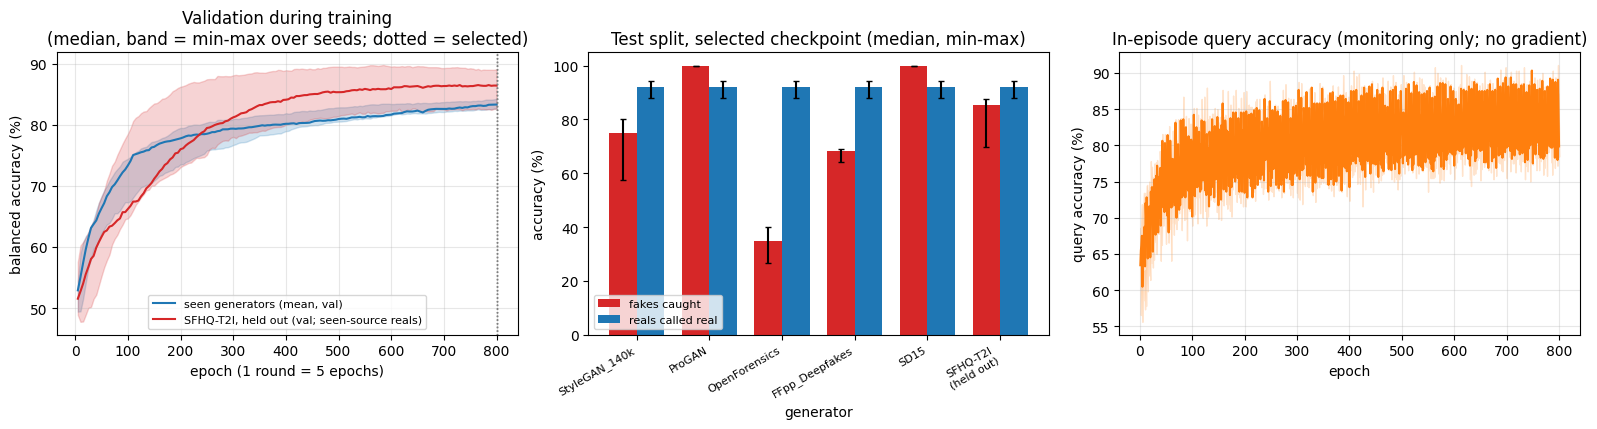

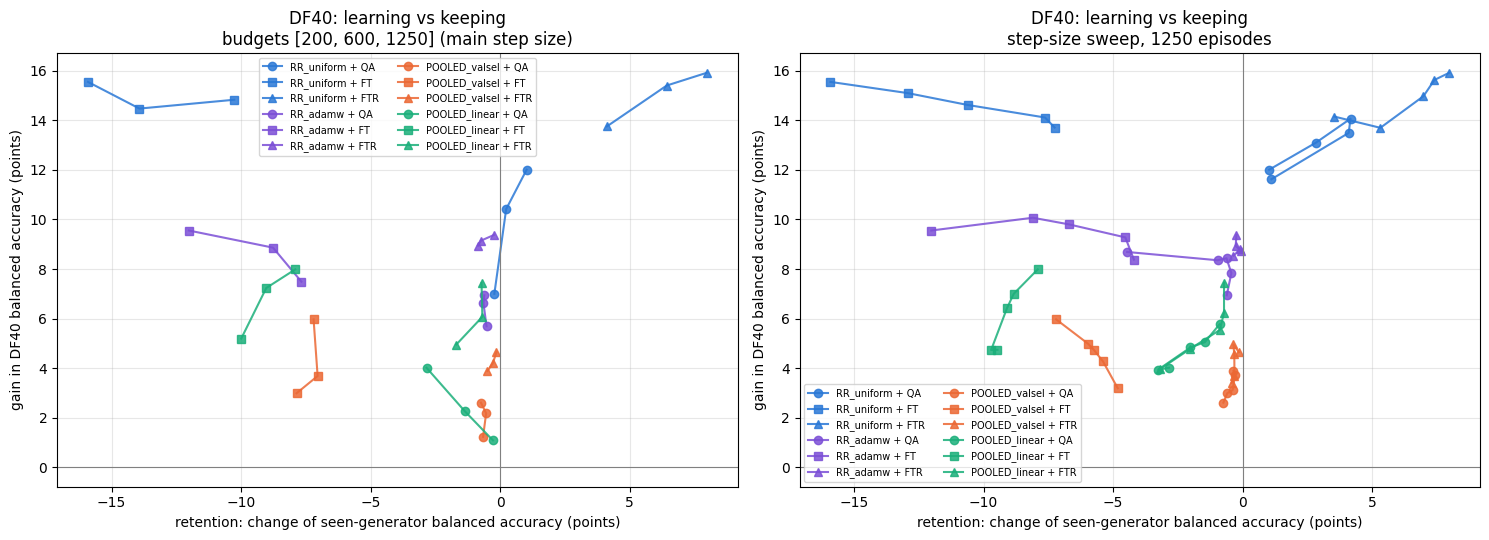

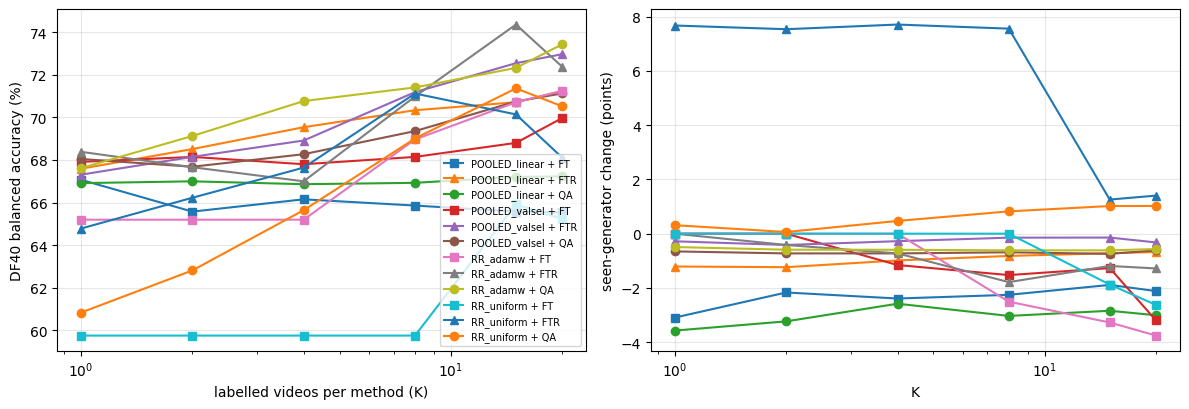

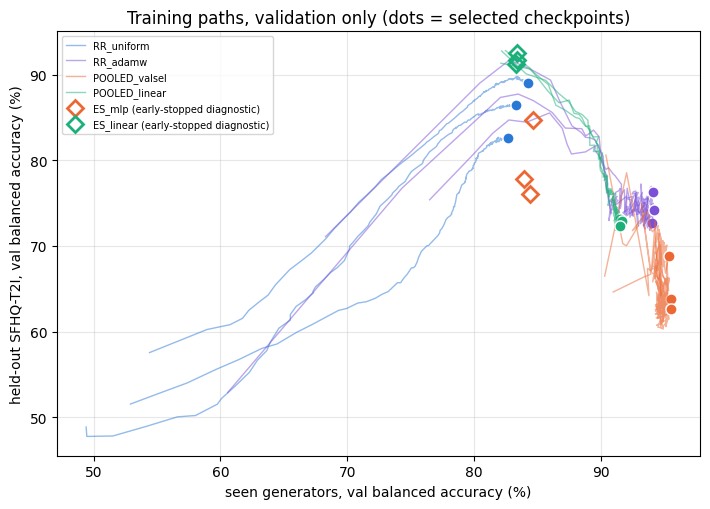

In [ ]:
# ---- Figures ----
prim = [R[k] for k in seeds_of(PRIMARY_ARM)]
if prim:
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
    ep = [h["epoch"] for h in prim[0]["history"]]
    for key, lab, col in (("seen_val", "seen generators (mean, val)", "C0"), ("heldout_val", "SFHQ-T2I, held out (val; seen-source reals)", "C3")):
        Y = np.array([[h[key] for h in r["history"]] for r in prim]) * 100
        ax[0].plot(ep, np.median(Y, 0), color=col, label=lab); ax[0].fill_between(ep, Y.min(0), Y.max(0), color=col, alpha=0.2)
    for r in prim: ax[0].axvline(r["best_epoch"], color="grey", ls=":", lw=1)
    ax[0].set(xlabel=f"epoch (1 round = {len(POOLS.gens)} epochs)", ylabel="balanced accuracy (%)",
              title="Validation during training\n(median, band = min-max over seeds; dotted = selected)"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
    gens = POOLS.gens + ["heldout"]; w = 0.38
    for j, (key, lab, col) in enumerate((("fake_acc", "fakes caught", "C3"), ("real_acc", "reals called real", "C0"))):
        vals = [[r["test_selected"][g][key] * 100 for r in prim] for g in gens]
        med = [np.median(v) for v in vals]
        ax[1].bar(np.arange(len(gens)) + (j - .5) * w, med, w, yerr=[[m_ - min(v) for m_, v in zip(med, vals)], [max(v) - m_ for m_, v in zip(med, vals)]],
                  color=col, capsize=2, label=lab)
    ax[1].set_xticks(range(len(gens))); ax[1].set_xticklabels(POOLS.gens + ["SFHQ-T2I\n(held out)"], rotation=30, ha="right", fontsize=8)
    ax[1].set(ylabel="accuracy (%)", xlabel="generator", ylim=(0, 105), title="Test split, selected checkpoint (median, min-max)"); ax[1].legend(fontsize=8)
    Q = np.array([r["query_acc"] for r in prim]) * 100
    ax[2].plot(range(1, Q.shape[1] + 1), np.median(Q, 0), color="C1"); ax[2].fill_between(range(1, Q.shape[1] + 1), Q.min(0), Q.max(0), color="C1", alpha=.2)
    ax[2].set(xlabel="epoch", ylabel="query accuracy (%)", title="In-episode query accuracy (monitoring only; no gradient)"); ax[2].grid(alpha=.3)
    plt.tight_layout(); plt.savefig(os.path.join(REPORT_DIR, "fig1_training.png"), dpi=200); plt.show()

if len(FLAT) and video_targets:
    tn = video_targets[0]; mk = {"QA": "o", "FT": "s", "FTR": "^"}; cols = {"RR_uniform": "#2a78d6", "RR_adamw": "#7b4fd6", "POOLED_valsel": "#eb6834", "POOLED_linear": "#1baf7a"}
    fig, axs = plt.subplots(1, 2, figsize=(15, 5.5))
    for arm, col in cols.items():                       # left: budgets 200 -> 600 -> 1250 at the main step size
        m = FLAT[(FLAT.target == tn) & (FLAT.arm == arm) & (FLAT.K == K_MAIN) & (FLAT["mode"] == "none") & FLAT.is_main]
        for meth in ("QA", "FT", "FTR"):
            g = m[m.method == meth].groupby("budget")[["seen_bal_chg", "d_bal"]].median()
            if len(g): axs[0].plot(g["seen_bal_chg"], 100 * g["d_bal"], marker=mk[meth], color=col, label=f"{arm} + {meth}", alpha=.85)
        m = FLAT[(FLAT.target == tn) & (FLAT.arm == arm) & (FLAT.K == K_MAIN) & (FLAT["mode"] == "none") & (FLAT.budget == BUD)]
        for meth in ("QA", "FT", "FTR"):                 # right: step-size sweep at the longest budget
            g = m[m.method == meth].groupby("scale")[["seen_bal_chg", "d_bal"]].median().sort_index()
            if len(g) > 1: axs[1].plot(g["seen_bal_chg"], 100 * g["d_bal"], marker=mk[meth], color=col, label=f"{arm} + {meth}", alpha=.85)
    for a_, t_ in zip(axs, (f"budgets {A['budgets']} (main step size)", f"step-size sweep, {BUD} episodes")):
        a_.axvline(0, color="grey", lw=.8); a_.axhline(0, color="grey", lw=.8); a_.grid(alpha=.3); a_.legend(fontsize=7, ncol=2)
        a_.set(xlabel="retention: change of seen-generator balanced accuracy (points)", ylabel=f"gain in {tn} balanced accuracy (points)", title=f"{tn}: learning vs keeping\n{t_}")
    plt.tight_layout(); plt.savefig(os.path.join(REPORT_DIR, f"fig2_tradeoff_{tn}.png"), dpi=200); plt.show()

    m = FLAT[(FLAT.target == tn) & (FLAT["mode"] == "fixed") & (FLAT.budget == BUD) & FLAT.is_main & FLAT.arm.isin(SWEEP_ARMS)]
    if m["K"].nunique() > 1:
        fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
        for (arm, meth), g in m.groupby(["arm", "method"]):
            gg = g.groupby("K")[["bal", "seen_bal_chg"]].median()
            ax[0].plot(gg.index, 100 * gg["bal"], marker=mk[meth], label=f"{arm} + {meth}"); ax[1].plot(gg.index, gg["seen_bal_chg"], marker=mk[meth], label=f"{arm} + {meth}")
        ax[0].set(xlabel="labelled videos per method (K)", ylabel=f"{tn} balanced accuracy (%)", xscale="log"); ax[1].set(xlabel="K", ylabel="seen-generator change (points)", xscale="log")
        for a_ in ax: a_.grid(alpha=.3)
        ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig(os.path.join(REPORT_DIR, f"fig3_ksweep_{tn}.png"), dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(7.2, 5.2))
for arm, col in (("RR_uniform", "#2a78d6"), ("RR_adamw", "#7b4fd6"), ("POOLED_valsel", "#eb6834"), ("POOLED_linear", "#1baf7a")):
    for i, k in enumerate(seeds_of(arm)):
        h = R[k]["history"]; s = next(x for x in h if x["epoch"] == R[k]["best_epoch"])
        ax.plot([x["seen_val"] * 100 for x in h], [x["heldout_val"] * 100 for x in h], color=col, alpha=.5, lw=1, label=arm if i == 0 else None)
        ax.plot(s["seen_val"] * 100, s["heldout_val"] * 100, "o", color=col, mec="white", ms=8)
for arm, col in (("ES_mlp", "#eb6834"), ("ES_linear", "#1baf7a")):
    for i, k in enumerate(seeds_of(arm)):
        s = next(x for x in R[k]["history"] if x["epoch"] == R[k]["best_epoch"])
        ax.plot(s["seen_val"] * 100, s["heldout_val"] * 100, "D", mfc="none", mec=col, mew=2, ms=8, label=f"{arm} (early-stopped diagnostic)" if i == 0 else None)
ax.set(xlabel="seen generators, val balanced accuracy (%)", ylabel="held-out SFHQ-T2I, val balanced accuracy (%)",
       title="Training paths, validation only (dots = selected checkpoints)"); ax.grid(alpha=.3); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(REPORT_DIR, "fig4_training_paths.png"), dpi=200); plt.show()

In [ ]:
# ---- Completeness: every expected result exists and passes the integrity rule ----
EXPECTED = set()
for arm in ARMS:
    for s in CFG["seeds"]: EXPECTED.add(("base", arm, s, ""))
for _, tn, arm, s_, K, _m, tag in planned_suites(): EXPECTED.add((tn, resolve(arm, s_) or f"{arm}(unresolved)", s_, tag))
HAVE = {("base", a, s, "") for (a, s) in R} | {(x["target"], x["real_arm"], x["seed"], x["tag"]) for x in ADF}
missing = sorted(EXPECTED - HAVE, key=str)
print(f"COMPLETENESS: {len(EXPECTED) - len(missing)}/{len(EXPECTED)} distinct expected results present and valid" + ("" if not missing else f"; MISSING: {missing}"))
save_json(dict(expected=len(EXPECTED), missing=missing, stale=stale, excluded_base=_bad_base), os.path.join(REPORT_DIR, "completeness.json"))

COMPLETENESS: 207/207 distinct expected results present and valid


In [ ]:
# ---- Methods facts (paste-able; generated from CFG and the logs) ----
_tg0 = TARGETS.get(video_targets[0]) if video_targets else None
facts = [
    f"Features: {FEATURE_EXTRACTOR}; every image to a canonical {CS}x{CS} centre crop before augmentation; features extracted once by this notebook ({blob.get('created', '')}, {blob.get('gpu', '')}).",
    f"Kaggle data: {N_ITEMS} images; caps {CFG['fake_cap']} fakes per generator and {CFG['real_cap_per_source']} reals per source (crc32-ranked); 70/15/15 train/val/test split by crc32 of "
    f"family groups (FF++ video pairs; same-source images with CLIP cosine >= {CFG['family_cos']}; cross-source near-duplicates >= {NEAR_DUP}); fingerprint {FINGERPRINT[:12]}.",
    f"Training generators: {', '.join(POOLS.gens)}; held-out generator: {CFG['held_out']} ({', '.join(sorted(HO_MODELS))}; SDXL excluded; {len(HO_EXCLUDE)} near-duplicates of training images excluded), "
    "never used in training; it has no reals of its own, so it is scored against the seen sources' test reals and, separately, against never-seen LFW reals.",
    f"Augmentation (uniform = main setting): Gaussian blur p={AUGC['blur_p']} (k in {AUGC['blur_kernels']}, sigma in {AUGC['blur_sigma']}), JPEG p={AUGC['jpeg_p']} "
    f"(q in {AUGC['jpeg_q']}), {NV} precomputed views per image; measured blur {AUG_PROOF['frac_blur']:.3f}, JPEG {AUG_PROOF['frac_jpeg']:.3f}. "
    "Category-aware (ablation): the same on GAN fakes only. Evaluation always uses the clean view.",
    f"Reptile: {CFG['episodes_per_epoch']} episodes/epoch, K={CFG['k_shot']}+{CFG['k_shot']} support, I={CFG['inner_steps']} SGD steps (momentum {CFG['inner_momentum']}, "
    f"gradient-norm clip {CFG['grad_clip']}) at eta_inner={CFG['inner_lr']} on a clone; outer update theta <- theta + eps_R (mean of clones - theta), eps_R={CFG['reptile_eps']}; "
    f"{CFG['epochs']} epochs = {CFG['epochs'] * CFG['episodes_per_epoch'] * CFG['inner_steps']} gradient steps. The {CFG['q_shot']}+{CFG['q_shot']} query images get no gradient (monitoring only).",
    f"Reptile + AdamW (RR_adamw): pseudo-gradient theta - mean(clones) given to AdamW (lr {CFG['outer_adamw']['lr']}, weight decay {CFG['outer_adamw']['weight_decay']}, cosine over {CFG['epochs']} epochs); eps_R unused (Adam is scale-invariant).",
    f"Definitions: eta_inner = learning rate of the inner SGD steps (clone only); eps_R = Reptile interpolation coefficient; Quick-Adapt uses its own lr {A['inner_lr']} and eps {A['eps']}.",
    f"Pooled: AdamW (weight decay {CFG['pooled']['weight_decay']}, cosine), batches of {CFG['k_shot']} real + {CFG['k_shot']} fake, same number of gradient steps; learning rates "
    f"{[ARMS[a]['lr'] for a in POOLED_LR_ARMS]}; POOLED_valsel = the rate with the best seen-generator validation accuracy per seed ({VALSEL}); linear probe lr {ARMS['POOLED_linear']['lr']}; reuse8 = each batch used for 8 steps.",
    f"Selection: best mean balanced accuracy over the seen generators on the val split, every {CFG['eval_every_epochs']} epochs. Early-stopped diagnostics stop at the first 10-step check "
    f"where seen-val reaches {globals().get('ES_THRESHOLD', float('nan')):.4f} (median best seen-val of RR_uniform).",
    f"Adaptation: {A['episodes']} episodes; budgets {A['budgets']}; QA = alternating target/replay episodes, {A['inner_steps']} SGD steps (lr {A['inner_lr']}, momentum 0.9) on a clone, "
    f"theta <- theta + eps (clone - theta), eps={A['eps']} (sweep {CFG['eps_sweep']}); FT = SGD lr {A['ft_lr']} x s (s=1; sweep {CFG['lr_scale_sweep']}) momentum {A['ft_momentum']} on target batches, "
    f"same number of target steps; FTR = FT + one replay batch after every target batch (same target and replay steps as QA). Replay batches: 8 real + 8 fake from the Kaggle train split. "
    f"Rollback: fixed = {A['rollback_fixed']:.2f} drop of seen-val balanced accuracy; zs = {A['zs_rule']['tight']:.2f} if the base model's zero-shot AUC on the labelled support set >= "
    f"{A['zs_rule']['cut_auc']} else {A['zs_rule']['relaxed']:.2f}; on violation the last checkpoint within the threshold is returned. Checks every {A['eval_every']} episodes.",
    (f"DF40: {', '.join(f'{e} [{k}]' for e, k in DF40['engines'].items())}; Celeb-DF domain; Celeb-real reals only (YouTube-real and HeyGen not used); identity-disjoint split "
     f"(crc32 of the Celeb-DF identity: {DF40['split_pct'][0]}% support pool / {DF40['split_pct'][1] - DF40['split_pct'][0]}% val / rest test); {DF40['frames_per_video']} frames per video; "
     f"video score = mean frame probability; support K = {K_MAIN} videos per method + {K_MAIN} x {TARGETS['DF40'].mult['real_cdf']} real videos; metric = mean over methods.") if "DF40" in TARGETS else "DF40: not run.",
    f"Seeds {CFG['seeds']}; support draws {A['draws']} (the same support sets for every base model and method of a seed: paired design); median [min, max]; zero-shot n = seeds, adapted n = seeds x draws.",
    "Hyperparameter origin: eta_inner, eps_R, the QA lr (0.006) and eps (0.04) and the 5-point rollback come from the original notebook of the submitted paper and were fixed "
    "(R2 notebook, 23 Sep) before DF40 was first scored (24 Sep); they were not changed after any DF40 or R3 result. The 0.90 cut follows the paper's text (tight threshold "
    "above 90 %); the relaxed 10-point value and the budgets 200/600/1,250 were set in this notebook before any R3 result. The step-size and "
    "support-size sweeps were extended after the first R3 results (eps = s = 0.5 and K = 20 added); they are descriptive and never changed the "
    "main settings (eps 0.04, s 1, K 15).",
    "Cost: feature extraction is measured in section 20.1 (camera_ready_cost.json); "
    f"one {A['episodes']}-episode adaptation on cached features: {SELF_TEST.get('results', {}).get('QA', {}).get('seconds_full_trajectory', float('nan')):.1f} s (QA).",
]
print("\n".join("- " + f for f in facts)); open(os.path.join(REPORT_DIR, "methods_facts.txt"), "w").write("\n".join(facts))

- Features: open_clip ViT-L-14 (openai), frozen, L2-normalised, 768-d; every image to a canonical 256x256 centre crop before augmentation; features extracted once by this notebook (2026-09-26 19:42, NVIDIA L4).
- Kaggle data: 57000 images; caps 9000 fakes per generator and 3000 reals per source (crc32-ranked); 70/15/15 train/val/test split by crc32 of family groups (FF++ video pairs; same-source images with CLIP cosine >= 0.97; cross-source near-duplicates >= 0.995); fingerprint cf092accfe43.
- Training generators: StyleGAN_140k, ProGAN, OpenForensics, FFpp_Deepfakes, SD15; held-out generator: SFHQ_T2I (DALLE3, FLUX1_dev, FLUX1_pro, FLUX1_schnell; SDXL excluded; 0 near-duplicates of training images excluded), never used in training; it has no reals of its own, so it is scored against the seen sources' test reals and, separately, against never-seen LFW reals.
- Augmentation (uniform = main setting): Gaussian blur p=0.5 (k in (3, 5, 7), sigma in (0.5, 1.5)), JPEG p=0.4 (q in (50, 85)), 2

4525

## 20. Camera-ready extras (added 7 Oct 2026)
Run these **after** the rest of the notebook. *Runtime → Run all* is safe: every finished run is reused (`[done]`), nothing old is retrained.

| Cell | What it does | Trains anything? | Time on an L4 |
|---|---|---|---|
| 20.1 | CLIP feature-extraction cost: what the DF40 feature build recorded, plus a fresh controlled timing on 256 DF40 frames | no | about 1 min |
| 20.2 | **Optional** (`RUN_SFHQ_K_SWEEP = True`): support-size sweep on the held-out *image* generator, K = 1, 2, 4, 8, 16 labelled images per class (K = 20 exists) | adaptation runs only | about 3.5 h |
| 20.3 | **Optional** (`RUN_EPISODE_K_SWEEP = True`): Reviewer 3's literal question, the Reptile base trained with k = 1, 2, 4, 16 real + k fake images per episode (k = 8 is the main model) | 12 base runs | about 1.5 h (6.5 min per run) |
| 20.4 | Writes everything the camera-ready figures and text need to `report/camera_ready_export.json` | no | seconds |

Then download `MyDrive/RREFL_R3/report/camera_ready_export.json` and send it back.
Nothing here changes a stored result: the optional runs are written to new files only (`adapt_SFHQ_K{K}_main.json`, `runs_episode_k/`).

In [ ]:
# ---- 20.1 CLIP feature-extraction cost (report-only) ----
# (a) What the DF40 feature build recorded: CLIP forward time only, one call per video (up to 16 frames), fp16 autocast.
# (b) A fresh, controlled measurement: N frames from one DF40 zip. The bytes are read first (Drive I/O is not timed), then
#     decode + canonical 256 crop (CPU) and CLIP ViT-L/14 (GPU) after a warm-up, synchronised, at batch 16 (one video) and 32.
COST_CR = {}
if RUN_DF40 and "df40_blob" in globals():
    COST_CR["df40_build"] = dict(gpu=df40_blob.get("gpu"), n_frames=int(df40_blob["n_frames"]), n_videos=len(df40_blob["videos"]),
                                 encode_seconds=float(df40_blob["encode_seconds"]), total_seconds=float(df40_blob["seconds"]),
                                 clip_ms_per_frame=1000 * float(df40_blob["encode_seconds"]) / int(df40_blob["n_frames"]))
_zips = [os.path.join(DF40[k_], f"{e}.zip") for k_ in ("drive_dir", "local_dir") for e in DF40["engines"]]
_zip = next((p for p in _zips if os.path.exists(p)), None)
if _zip is None:
    print("no DF40 zip found: skipping the fresh timing")
else:
    N_TIME = 32 if SMOKE_TEST else 256
    with zipfile.ZipFile(_zip) as z:
        _names = [n for n in z.namelist() if n.lower().endswith(IMG_EXT) and "/frames/" in n][:N_TIME]
        _raw = [z.read(n) for n in _names]
    t0 = time.perf_counter(); _ims = [canonical(Image.open(io.BytesIO(b))) for b in _raw]; _t_pre = (time.perf_counter() - t0) / len(_ims)
    encode(_ims[:16])                                                      # warm-up
    _t_clip = {}
    for bs in (16, 32):
        if DEVICE == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        for s in range(0, len(_ims), bs): encode(_ims[s:s + bs])
        if DEVICE == "cuda": torch.cuda.synchronize()
        _t_clip[bs] = (time.perf_counter() - t0) / len(_ims)
    COST_CR["fresh"] = dict(gpu=GPU_NAME, n_frames=len(_ims), source=os.path.basename(_zip), decode_crop_ms_per_frame=1000 * _t_pre,
                            clip_ms_per_frame_batch16=1000 * _t_clip[16], clip_ms_per_frame_batch32=1000 * _t_clip[32],
                            seconds_per_16_frame_video=16 * (_t_pre + _t_clip[16]))
save_json(COST_CR, os.path.join(REPORT_DIR, "camera_ready_cost.json"))
print(json.dumps(COST_CR, indent=1))

{
 "df40_build": {
  "gpu": "NVIDIA L4",
  "n_frames": 25500,
  "n_videos": 1602,
  "encode_seconds": 249.49756407737732,
  "total_seconds": 252.55500650405884,
  "clip_ms_per_frame": 9.784218199112836
 },
 "fresh": {
  "gpu": "NVIDIA L4",
  "n_frames": 256,
  "source": "inswap.zip",
  "decode_crop_ms_per_frame": 1.7858943906361446,
  "clip_ms_per_frame_batch16": 9.10968023046621,
  "clip_ms_per_frame_batch32": 8.75979551170758,
  "seconds_per_16_frame_video": 0.17432919393763768
 }
}


In [ ]:
# ---- 20.2 OPTIONAL: support-size sweep on the held-out IMAGE generator (Reviewer 3: "1 to about 20 shots", counted in images) ----
# K labelled SFHQ-T2I fakes + K reals per support set. The generator has no reals of its own, so the support reals are shared
# seen-source TRAIN reals (as in section 18). QA / FT / FTR at matched steps, 1,250 episodes, 3 support draws per seed.
# K = 20 already exists. If reported, say: the Reptile head starts at about 0.94 AUC here (near the ceiling), and the support reals are not new.
RUN_SFHQ_K_SWEEP = False
SFHQ_K_SWEEP = [1, 3] if SMOKE_TEST else [1, 2, 4, 8, 16]
SFHQ_SWEEP_ARMS = ["RR_uniform", "RR_adamw", "POOLED_valsel"]
if RUN_SFHQ_K_SWEEP and BASE:
    TARGETS.setdefault("SFHQ", ImageTarget(POOLS))
    for arm_name in SFHQ_SWEEP_ARMS:
        for seed in CFG["seeds"]:
            for K in SFHQ_K_SWEEP: run_suite("SFHQ", arm_name, seed, K, MAIN_METHODS, f"K{K}_main")

def ksweep_rows(tname, arms, Ks, mode):
    """One row per (arm, seed, draw, method) at the longest budget, read from the stored adaptation files."""
    bud, out = max(A["budgets"]), []
    for arm in arms:
        for seed in CFG["seeds"]:
            real = resolve(arm, seed)
            for K in Ks:
                fp = os.path.join(base_dir(real, seed), f"adapt_{tname}_K{K}_main.json") if real else ""
                if not os.path.exists(fp): continue
                x = load_json(fp); sg = x.get("sig", {})
                if x.get("smoke") != SMOKE_TEST or sg.get("code") != ADAPT_CODE or sg.get("fingerprint") != FINGERPRINT: continue
                b = x["before"]
                for r_ in x["rows"]:
                    if r_["budget"] == bud and r_["mode"] == mode:
                        out.append(dict(arm=arm, seed=seed, K=K, method=r_["method"], auc=r_["target"]["auc"], zs_auc=b["target"]["auc"],
                                        seen_chg=100 * (r_["seen"]["bal_acc"] - b["seen"]["bal_acc"]), fired=r_["stopped_at"] is not None))
    return pd.DataFrame(out)

_Ks = sorted(set(SFHQ_K_SWEEP) | {A["sfhq_k_per_class"]})
for _mode in ("fixed", "none"):
    _d = ksweep_rows("SFHQ", SFHQ_SWEEP_ARMS, _Ks, _mode)
    if not len(_d): continue
    _t = _d.groupby(["arm", "method", "K"]).apply(lambda g: f"{np.median(g.auc):.3f} [{g.auc.min():.3f}, {g.auc.max():.3f}] ({int(g.fired.sum())}/{len(g)})")
    print(f"\nSFHQ-T2I AUC, median [min, max] over seeds x draws (rollback fired / runs), mode = {_mode}:")
    print(_t.unstack("K").to_string())
    _z = _d.groupby("arm").zs_auc.agg(["median", "min", "max"]); print("zero-shot AUC per base:\n" + _z.round(3).to_string())


SFHQ-T2I AUC, median [min, max] over seeds x draws (rollback fired / runs), mode = fixed:
K                                             20
arm           method                            
POOLED_valsel FT      0.980 [0.782, 0.998] (5/9)
              FTR     0.983 [0.968, 0.992] (0/9)
              QA      0.978 [0.958, 0.987] (0/9)
RR_adamw      FT      0.890 [0.889, 0.906] (9/9)
              FTR     0.989 [0.890, 0.998] (7/9)
              QA      0.993 [0.988, 0.995] (0/9)
RR_uniform    FT      0.942 [0.932, 0.959] (9/9)
              FTR     0.959 [0.932, 0.998] (7/9)
              QA      0.998 [0.996, 0.999] (3/9)
zero-shot AUC per base:
               median    min    max
arm                                
POOLED_valsel   0.801  0.782  0.823
RR_adamw        0.890  0.889  0.906
RR_uniform      0.942  0.932  0.959

SFHQ-T2I AUC, median [min, max] over seeds x draws (rollback fired / runs), mode = none:
K                                             20
arm           method       

/tmp/ipykernel_1790/1376119142.py:36: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  _t = _d.groupby(["arm", "method", "K"]).apply(lambda g: f"{np.median(g.auc):.3f} [{g.auc.min():.3f}, {g.auc.max():.3f}] ({int(g.fired.sum())}/{len(g)})")
/tmp/ipykernel_1790/1376119142.py:36: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  _t = _d.groupby(["arm", "method", "K"]).apply(lambda g: f"{np.median(g.auc):.3f} [{g.auc

In [ ]:
# ---- 20.3 OPTIONAL (Reviewer 3, literal): episode size. The Reptile base (RR_uniform recipe) trained with k real + k fake images
# per episode, k = 1, 2, 4, 16 (k = 8 is the main model). Everything else is identical, including the 128,000 inner gradient steps.
# Selection on seen-generator validation only; the test split is read once, afterwards. Written to runs_episode_k/ (new files only).
RUN_EPISODE_K_SWEEP = False
EPISODE_KS = [2] if SMOKE_TEST else [1, 2, 4, 16]
EK_DIR = os.path.join(ROOT, "runs_episode_k"); os.makedirs(EK_DIR, exist_ok=True)

def run_episode_k(k, seed):
    d = os.path.join(EK_DIR, f"{PRIMARY_ARM}_k{k}__s{seed}"); os.makedirs(d, exist_ok=True); rp = os.path.join(d, "result.json")
    if os.path.exists(rp):
        old = load_json(rp)
        if old.get("fingerprint") == FINGERPRINT and old.get("code") == BASE_CODE and old.get("smoke") == SMOKE_TEST:
            print(f"[done] episode size k={k} s{seed}"); return old
    k0, lock = CFG["k_shot"], TestLock()
    try:
        CFG["k_shot"] = k                         # train_base reads CFG["k_shot"] when it is called; nothing else changes
        tr = train_base(ARMS[PRIMARY_ARM], seed, POOLS, lock, log_prefix=f"{PRIMARY_ARM} k={k} s{seed}")
    finally:
        CFG["k_shot"] = k0                        # restored at once: later cells compare CFG with the stored runs
    steps = CFG["epochs"] * CFG["episodes_per_epoch"] * CFG["inner_steps"]
    assert tr["counters"]["grad_steps"] == steps and tr["counters"]["sample_grads"] == steps * 2 * k, "budget not as specified"
    assert tr["sampler"].episodes_per_gen.get(POOLS.held_out, 0) == 0, "the held-out generator was trained on"
    lock.open = True                                                         # ---- reporting only from here ----
    mb, mf = model_from(tr["best_state"]), model_from(tr["final_state"])
    sel, fin = eval_base(mb, POOLS, "test", lock), eval_base(mf, POOLS, "test", lock)
    v0, vb = params_vec(model_from(tr["init_state"])), params_vec(mb)
    df = TARGETS["DF40"].evaluate(mb, "test", lock) if "DF40" in TARGETS else None
    res = dict(k=k, seed=seed, arm=PRIMARY_ARM, fingerprint=FINGERPRINT, code=BASE_CODE, smoke=SMOKE_TEST, best_epoch=tr["best_epoch"],
               best_val_seen=tr["best_val_seen"], history=tr["history"], test_selected=sel, test_final=fin,
               dist_from_init=float((vb - v0).norm()), df40_zero_shot=None if df is None else dict(auc=df["auc"], bal_acc=df["bal_acc"]),
               lfw=lfw_metrics(mb, lock), counters=tr["counters"], train_seconds=tr["train_seconds"], gpu=GPU_NAME)
    save_json(res, rp)
    print(f"{PRIMARY_ARM} k={k} s{seed}: best epoch {tr['best_epoch']}, seen-test bal {sel['seen_bal_acc']:.3f}, "
          f"held-out bal {sel['heldout']['bal_acc']:.3f} AUC {sel['heldout']['auc']:.3f} | {tr['train_seconds'] / 60:.1f} min")
    return res

EK = {}
if RUN_EPISODE_K_SWEEP and BASE:
    for k in EPISODE_KS:
        for seed in CFG["seeds"]: EK[(k, seed)] = run_episode_k(k, seed)
for p in glob.glob(os.path.join(EK_DIR, "*", "result.json")):            # also pick up runs finished in earlier sessions
    r_ = load_json(p)
    if r_.get("fingerprint") == FINGERPRINT and r_.get("code") == BASE_CODE and r_.get("smoke") == SMOKE_TEST: EK[(r_["k"], r_["seed"])] = r_

if EK:
    def _k_recs(k):
        if k == CFG["k_shot"]:
            return [dict(sel=R[(PRIMARY_ARM, s)]["test_selected"], dist=R[(PRIMARY_ARM, s)]["dist_from_init"], best=R[(PRIMARY_ARM, s)]["best_epoch"],
                         df40=BEFORE.get(("DF40", PRIMARY_ARM, s), {}).get("target", {}).get("auc"),
                         lfw=LFWR.get((PRIMARY_ARM, s), {}).get("selected", {}).get("lfw_real_acc")) for s in CFG["seeds"] if (PRIMARY_ARM, s) in R]
        return [dict(sel=r_["test_selected"], dist=r_["dist_from_init"], best=r_["best_epoch"], df40=(r_["df40_zero_shot"] or {}).get("auc"),
                     lfw=r_["lfw"].get("lfw_real_acc")) for (kk, s), r_ in sorted(EK.items()) if kk == k]
    _rows = []
    for k in sorted({CFG["k_shot"]} | {k for k, _ in EK}):
        rec = _k_recs(k)
        if rec:
            _rows.append({"k (per class)": k, "seen bal.": mmm([x["sel"]["seen_bal_acc"] for x in rec]),
                          "held-out bal.": mmm([x["sel"]["heldout"]["bal_acc"] for x in rec]), "held-out AUC": mmm([x["sel"]["heldout"]["auc"] for x in rec]),
                          "held-out fakes caught": mmm([x["sel"]["heldout"]["fake_acc"] for x in rec]), "LFW reals called real": mmm([x["lfw"] for x in rec]),
                          "DF40 zero-shot AUC": mmm([x["df40"] for x in rec]), "distance": mmm([x["dist"] for x in rec]), "best epoch": mmm([x["best"] for x in rec])})
    print("Episode size (Reptile base, test split, selected checkpoint):")
    print(pd.DataFrame(_rows).to_string(index=False))

In [ ]:
# ---- 20.4 Export for the camera-ready (report-only): base-run logs (Fig. 1), adaptation rows, cost, optional sweeps ----
def _cls(m): return {k: m[k] for k in ("real_acc", "fake_acc", "bal_acc", "auc", "n_real", "n_fake")}
def _base_entry(r):
    ts, tf = r["test_selected"], r["test_final"]
    return dict(best_epoch=r["best_epoch"], best_val_seen=r["best_val_seen"], dist_from_init=r["dist_from_init"],
                history=[{k: h[k] for k in ("epoch", "seen_val", "heldout_val", "seen_val_auc", "heldout_val_auc")} for h in r["history"]],
                test_selected=dict({g: _cls(ts[g]) for g in POOLS.gens + ["heldout"]}, seen_bal_acc=ts["seen_bal_acc"], seen_auc=ts["seen_auc"]),
                test_final=dict({g: _cls(tf[g]) for g in POOLS.gens + ["heldout"]}, seen_bal_acc=tf["seen_bal_acc"], seen_auc=tf["seen_auc"]))

EXPORT = dict(created=time.strftime("%Y-%m-%d %H:%M"), smoke=SMOKE_TEST, fingerprint=FINGERPRINT, base_code=BASE_CODE, adapt_code=ADAPT_CODE,
              gens=POOLS.gens, held_out=POOLS.held_out, seeds=CFG["seeds"], valsel={str(s): a for s, a in VALSEL.items()},
              cost=globals().get("COST_CR", {}),
              base={f"{a}__s{s}": dict(arm=a, seed=s, lfw=LFWR.get((a, s), {}), **_base_entry(r)) for (a, s), r in sorted(R.items())},
              episode_k={f"k{k}__s{s}": dict(k=k, seed=s, df40_zero_shot=r["df40_zero_shot"], lfw=r["lfw"], train_seconds=r["train_seconds"],
                                             **_base_entry(r)) for (k, s), r in sorted(globals().get("EK", {}).items())},
              adapt=[])
for p in sorted(glob.glob(os.path.join(RUNS_DIR, "*", "adapt_*.json"))):
    x = load_json(p); sg = x.get("sig", {})
    if x.get("smoke") != SMOKE_TEST or sg.get("code") != ADAPT_CODE or sg.get("fingerprint") != FINGERPRINT: continue
    b = x["before"]
    for r_ in x["rows"]:
        if r_["budget"] != max(A["budgets"]) or r_["mode"] not in ("none", "fixed"): continue
        EXPORT["adapt"].append(dict(target=x["target"], tag=x["tag"], arm_name=x["arm_name"], real_arm=x["real_arm"], seed=x["seed"], K=x["K"],
                                    method=r_["method"], scale=r_["scale"], draw=r_["draw"], mode=r_["mode"], stopped_at=r_["stopped_at"],
                                    auc=r_["target"]["auc"], bal=r_["target"]["bal_acc"], fakes=r_["target"]["fake_acc"], reals=r_["target"]["real_acc"],
                                    seen_bal=r_["seen"]["bal_acc"], seen_auc=r_["seen"]["auc"], lfw_real=r_["lfw"].get("lfw_real_acc"),
                                    zs_auc=b["target"]["auc"], zs_bal=b["target"]["bal_acc"], zs_seen_bal=b["seen"]["bal_acc"]))
_p = os.path.join(REPORT_DIR, "camera_ready_export.json"); save_json(EXPORT, _p)
print(f"wrote {_p} ({os.path.getsize(_p) / 1e6:.1f} MB): {len(EXPORT['base'])} base runs, {len(EXPORT['episode_k'])} episode-size runs, "
      f"{len(EXPORT['adapt'])} adaptation rows")

# Quick look: how often the fixed 5-point rollback fired on DF40 at the main K, per step size (Quick-Adapt eps; FT/FTR lr multiplier)
_q = pd.DataFrame([r_ for r_ in EXPORT["adapt"] if r_["target"] == "DF40" and r_["K"] == K_MAIN and r_["mode"] == "fixed"])
if len(_q):
    _q["arm"] = [a if a in SWEEP_ARMS else ("POOLED_valsel" if VALSEL.get(s) == ra else ra)
                 for a, ra, s in zip(_q.arm_name, _q.real_arm, _q.seed)]
    _q = _q[_q.arm.isin(SWEEP_ARMS)]
    print(f"\nDF40, K = {K_MAIN}, fixed 5-point rollback: runs in which it fired / runs (columns: QA eps; FT/FTR lr multiplier)")
    print(_q.groupby(["arm", "method", "scale"]).stopped_at.apply(lambda s: f"{s.notna().sum()}/{len(s)}").unstack("scale").fillna("").to_string())

wrote /content/drive/MyDrive/RREFL_R3/report_final/camera_ready_export.json (3.3 MB): 42 base runs, 0 episode-size runs, 3618 adaptation rows

DF40, K = 15, fixed 5-point rollback: runs in which it fired / runs (columns: QA eps; FT/FTR lr multiplier)
scale                0.04 0.12 0.35 0.50 1.00
arm           method                         
POOLED_linear FT      9/9  9/9  9/9  9/9  9/9
              FTR     0/9  0/9  0/9  0/9  0/9
              QA      0/9  0/9  0/9  0/9  0/9
POOLED_valsel FT      5/9  8/9  8/9  9/9  9/9
              FTR     0/9  0/9  0/9  0/9  0/9
              QA      0/9  0/9  0/9  1/9  5/9
RR_adamw      FT      6/9  7/9  9/9  9/9  9/9
              FTR     0/9  0/9  0/9  1/9  7/9
              QA      0/9  0/9  2/9  8/9  9/9
RR_uniform    FT      6/9  9/9  9/9  9/9  9/9
              FTR     0/9  0/9  1/9  0/9  5/9
              QA      0/9  0/9  3/9  7/9  9/9


### 20.5 Two report-only checks (they train nothing)
- **When did the rollback fire?** A number "with the rollback" comes from the last check before the first drop of more than 5 points on the seen generators' *validation* split; the rollback never looks at the target. The table shows at which episode (of 1,250) it fired, the target AUC of runs where it fired vs. did not, and the same runs trained the full 1,250 episodes.
- **DeepSpeak bitrate.** The dataset card warns that reals and fakes use different codecs. Can a video's bitrate alone (bits per pixel, kbit/s) separate an engine's fakes from the reals? 0.5 = no; above 0.8 = flag it in the paper.


In [ ]:
# ---- 20.5a When did the 5-point rollback fire? (report-only) ----
_REP_ARMS = ["RR_uniform", "RR_adamw", "POOLED_valsel"]
_MORD = {"QA": 0, "FT": 1, "FTR": 2}
def _int3(v): v = [int(x) for x in v if x is not None and x == x]; return f"{int(np.median(v))} [{min(v)}, {max(v)}]" if v else "-"
recs = []
for x in ADF:
    arm = "POOLED_valsel" if VALSEL.get(x["seed"]) == x["real_arm"] else x["real_arm"]
    if arm not in _REP_ARMS or x["K"] != (A["sfhq_k_per_class"] if x["target"] == "SFHQ" else K_MAIN): continue
    by = {(r["method"], r["scale"], r["draw"], r["mode"]): r for r in x["rows"] if r["budget"] == BUD}
    for (meth, sc, dr, mode), r in by.items():
        if mode != "fixed": continue
        rn = by[(meth, sc, dr, "none")]
        recs.append(dict(target=x["target"], arm=arm, method=meth, step=sc, fired=r["stopped_at"] is not None, stop=r["stopped_at"],
                         auc_fixed=r["target"]["auc"], auc_none=rn["target"]["auc"], bal_none=rn["target"]["bal_acc"]))
if recs:
    D9 = pd.DataFrame(recs); out = []
    for (tn, arm, meth, sc), g in D9.groupby(["target", "arm", "method", "step"]):
        f, nf = g[g.fired], g[~g.fired]
        out.append(dict(target=tn, arm=arm, method=meth, step=sc, fired=f"{len(f)}/{len(g)}", **{
            "stop episode (fired runs)": _int3(list(f["stop"])),
            "AUC with rollback: fired runs": mmm(f["auc_fixed"]) if len(f) else "-",
            "AUC with rollback: not fired": mmm(nf["auc_fixed"]) if len(nf) else "-",
            "AUC, full 1,250 episodes": mmm(g["auc_none"]), "bal. acc., full 1,250 episodes": mmm(g["bal_none"])}))
    T9 = pd.DataFrame(out)
    T9 = T9.assign(_a=T9.arm.map(_REP_ARMS.index), _m=T9.method.map(_MORD)).sort_values(["target", "_a", "_m", "step"]).drop(columns=["_a", "_m"])
    T9.to_csv(os.path.join(REPORT_DIR, "T9_rollback_stop_points.csv"), index=False)
    for tn in T9.target.unique():
        print(f"\nTABLE 9 [{tn}]. When the 5-point rollback fired (episode of the first check that crossed it; the model returned is the one "
              f"from the check before). step = QA eps or FT/FTR lr multiplier.")
        print(T9[T9.target == tn].drop(columns="target").to_string(index=False))



TABLE 9 [DF40]. When the 5-point rollback fired (episode of the first check that crossed it; the model returned is the one from the check before). step = QA eps or FT/FTR lr multiplier.
          arm method  step fired stop episode (fired runs) AUC with rollback: fired runs AUC with rollback: not fired   AUC, full 1,250 episodes bal. acc., full 1,250 episodes
   RR_uniform     QA  0.04   0/9                         -                             -   0.781 [0.760, 0.795] (n=9) 0.781 [0.760, 0.795] (n=9)     0.714 [0.686, 0.731] (n=9)
   RR_uniform     QA  0.12   0/9                         -                             -   0.794 [0.783, 0.816] (n=9) 0.794 [0.783, 0.816] (n=9)     0.725 [0.692, 0.746] (n=9)
   RR_uniform     QA  0.35   3/9              60 [50, 130]    0.764 [0.727, 0.777] (n=3)   0.808 [0.796, 0.828] (n=6) 0.810 [0.796, 0.828] (n=9)     0.722 [0.674, 0.760] (n=9)
   RR_uniform     QA  0.50   7/9              40 [10, 290]    0.722 [0.645, 0.782] (n=7)   0.814 [0.808, 0.81

In [ ]:
# ---- 20.5b DeepSpeak: does bitrate alone separate real from fake? (report-only; the dataset card warns about codecs) ----
if "DeepSpeak" in TARGETS and "ds_keep" in globals() and "ds_blob" in globals():
    _idx = ds_zip_index(); _row = {r["uid"]: r for r in ds_keep}; _recs = []
    for v in ds_blob["videos"]:
        r = _row.get(v["video"]); loc = _locate(r, _idx) if r else None; m = v["meta"]
        if loc and m.get("w") and m.get("h") and m.get("n_frames") and m.get("fps"):
            _recs.append(dict(group=v["group"], label=v["label"], bpp=8 * loc[2] / (m["w"] * m["h"] * m["n_frames"]),
                              kbps=8 * loc[2] / (m["n_frames"] / m["fps"]) / 1000))
    print(f"DeepSpeak: {len(_recs)} of {len(ds_blob['videos'])} videos matched to their file sizes")
    if _recs:
        DB = pd.DataFrame(_recs); out = []
        for e in TARGETS["DeepSpeak"].engines:
            s_ = DB[DB.group.isin([e, "real"])]; row = dict(engine=e, fakes=int((s_.label == 1).sum()), reals=int((s_.label == 0).sum()))
            for k in ("bpp", "kbps"):
                a = roc_auc_score(s_.label, s_[k]) if s_.label.nunique() == 2 else float("nan"); row[f"{k} AUC"] = round(float(max(a, 1 - a)), 3)
                row[f"{k} median fake / real"] = f"{s_[s_.label == 1][k].median():.3g} / {s_[s_.label == 0][k].median():.3g}"
            out.append(row)
        T10 = pd.DataFrame(out); T10.to_csv(os.path.join(REPORT_DIR, "check_deepspeak_bitrate.csv"), index=False)
        print("DeepSpeak bitrate-only real/fake AUC per engine (0.5 = no shortcut; > 0.8 = flag in the paper):"); print(T10.to_string(index=False))
else:
    print("DeepSpeak not loaded: bitrate check skipped")


DeepSpeak: 1710 of 1710 videos matched to their file sizes
DeepSpeak bitrate-only real/fake AUC per engine (0.5 = no shortcut; > 0.8 = flag in the paper):
      engine  fakes  reals  bpp AUC bpp median fake / real  kbps AUC kbps median fake / real
    diff2lip    190    570    1.000           0.139 / 0.61     1.000     1.09e+03 / 5.26e+03
  facefusion    190    570    0.979            2.38 / 0.61     0.990     2.22e+04 / 5.26e+03
   hellomeme    190    570    0.997           0.112 / 0.61     1.000          442 / 5.26e+03
  latentsync    190    570    0.997          0.0743 / 0.61     0.998          626 / 5.26e+03
liveportrait    190    570    1.000          0.0359 / 0.61     1.000          329 / 5.26e+03
        memo    190    570    1.000          0.0507 / 0.61     1.000          398 / 5.26e+03
